In [1]:
"""Chapter 1: Python for AI Engineering

Section-aligned walkthrough: every code block from this chapter of the book,
in book order, each in its own cell under its section heading so you can run
and check them one by one. Generated from Book.md; keep the book as the source.
"""

'Chapter 1: Python for AI Engineering\n\nSection-aligned walkthrough: every code block from this chapter of the book,\nin book order, each in its own cell under its section heading so you can run\nand check them one by one. Generated from Book.md; keep the book as the source.\n'

## 1.1.1 Variables, types, and strings

The convenience of dynamic typing is also a source of bugs, a float silently flowing where an integer was meant, which is exactly what the type hints of 1.2 exist to catch.

In [2]:
learning_rate = 0.01      # float
epochs = 50               # int
model_name = "resnet"     # str
use_gpu = True            # bool
checkpoint = None         # the absence of a value

print(type(learning_rate), type(epochs), type(model_name))
# <class 'float'> <class 'int'> <class 'str'>

accuracy = 0.8723
print(f"Epoch {epochs}: {model_name} reached {accuracy:.1%} accuracy")
# Epoch 50: resnet reached 87.2% accuracy

<class 'float'> <class 'int'> <class 'str'>
Epoch 50: resnet reached 87.2% accuracy


## 1.1.2 The core containers: list, tuple, set, and dictionary

checking membership in a list scans every element, which is slow, while checking membership in a set or dictionary is effectively constant time, an idea we make precise with Big-O in 1.4.

In [3]:
batch = [0.2, 0.5, 0.9]               # list: an ordered, growable sequence
shape = (32, 3, 224, 224)             # tuple: a fixed shape, must not change
seen = {"cat", "dog", "cat"}          # set: duplicates collapse to {"cat", "dog"}
vocab = {"cat": 0, "dog": 1}          # dict: map each word to an index

batch.append(0.1)                     # lists can grow
print(batch)                          # [0.2, 0.5, 0.9, 0.1]
print(len(seen))                      # 2   the duplicate "cat" was dropped
print("dog" in seen)                  # True   constant-time membership
print(vocab["dog"])                   # 1     constant-time key lookup

[0.2, 0.5, 0.9, 0.1]
2
True
1


remove deletes the first item equal to a value, the del statement deletes by index and returns nothing, and pop removes by index (the last item by default) and returns what it removed, which is exactly what makes a list usable as the stack

In [4]:
xs = [3, 1, 2]
xs.append(4)            # add one to the end        -> [3, 1, 2, 4]
xs.extend([5, 6])       # add several               -> [3, 1, 2, 4, 5, 6]
xs.insert(0, 9)         # insert at index 0         -> [9, 3, 1, 2, 4, 5, 6]
xs.remove(9)            # delete the first 9         -> [3, 1, 2, 4, 5, 6]
last = xs.pop()         # remove and return the end -> last == 6
print(xs, "popped", last)        # [3, 1, 2, 4, 5] popped 6
print(xs.index(4), xs.count(2))  # 3 1   index of the first 4, count of 2s
xs.sort(); print(xs)             # [1, 2, 3, 4, 5]   sorts in place

[3, 1, 2, 4, 5] popped 6
3 1
[1, 2, 3, 4, 5]


A set supports the operations of mathematical set theory directly, which is what makes it the right tool for comparing collections.

In [5]:
a = {1, 2, 3, 4}
b = {3, 4, 5, 6}
print(a | b)            # {1, 2, 3, 4, 5, 6}   union: in either set
print(a & b)            # {3, 4}               intersection: in both
print(a - b)            # {1, 2}               difference: in a but not b
print(a ^ b)            # {1, 2, 5, 6}         symmetric difference: in exactly one
print({1, 2} <= a)      # True                 subset test

{1, 2, 3, 4, 5, 6}
{3, 4}
{1, 2}
{1, 2, 5, 6}
True


The setdefault method inserts a key only if it is absent, and keys, values, and items give you the dictionary's contents to iterate over, with items yielding key and value together.

In [6]:
vocab = {"cat": 0, "dog": 1}
print(vocab.get("fox"))         # None   no error on a missing key
print(vocab.get("fox", -1))     # -1     return a default instead
vocab.setdefault("fox", 2)      # insert only because "fox" is absent
for word, idx in vocab.items(): # iterate key and value at once
    print(word, idx)            # cat 0 / dog 1 / fox 2

defaults = {"lr": 0.01, "epochs": 10}
print({**defaults, "epochs": 50})   # {'lr': 0.01, 'epochs': 50}   right side wins
print(defaults | {"epochs": 50})    # same, using the 3.9+ merge operator

None
-1
cat 0
dog 1
fox 2
{'lr': 0.01, 'epochs': 50}
{'lr': 0.01, 'epochs': 50}


## 1.1.3 Control flow, loops, and comprehensions

The elif clauses, short for "else if," are tested in order only when every earlier condition failed, and the optional else catches everything left over.

In [7]:
score = 0.82
if score >= 0.9:
    grade = "A"
elif score >= 0.8:          # tested only because the first condition was False
    grade = "B"
elif score >= 0.7:
    grade = "C"
else:                       # the catch-all when nothing above matched
    grade = "F"
print(grade)                # B

B


The for loop is Python's workhorse, and its defining feature is that it iterates over the items of any iterable directly, a list, a string, a range of numbers, or the keys and values of a dictionary, without you ever managing an index by ha

In [8]:
for animal in ["cat", "dog", "fox"]:     # over the items of a list
    print(animal, end=" ")               # cat dog fox
print()                                  # end the line the loop built

for i in range(3):                       # range(n) yields 0, 1, ..., n-1
    print(i, end=" ")                    # 0 1 2
print()

for i, name in enumerate(["a", "b"], start=1):   # index and item together
    print(i, name)                       # 1 a   then   2 b

config = {"lr": 0.01, "epochs": 50}
for key, value in config.items():        # walk a dict's keys and values
    print(key, "=", value)               # lr = 0.01   then   epochs = 50

cat dog fox 
0 1 2 
1 a
2 b
lr = 0.01
epochs = 50


It is the natural shape for a process that runs until it converges, the same idea behind the training loops that stop when a loss stops improving.

In [9]:
x = 16.0
steps = 0
while x > 1.0:              # keep looping while the test holds
    x = x / 2              # Python has no x++, so rebind x explicitly
    steps += 1
print(x, "in", steps, "steps")   # 1.0 in 4 steps

1.0 in 4 steps


Loops also have an else clause that runs only if the loop finished without hitting a break, which reads as "we got all the way through."

In [10]:
for n in [4, 9, 15, 7, 20]:
    if n % 2 == 0:
        continue            # skip even numbers, move to the next n
    if n > 10:
        break               # stop the whole loop at the first large odd number
    print("odd and small:", n)   # odd and small: 9

for n in [1, 3, 5]:
    if n == 7:
        break
else:
    print("not found")      # not found   (the loop ended without a break)

odd and small: 9
not found


Comprehensions read almost like the set-builder notation of mathematics that they resemble, and they are usually a little faster than the equivalent loop, with the one caveat, developed in 1.3, that heavy numerical work belongs in vectorized array operations rather than any Python loop or comprehension.

In [11]:
scores = [0.2, 0.8, 0.5, 0.95, 0.3]

# the explicit loop: start empty, append one result per item
labels = []
for s in scores:
    labels.append("pass" if s >= 0.5 else "fail")
print(labels)            # ['fail', 'pass', 'pass', 'pass', 'fail']

# the same logic as a list comprehension, one line
labels = ["pass" if s >= 0.5 else "fail" for s in scores]
print(labels)            # ['fail', 'pass', 'pass', 'pass', 'fail']

# a comprehension that also filters: keep only the high scores, doubled
high = [s * 2 for s in scores if s >= 0.8]
print(high)              # [1.6, 1.9]

['fail', 'pass', 'pass', 'pass', 'fail']
['fail', 'pass', 'pass', 'pass', 'fail']
[1.6, 1.9]


## 1.1.4 Functions, arguments, lambda, and scope

And a misunderstanding of scope produces two classic bugs, the shared mutable default argument and the surprising closure, that are worth meeting once so you never write them.

In [12]:
def train(model, *args, lr=0.01, **kwargs):
    # lr has a default; extra positional args land in the tuple args,
    # extra keyword args land in the dict kwargs
    print(lr, args, kwargs)

train("resnet", "extra1", "extra2", lr=0.1, epochs=50, gpu=True)
# 0.1 ('extra1', 'extra2') {'epochs': 50, 'gpu': True}

# a lambda as a sort key: sort words by length
words = ["transformer", "rnn", "cnn", "attention"]
print(sorted(words, key=lambda w: len(w)))
# ['rnn', 'cnn', 'attention', 'transformer']

0.1 ('extra1', 'extra2') {'epochs': 50, 'gpu': True}
['rnn', 'cnn', 'attention', 'transformer']


Two small marks in a parameter list decide how arguments may be passed, and you will meet them in nearly every library signature you read. A bare * in the list means that every parameter after it must be passed by keyword, and a / means that every parameter before it must be passed by position.

In [13]:
def fit(X, y, /, *, lr=0.01, epochs=10):   # X and y by position only; lr and epochs by keyword only
    return f"lr={lr}, epochs={epochs}"

print(fit([1, 2], [0, 1], lr=0.1))          # lr=0.1, epochs=10
try:
    fit([1, 2], [0, 1], 0.1)                # the learning rate slipped in by position
except TypeError as e:
    print("TypeError:", e)                  # TypeError: fit() takes 2 positional arguments but 3 were given

import inspect
print(inspect.signature(sorted))            # (iterable, /, *, key=None, reverse=False)
print(inspect.signature(len))               # (obj, /)

def fit_loose(X, y, lr=0.01, epochs=10):    # no marks: every argument may travel by position
    return f"lr={lr}, epochs={epochs}"

print(fit_loose([1, 2], [0, 1], 10, 0.01))  # lr=10, epochs=0.01   silently swapped, no error

lr=0.1, epochs=10
TypeError: fit() takes 2 positional arguments but 3 were given
(iterable, /, *, key=None, reverse=False)
(obj, /)
lr=10, epochs=0.01


One pitfall deserves a demonstration rather than a warning: never use a mutable value such as a list as a default argument, because that single default is created once, when the def line runs, and then shared across every call, so it accumulates data between calls in a way that looks like a ghost.

In [14]:
def add_bad(x, acc=[]):        # the default list is built ONCE, when def runs
    acc.append(x)
    return acc

print(add_bad(1))              # [1]
print(add_bad(2))              # [1, 2]   the same list again, still holding the 1

def add_good(x, acc=None):     # the safe pattern: default to None...
    if acc is None:
        acc = []               # ...and build a fresh list inside the call
    acc.append(x)
    return acc

print(add_good(1))             # [1]
print(add_good(2))             # [2]      a new list each time

[1]
[1, 2]
[1]
[2]


The demonstration builds three adder functions in a loop and then calls them.

In [15]:
adders = [lambda x: x + i for i in range(3)]        # three closures over the SAME i
print([f(10) for f in adders])      # [12, 12, 12]  every one sees i's final value, 2

adders = [lambda x, i=i: x + i for i in range(3)]   # freeze each i as a default
print([f(10) for f in adders])      # [10, 11, 12]  the three intended adders

[12, 12, 12]
[10, 11, 12]


## 1.1.5 Slicing, everyday built-ins, and imports

This is how you take the first ten rows, the last column, or every other element, and the same notation extends to NumPy arrays and pandas frames in 1.5, so fluency now pays off later.

In [16]:
xs = [10, 20, 30, 40, 50]
print(xs[1:4])     # [20, 30, 40]   index 1 up to but not including 4
print(xs[:3])      # [10, 20, 30]   the first three
print(xs[-2:])     # [40, 50]       the last two
print(xs[::-1])    # [50, 40, 30, 20, 10]   reversed, a step of -1

[20, 30, 40]
[10, 20, 30]
[40, 50]
[50, 40, 30, 20, 10]


The functional pair map and filter apply a function across a sequence or keep the items that pass a test, demonstrated after the everyday set below.

In [17]:
names = ["cat", "dog", "fox"]
scores = [0.9, 0.4, 0.7]

for i, name in enumerate(names):
    print(i, name)                  # 0 cat / 1 dog / 2 fox
for name, score in zip(names, scores):
    print(name, score)              # cat 0.9 / dog 0.4 / fox 0.7

print(sum(scores), max(scores))     # 2.0 0.9
print(sorted(scores, reverse=True)) # [0.9, 0.7, 0.4]

0 cat
1 dog
2 fox
cat 0.9
dog 0.4
fox 0.7
2.0 0.9
[0.9, 0.7, 0.4]


map(f, seq) applies the function f to every item, and filter(test, seq) keeps only the items for which test returns true; both return lazy iterators, which is why the demonstrations below wrap them in list to see the contents.

In [18]:
nums = [1, 2, 3, 4]
print(list(map(lambda x: x * x, nums)))          # [1, 4, 9, 16]   apply f to every item
print(list(filter(lambda x: x % 2 == 0, nums)))  # [2, 4]          keep the items that pass

print([x * x for x in nums])                     # [1, 4, 9, 16]   the comprehension says the same
print([x for x in nums if x % 2 == 0])           # [2, 4]

[1, 4, 9, 16]
[2, 4]
[1, 4, 9, 16]
[2, 4]


You can import a whole module, a single name from it, or rename it on the way in, and the short names the community has standardized on, such as np for NumPy, appear in every example in this book.

In [19]:
import math                       # a standard-library module
from collections import Counter   # one name from a module
import statistics as stats        # rename on import

print(math.sqrt(16))              # 4.0
print(Counter("banana"))          # Counter({'a': 3, 'n': 2, 'b': 1})
print(stats.mean([1, 2, 3, 4]))   # 2.5

4.0
Counter({'a': 3, 'n': 2, 'b': 1})
2.5


## 1.1.6 Strings in depth: the methods you will use

By hand, the rule is a character count: "a\tb" holds three characters, the letter a, one tab, and the letter b, while r"a\tb" holds four, because the raw prefix keeps the backslash and the t as two separate characters.

In [20]:
print("loss\t0.25\nacc\t0.91")          # \t is a tab, \n starts a new line
print(len("a\tb"), len(r"a\tb"))         # 3 4   an escape is one character; raw keeps two
print("C:\\data\\train.csv")             # C:\data\train.csv   \\ stands for one backslash
print(r"\d+")                            # \d+   a raw string keeps the backslash for re
note = """first line
second line"""                           # triple quotes let a string span lines
print(note)                              # first line, then second line
print(note.count("\n"))                  # 1   the line break is stored as one \n character

loss	0.25
acc	0.91
3 4
C:\data\train.csv
\d+
first line
second line
1


Start with the methods that change case, trim whitespace, and test what a string contains.

In [21]:
s = "Hello, World"
print(len(s))                 # 12
print(s.upper())              # HELLO, WORLD
print(s.lower())              # hello, world
t = s.replace("World", "AI")
print(s)                      # Hello, World   (unchanged: strings are immutable)
print(t)                      # Hello, AI

print("data science".title())        # Data Science   first letter of each word
print("MixEd".swapcase())            # mIXeD          upper and lower flipped
print("   padded   ".strip())        # padded         trims both ends
print("xxabcxx".strip("x"))          # abc            strips the given characters
print("123".isdigit(), "abc".isalpha(), "  ".isspace())   # True True True

12
HELLO, WORLD
hello, world
Hello, World
Hello, AI
Data Science
mIXeD
padded
abc
True True True


The two methods that matter most for machine learning are split and join, because together they are the simplest form of tokenization, turning a sentence into a list of words and back.

In [22]:
sentence = "the quick brown fox"
words = sentence.split()              # split on any run of whitespace
print(words)                          # ['the', 'quick', 'brown', 'fox']
print(len(words))                     # 4   this is a word count
print("-".join(words))                # the-quick-brown-fox
print("a,b,,c".split(","))            # ['a', 'b', '', 'c']   an empty field is kept

['the', 'quick', 'brown', 'fox']
4
the-quick-brown-fox
['a', 'b', '', 'c']


Searching and testing a string rounds out the everyday set.

In [23]:
text = "the cat sat on the mat"
print(text.count("at"))               # 3   counts nonoverlapping occurrences
print(text.find("cat"))               # 4   index of the first match
print(text.find("dog"))               # -1  find returns -1 when absent
print("cat" in text)                  # True   the simplest membership test
print(text.startswith("the"))         # True

3
4
-1
True
True


Inside an f-string, a colon after the value introduces a format specification that controls decimals, width, alignment, and notation.

In [24]:
loss, acc, n = 0.0123456, 0.8723, 1234567
print(f"{loss:.4f}")          # 0.0123      fixed to 4 decimal places
print(f"{acc:.1%}")           # 87.2%       a percentage with 1 decimal
print(f"{n:,}")               # 1,234,567   thousands separators
print(f"{42:>6}")             # '    42'    right aligned in a width of 6
print(f"{42:^6}")             # '  42  '    centered
print(f"{255:x}")             # ff          hexadecimal

0.0123
87.2%
1,234,567
    42
  42  
ff


The f-string is the newest of three formatting tools that Python keeps, and the two older ones still fill library code and documentation, so you need to read them.

In [25]:
acc = 0.8723
print("%.3f" % acc)                     # 0.872   printf style: the % operator and a spec
print("{:.3f}".format(acc))             # 0.872   str.format: the same spec after a colon
print(f"{acc:.3f}")                     # 0.872   the f-string, for comparison
print("%s reached %.1f%%" % ("resnet", 100 * acc))   # resnet reached 87.2%
template = "{model} reached {acc:.1%}"  # a template kept as data and filled in later
print(template.format(model="resnet", acc=acc))      # resnet reached 87.2%

0.872
0.872
0.872
resnet reached 87.2%
resnet reached 87.2%


Putting the methods together reproduces the classic string puzzles that interviews love, each a single line that is really just slicing plus one method.

In [26]:
print("hello"[::-1])                              # olleh        reverse with a -1 step
print("madam" == "madam"[::-1])                   # True         palindrome: equals its reverse
print(sum(1 for ch in "education" if ch in "aeiou"))   # 5        count the vowels
print(sorted("listen") == sorted("silent"))      # True         anagram: same sorted letters
print(" ".join("hello world".split()[::-1]))      # world hello  reverse the word order

olleh
True
5
True
world hello


## 1.1.7 Numbers, operators, and the float trap

Start with the integer, which in Python has no maximum size, and the arithmetic operators.

In [27]:
print(2 ** 100)               # 1267650600228229401496703205376   ints never overflow
print(7 // 2, 7 % 2)          # 3 1   floor division and the remainder (modulo)
print(divmod(7, 2))           # (3, 1)   the quotient and remainder together
print(type(5 / 2))            # <class 'float'>   single slash always gives a float
print(True + True)            # 2   a bool is a 1 or 0 in disguise

1267650600228229401496703205376
3 1
(3, 1)
<class 'float'>
2


Floor division has an exact meaning that only shows when a number is negative. The quotient a // b is the floor of the true quotient, the largest integer that is not greater than a / b, so it always rounds down, toward minus infinity, never toward zero, and a % b is the remainder that makes the two agree.

In [28]:
import math
print(-7 // 2, -7 % 2)                  # -4 1    floor division rounds toward minus infinity
print(7 // -2, 7 % -2)                  # -4 -1   the remainder takes the sign of the divisor
print((-7 // 2) * 2 + (-7 % 2))         # -7      a == (a // b) * b + a % b holds
print(int(-7 / 2), math.fmod(-7, 2))    # -3 -1.0 truncation toward zero, and C's fmod
slots = 5                               # a ring buffer that keeps the last five losses
print([step % slots for step in range(7)])   # [0, 1, 2, 3, 4, 0, 1]   writes wrap around
print((0 - 1) % slots)                  # 4       the slot before slot 0 is the last one

-4 1
-4 -1
-7
-3 -1.0
[0, 1, 2, 3, 4, 0, 1]
4


Now the trap. Run the most innocent sum in Python and the result is not what school arithmetic promises.

In [29]:
import math
print(0.1 + 0.2)                       # 0.30000000000000004
print(0.1 + 0.2 == 0.3)                # False   never compare floats with ==
print(math.isclose(0.1 + 0.2, 0.3))    # True    compare within a tolerance instead
print(round(0.1 + 0.2, 10))            # 0.3     rounding cleans it up for display

0.30000000000000004
False
True
0.3


Rounding hides a second surprise, one that bites when a report rounds its metrics. When a value lies exactly halfway between two candidates, round does not always go up: it picks the even one, so round(2.5) is 2 while round(3.5) is 4.

In [30]:
import math
from decimal import Decimal, ROUND_HALF_UP
ties = [0.5, 1.5, 2.5, 3.5]                  # four exact ties, a toy list built to show the rule
print([round(t) for t in ties])              # [0, 2, 2, 4]   each tie goes to the even neighbor
print([math.floor(t + 0.5) for t in ties])   # [1, 2, 3, 4]   the school rule: every tie goes up
print(sum(ties), sum(round(t) for t in ties), sum(math.floor(t + 0.5) for t in ties))   # 8.0 8 10
print(round(0.125, 2), round(2.675, 2))      # 0.12 2.67
print(Decimal(2.675))                        # 2.67499999999999982236431605997495353221893310546875
print(Decimal("2.675").quantize(Decimal("0.01"), rounding=ROUND_HALF_UP))   # 2.68

[0, 2, 2, 4]
[1, 2, 3, 4]
8.0 8 10
0.12 2.67
2.67499999999999982236431605997495353221893310546875
2.68


The logical operators come next, and they are richer than they first appear.

In [31]:
x = 5
print(1 < x < 10)              # True   chained comparison, reads like math
print(0 or "default")          # default   'or' returns the first truthy operand
print("set" and "second")      # second    'and' returns the last when all are truthy

True
default
second


Two built-ins extend the logical operators across a whole sequence, and they appear constantly.

In [32]:
import math
scores = [0.8, 0.6, 0.95]
print(all(s >= 0.5 for s in scores))   # True   every element passes the test
print(any(s > 0.9 for s in scores))    # True   at least one element passes
n = 7
print(n >= 2 and all(n % i != 0 for i in range(2, math.isqrt(n) + 1)))   # True   7 is prime
n = 1
print(n >= 2 and all(n % i != 0 for i in range(2, math.isqrt(n) + 1)))   # False  1 is not prime

True
True
True
False


A last word on precedence prevents a common arithmetic mistake.

In [33]:
print(2 + 3 * 4)              # 14    multiplication binds tighter than addition
print((2 + 3) * 4)           # 20    parentheses override the default order
print(2 ** 3 ** 2)           # 512   exponentiation is right associative: 2 ** 9

14
20
512


One more family of operators works on integers at the level of their binary digits.

In [34]:
a, b = 0b1100, 0b1010                   # 12 and 10 written as binary literals
print(a, b, bin(a & b), bin(a | b), bin(a ^ b))   # 12 10 0b1000 0b1110 0b110
print(~a, a << 2, a >> 2, -13 >> 2)     # -13 48 3 -4   ~a is -a - 1; a shift scales by 4
print(hex(255), 0xFF, int("ff", 16))    # 0xff 255 255

import re
flags = re.IGNORECASE | re.MULTILINE    # two regex options packed into one integer
print(int(flags), bool(flags & re.IGNORECASE), bool(flags & re.DOTALL))   # 10 True False

single = 0
for n in [4, 1, 2, 1, 2]:               # every value appears twice except one
    single ^= n                         # the pairs cancel, because n ^ n == 0
print(single)                           # 4

x, y = 5, 3
print(x > 0 & y > 0, (x > 0) & (y > 0)) # False True   & binds tighter than >

12 10 0b1000 0b1110 0b110
-13 48 3 -4
0xff 255 255
10 True False
4
False True


## 1.2.1 Classes, inheritance, and dunder methods

Table 1-2 lists the dunder methods you will actually meet, and the small example below shows the two that matter most.

In [35]:
class Linear:
    """A tiny stand-in for a neural network layer."""
    def __init__(self, w, b):          # runs when you write Linear(...)
        self.w = w                     # store the weights as attributes
        self.b = b
    def forward(self, x):
        return self.w * x + self.b     # the computation: wx + b (see 2.1)
    def __call__(self, x):             # lets you write layer(x), not layer.forward(x)
        return self.forward(x)

layer = Linear(2.0, 1.0)
print(layer(3.0))                      # 7.0

7.0


you subclass the base class nn.Module, inherit its machinery for tracking parameters and moving to the GPU, and supply only the forward method that is unique to your model.

In [36]:
class Layer:
    def __init__(self, name):
        self.name = name
    def forward(self, x):
        return x                       # the base layer passes data through unchanged
    def describe(self):
        return f"Layer({self.name})"

class Linear(Layer):                   # Linear inherits from Layer
    def __init__(self, name, w, b):
        super().__init__(name)         # call the base __init__ to set up name
        self.w, self.b = w, b
    def forward(self, x):              # override: give Linear its own behavior
        return self.w * x + self.b

lin = Linear("fc1", 2.0, 1.0)
print(lin.describe())                  # Layer(fc1)   inherited from the base, not rewritten
print(lin.forward(3.0))                # 7.0          the overridden forward

Layer(fc1)
7.0


Watch a call walk that list when every class passes the work along with super().

In [37]:
class Storage:
    def save(self): return "raw bytes"

class Compressed(Storage):
    def save(self): return "compressed " + super().save()

class Encrypted(Storage):
    def save(self): return "encrypted " + super().save()

class SecureFile(Compressed, Encrypted):   # a diamond: two parents, one shared base
    pass

print(SecureFile().save())                       # compressed encrypted raw bytes
print([c.__name__ for c in SecureFile.__mro__])  # ['SecureFile', 'Compressed', 'Encrypted', 'Storage', 'object']

compressed encrypted raw bytes
['SecureFile', 'Compressed', 'Encrypted', 'Storage', 'object']


a small class that implements one capability and is meant to be listed alongside a main parent, never used on its own.

In [38]:
class LoggingMixin:
    def log(self, msg): print(f"[{type(self).__name__}] {msg}")

class Trainer(LoggingMixin):
    def fit(self): self.log("training started"); return self

Trainer().fit()                        # [Trainer] training started

[Trainer] training started


different classes can respond to the same method call in their own way, so code that calls forward does not need to know or care which kind of layer it is holding.

In [39]:
class ReLU(Layer):
    def forward(self, x):
        return max(0.0, x)             # clamp negatives to zero

layers = [Linear("fc", 2.0, 1.0), ReLU("act")]
x = -3.0
for layer in layers:
    x = layer.forward(x)               # same call, behavior depends on the actual type
    print(layer.describe(), "->", x)
# Layer(fc) -> -5.0
# Layer(act) -> 0.0

Layer(fc) -> -5.0
Layer(act) -> 0.0


Inheriting from ABC and marking a method with the @abstractmethod decorator means the class cannot be instantiated on its own and any subclass must implement that method, which turns an informal expectation into an enforced contract.

In [40]:
from abc import ABC, abstractmethod

class Model(ABC):
    @abstractmethod
    def predict(self, x): ...          # no body; subclasses are required to supply one

class Constant(Model):
    def __init__(self, c): self.c = c
    def predict(self, x): return self.c

print(Constant(5).predict(99))         # 5
try:
    Model()                            # refuses: predict is still abstract
except TypeError as e:
    print("abstract:", type(e).__name__)   # abstract: TypeError

5
abstract: TypeError


SupportsPredict, is the type hint syntax that 1.2.5 covers in full, and the @runtime_checkable decorator additionally lets isinstance perform the same structural test while the program runs.

In [41]:
from typing import Protocol, runtime_checkable

@runtime_checkable
class SupportsPredict(Protocol):       # the contract: any object with this method fits
    def predict(self, x: float) -> float: ...

class Doubler:                         # no base class, no ABC, no registration
    def predict(self, x):
        return 2.0 * x

class Memorizer:                       # unrelated to Doubler in every way
    def __init__(self, answer):
        self.answer = answer
    def predict(self, x):
        return self.answer             # ignores x, returns the stored answer

def evaluate(model: SupportsPredict, x: float) -> float:
    return model.predict(x)            # only the method matters, never the class

print(evaluate(Doubler(), 3.0))        # 6.0
print(evaluate(Memorizer(42.0), 3.0))  # 42.0
print(isinstance(Memorizer(0.0), SupportsPredict))   # True

6.0
42.0
True


Defining __repr__ controls how an object prints, __eq__ defines what == means, __add__ defines +, and __lt__ defines <, which is enough to make your objects sortable.

In [42]:
class Vec:
    def __init__(self, x, y): self.x, self.y = x, y
    def __repr__(self): return f"Vec({self.x}, {self.y})"
    def __eq__(self, o): return (self.x, self.y) == (o.x, o.y)
    def __add__(self, o): return Vec(self.x + o.x, self.y + o.y)
    def __lt__(self, o): return self.x**2 + self.y**2 < o.x**2 + o.y**2

print(Vec(1, 2) + Vec(3, 4))           # Vec(4, 6)   __add__ defines +
print(Vec(1, 2) == Vec(1, 2))          # True        __eq__ defines ==
print(sorted([Vec(3, 4), Vec(1, 1), Vec(0, 2)]))   # [Vec(1, 1), Vec(0, 2), Vec(3, 4)]

Vec(4, 6)
True
[Vec(1, 1), Vec(0, 2), Vec(3, 4)]


Python gives every object two text forms: repr serves the developer and str serves the end user.

In [43]:
class Sample:
    def __init__(self, features, label):
        self.features, self.label = features, label
    def __repr__(self):                 # for developers: unambiguous, ideally valid Python
        return f"Sample(features={self.features!r}, label={self.label!r})"
    def __str__(self):                  # for users: short and readable
        return f"{self.label} flower, {len(self.features)} measurements"

s = Sample((5.1, 3.5, 1.4, 0.2), "setosa")   # the first row of the iris dataset, in cm
print(s)                                # setosa flower, 4 measurements
print(repr(s))                          # Sample(features=(5.1, 3.5, 1.4, 0.2), label='setosa')
print([s])                              # [Sample(features=(5.1, 3.5, 1.4, 0.2), label='setosa')]
print(f"{s} | {s!r}")                   # setosa flower, 4 measurements | Sample(features=(5.1, 3.5, 1.4, 0.2), label='setosa')

setosa flower, 4 measurements
Sample(features=(5.1, 3.5, 1.4, 0.2), label='setosa')
[Sample(features=(5.1, 3.5, 1.4, 0.2), label='setosa')]
setosa flower, 4 measurements | Sample(features=(5.1, 3.5, 1.4, 0.2), label='setosa')


A reflected method such as __radd__ handles other + self, and an in-place method such as __iadd__ handles self += other.

In [44]:
class Vec:
    def __init__(self, x, y): self.x, self.y = x, y
    def __repr__(self): return f"Vec({self.x}, {self.y})"
    def __add__(self, o):                     # v + o
        if isinstance(o, Vec):
            return Vec(self.x + o.x, self.y + o.y)
        if isinstance(o, (int, float)):       # a plain number is added to both parts
            return Vec(self.x + o, self.y + o)
        return NotImplemented                 # not a type we know: let Python try the other side
    def __radd__(self, o):                    # o + v, reached only after o's own __add__ gave up
        return self + o
    def __iadd__(self, o):                    # v += o: update this object, then return it
        total = self + o
        self.x, self.y = total.x, total.y
        return self
    def __matmul__(self, o):                  # v @ o: the dot product
        return self.x * o.x + self.y * o.y

v, w = Vec(1, 2), Vec(3, 4)
print(v + 3, 3 + v)                   # Vec(4, 5) Vec(4, 5)
print(sum([v, w, Vec(5, 6)]))         # Vec(9, 12)   sum starts from 0, so 0 + v needs __radd__
alias = v                             # a second name for the same object
v += w
print(v, alias, v is alias)           # Vec(4, 6) Vec(4, 6) True   updated in place
print(Vec(1, 2) @ Vec(3, 4))          # 11   1*3 + 2*4
try:
    [1, 2] @ [3, 4]
except TypeError as e:
    print("TypeError:", e)            # TypeError: unsupported operand type(s) for @: 'list' and 'list'

Vec(4, 5) Vec(4, 5)
Vec(9, 12)
Vec(4, 6) Vec(4, 6) True
11
TypeError: unsupported operand type(s) for @: 'list' and 'list'


By default, Python exposes an instance's attributes as a dictionary named __dict__, so the following block can show exactly the names Python stored.

In [45]:
class Config:
    def __init__(self, lr, token):
        self._lr = lr                  # one underscore: nonpublic, by convention only
        self.__token = token           # two underscores: Python stores it as _Config__token

cfg = Config(0.01, "abc123")
print(cfg._lr)                         # 0.01   discouraged, but nothing stops it
try:
    print(cfg.__token)                 # outside the class body the name is not rewritten
except AttributeError as e:
    print("AttributeError:", e)        # AttributeError: 'Config' object has no attribute '__token'
print(cfg.__dict__)                    # {'_lr': 0.01, '_Config__token': 'abc123'}
print(cfg._Config__token)              # abc123   the rewritten name still reaches it

0.01
AttributeError: 'Config' object has no attribute '__token'
{'_lr': 0.01, '_Config__token': 'abc123'}
abc123


## 1.2.2 Iterators, generators, and yield

PyTorch's data loader is built on exactly this pattern, which is why it can stream a dataset far larger than your RAM.

In [46]:
def batches(data, size):
    """Yield the data in chunks of `size`, one chunk at a time."""
    for i in range(0, len(data), size):
        yield data[i:i + size]         # produce one batch, then pause until asked again

for b in batches([1, 2, 3, 4, 5], size=2):
    print(b)
# [1, 2]
# [3, 4]
# [5]

[1, 2]
[3, 4]
[5]


Running the protocol by hand shows every part.

In [47]:
nums = [10, 20, 30]
it = iter(nums)            # ask the list for an iterator over its items
print(next(it))            # 10
print(next(it))            # 20
print(next(it))            # 30
try:
    next(it)               # a fourth request has nothing left to give
except StopIteration:
    print("exhausted")     # exhausted

10
20
30
exhausted


Writing one by hand shows there is nothing else underneath.

In [48]:
class Countdown:
    """Counts down from start to 1, one value per next() call."""
    def __init__(self, start):
        self.current = start
    def __iter__(self):
        return self                # an iterator hands back itself
    def __next__(self):
        if self.current == 0:
            raise StopIteration    # the protocol's way of saying "done"
        self.current -= 1
        return self.current + 1   # the value before the decrement

print(list(Countdown(3)))          # [3, 2, 1]
for x in Countdown(2):
    print(x)                       # 2   then   1

[3, 2, 1]
2
1


a generator that reads one file can be wrapped by a generator that walks many files.

In [49]:
def read_shard(shard):
    for record in shard:
        yield record               # one record at a time from one shard

def read_all(shards):
    for shard in shards:
        yield from read_shard(shard)   # delegate: pass its values straight through

print(list(read_all([[1, 2], [3], [4, 5]])))   # [1, 2, 3, 4, 5]

[1, 2, 3, 4, 5]


## 1.2.3 Decorators

The example below builds a decorator that times whatever function it wraps, the kind of small utility every practitioner ends up writing.

In [50]:
import time, functools

def timed(func):
    @functools.wraps(func)             # keeps the wrapped function's name and docstring
    def wrapper(*args, **kwargs):
        start = time.perf_counter()
        result = func(*args, **kwargs)
        print(f"{func.__name__} took {time.perf_counter() - start:.4f}s")
        return result
    return wrapper

@timed
def train_step(n):
    return sum(i * i for i in range(n))

train_step(1_000_000)
# train_step took 0.0390s   (one run on the reference machine; the exact time varies by machine)

train_step took 0.0390s


333332833333500000

the factory takes the configuration, the decorator takes the function, and the wrapper runs the calls.

In [51]:
import functools

def repeat(n):                          # level 1: the factory takes the argument
    def decorator(func):                # level 2: the decorator takes the function
        @functools.wraps(func)
        def wrapper(*args, **kwargs):   # level 3: the wrapper runs the calls
            result = None
            for _ in range(n):          # n is remembered from the factory call
                result = func(*args, **kwargs)
            return result               # hand back the last call's result
        return wrapper
    return decorator

@repeat(n=3)
def announce(msg):
    print(f"training {msg}")

announce("started")
# training started
# training started
# training started

training started
training started
training started


## 1.2.4 Context managers

The example builds a small timing context manager to show the shape of the idea.

In [52]:
import time
from contextlib import contextmanager

@contextmanager
def timer(label):
    start = time.perf_counter()
    try:
        yield                          # the body of the `with` block runs here
    finally:                           # runs on exit no matter what, error or not
        print(f"{label}: {time.perf_counter() - start:.4f}s")

with timer("inference"):
    total = sum(range(1_000_000))
# inference: 0.0123s   (one run on the reference machine; the exact time varies by machine)

inference: 0.0123s


With it, the cleanup runs on the failure path too, which one deliberate crash proves:

In [53]:
try:
    with timer("failing step"):
        raise ValueError("boom")       # the block dies before finishing
except ValueError:
    print("the error still propagated")
# failing step: 0.0000s
# the error still propagated

failing step: 0.0000s
the error still propagated


The same structure is what guarantees a file is closed or gradient tracking is restored, which is why with is the right tool whenever something opened must later be closed.

In [54]:
class Timer:
    def __enter__(self):                       # runs at the top of the with block
        self.start = time.perf_counter()
        return self                            # bound to the name after `as`, if any
    def __exit__(self, exc_type, exc, tb):     # runs on the way out, error or not
        print(f"elapsed: {time.perf_counter() - self.start:.4f}s")
        return False                           # False: let any exception propagate

with Timer():
    total = sum(range(1_000_000))
# elapsed: 0.0123s   (one run on the reference machine; the exact time varies by machine)

elapsed: 0.0123s


returning False, or nothing, lets an exception continue outward, while returning True declares the exception handled and suppresses it, so execution resumes after the with block as if nothing had gone wrong.

In [55]:
class Muffle:
    def __enter__(self):
        return self
    def __exit__(self, exc_type, exc, tb):
        return True                    # True: the exception stops here

with Muffle():
    raise ValueError("silenced")       # raised, caught by __exit__, suppressed
print("still running")                 # still running

still running


## 1.2.5 Type hints and dataclasses

The float-where-an-int-was-meant bug from 1.1 is the kind a type checker flags instantly, and a training configuration with a learning rate, a number of epochs, and a model name is naturally a dataclass rather than a loose dictionary.

In [56]:
from dataclasses import dataclass

def scale(x: float, factor: float = 2.0) -> float:   # hints document the types
    return x * factor

@dataclass
class TrainConfig:
    lr: float = 0.01
    epochs: int = 50
    model: str = "resnet"

cfg = TrainConfig(lr=0.1)
print(cfg)                 # TrainConfig(lr=0.1, epochs=50, model='resnet')
print(scale(3.0))          # 6.0

TrainConfig(lr=0.1, epochs=50, model='resnet')
6.0


A dataclass with a list field meets the mutable default trap of 1.1.4 head on, and the library's answer is instructive: it refuses the bad default outright.

In [57]:
from dataclasses import dataclass, field, asdict

try:
    @dataclass
    class BadConfig:
        layers: list = []          # a list default would be shared by every instance
except ValueError as e:
    print(e)

@dataclass(frozen=True)            # frozen: no field can be reassigned after construction
class NetConfig:
    lr: float = 0.01
    layers: list = field(default_factory=list)   # a fresh list for every instance

a, b = NetConfig(), NetConfig()
a.layers.append(64)                # the list itself is still an ordinary mutable list
print(a.layers, b.layers)          # [64] []   no sharing between instances
print(asdict(a))                   # {'lr': 0.01, 'layers': [64]}
try:
    a.lr = 0.1                     # frozen refuses the reassignment
except AttributeError as e:
    print(type(e).__name__)        # FrozenInstanceError

mutable default <class 'list'> for field layers is not allowed: use default_factory
[64] []
{'lr': 0.01, 'layers': [64]}
FrozenInstanceError


The dataclasses documentation gives the rule: when eq and frozen are both true, the decorator writes a __hash__ method, and __post_init__ runs after every field has been set.

In [58]:
import json
from dataclasses import dataclass, field, asdict
from functools import lru_cache

@dataclass(frozen=True)                   # frozen plus the default eq=True: a __hash__ is generated
class TrainConfig:
    lr: float = 0.01
    epochs: int = 50
    layers: tuple = (64, 32)              # a tuple, not a list: a hashable config needs hashable fields

    def __post_init__(self):              # the generated __init__ calls this after setting every field
        if self.lr <= 0:
            raise ValueError(f"lr must be positive, got {self.lr}")

try:
    TrainConfig(lr=-0.1)                  # rejected the moment it is built
except ValueError as e:
    print(e)                              # lr must be positive, got -0.1

cfg = TrainConfig(lr=0.1)
print(hash(cfg) == hash((0.1, 50, (64, 32))))   # True   the hash of the tuple of field values
print(json.dumps(asdict(cfg)))            # {"lr": 0.1, "epochs": 50, "layers": [64, 32]}

@lru_cache(maxsize=None)                  # memoizes, as in 1.4.11: a dictionary keyed by the arguments
def build(config):
    print("building", config.layers)      # stands in for an expensive setup step
    return len(config.layers)

build(cfg)                                # building (64, 32)
build(TrainConfig(lr=0.1))                # an equal config is found in the cache, so nothing prints
print(build.cache_info().hits)            # 1

@dataclass(frozen=True)
class ListConfig:
    layers: list = field(default_factory=lambda: [64, 32])   # frozen, but the field holds a list

try:
    hash(ListConfig())
except TypeError as e:
    print(e)                              # unhashable type: 'list'

lr must be positive, got -0.1
True
{"lr": 0.1, "epochs": 50, "layers": [64, 32]}
building (64, 32)
1
unhashable type: 'list'


## 1.2.6 Error handling and logging

The first example catches an error and logs it to the console.

In [59]:
import logging
logging.basicConfig(level=logging.INFO, format="%(levelname)s: %(message)s")

def safe_divide(a, b):
    try:
        return a / b
    except ZeroDivisionError:
        logging.warning("division by zero, returning None")
        return None

print(safe_divide(10, 2))    # 5.0
print(safe_divide(10, 0))    # WARNING: division by zero, returning None  then  None

5.0


None


The logger merges the template and the value only if the record is actually going to be written.

In [60]:
import logging, sys

class Probe:
    """Stands in for a value and counts how often it is turned into text."""
    calls = 0
    def __str__(self):
        Probe.calls += 1
        return "0.4231"

log = logging.getLogger("train")
log.setLevel(logging.INFO)                     # debug records are dropped
log.addHandler(logging.StreamHandler(sys.stdout))
log.propagate = False                          # emit once, through this handler only

p = Probe()
log.debug("loss=%s", p)                        # dropped before any formatting happens
print(Probe.calls)                             # 0
log.debug(f"loss={p}")                         # the f-string ran first, then the record was dropped
print(Probe.calls)                             # 1
log.info("loss=%s", p)                         # emitted, so formatted now: prints loss=0.4231
print(Probe.calls)                             # 2

0
1
loss=0.4231


2


The following block gives a logger of its own a file handler, feeds it three batches whose middle one holds a corrupt value, and catches the resulting error so that the run records the failure, skips that batch, and carries on.

In [61]:
import logging, os

run_log = logging.getLogger("overnight")            # a logger of its own for this run
run_log.setLevel(logging.INFO)
to_file = logging.FileHandler("train.log", mode="w", encoding="utf-8")   # records go to this file
to_file.setFormatter(logging.Formatter("%(levelname)s: %(message)s"))
run_log.addHandler(to_file)
run_log.propagate = False                           # file only: nothing reaches the console

incoming = [[0.5, 0.25], [0.75, "corrupt"], [1.0, 0.5]]   # the middle batch holds a bad value
for i, batch in enumerate(incoming):
    try:
        mean = sum(batch) / len(batch)
    except TypeError as e:
        run_log.warning("batch %d skipped: %s", i, e)    # record the failure and keep going
        continue
    run_log.info("batch %d mean=%.3f", i, mean)

run_log.removeHandler(to_file)                      # detach the handler from the logger
to_file.close()                                     # flush the records and release the file
with open("train.log", encoding="utf-8") as f:      # read the log back, as you would the next morning
    print(f.read(), end="")
os.remove("train.log")                              # delete the temporary file
# INFO: batch 0 mean=0.375
# WARNING: batch 1 skipped: unsupported operand type(s) for +: 'float' and 'str'
# INFO: batch 2 mean=0.750

INFO: batch 0 mean=0.375
INFO: batch 2 mean=0.750


Here a two-function prediction pipeline, saved as predict.py, receives a batch whose second row has the wrong shape.

In [62]:
import traceback

def scale(row, weights):                 # score one sample against the weight vector
    return sum(r * w for r, w in zip(row, weights, strict=True))

def predict(batch, weights):             # score every sample in the batch
    return [scale(row, weights) for row in batch]

try:
    predict([[1.0, 2.0, 3.0], [4.0, 6.0]], [0.1, 0.2, 0.3])   # second row is too short
except ValueError:
    print(traceback.format_exc())
# Traceback (most recent call last):
#   File ".../predict.py", line 10, in <module>
#     predict([[1.0, 2.0, 3.0], [4.0, 6.0]], [0.1, 0.2, 0.3])   # second row is too short
#     ~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
#   File ".../predict.py", line 7, in predict
#     return [scale(row, weights) for row in batch]
#             ~~~~~^^^^^^^^^^^^^^
#   File ".../predict.py", line 4, in scale
#     return sum(r * w for r, w in zip(row, weights, strict=True))
#   File ".../predict.py", line 4, in <genexpr>
#     return sum(r * w for r, w in zip(row, weights, strict=True))
#                                  ~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^
# ValueError: zip() argument 2 is longer than argument 1

Traceback (most recent call last):
  File "/var/folders/yj/qzgx4fpd7kqcj314qxdy09j40000gn/T/ipykernel_42046/4260882607.py", line 10, in <module>
    predict([[1.0, 2.0, 3.0], [4.0, 6.0]], [0.1, 0.2, 0.3])   # second row is too short
    ~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/var/folders/yj/qzgx4fpd7kqcj314qxdy09j40000gn/T/ipykernel_42046/4260882607.py", line 7, in predict
    return [scale(row, weights) for row in batch]
            ~~~~~^^^^^^^^^^^^^^
  File "/var/folders/yj/qzgx4fpd7kqcj314qxdy09j40000gn/T/ipykernel_42046/4260882607.py", line 4, in scale
    return sum(r * w for r, w in zip(row, weights, strict=True))
  File "/var/folders/yj/qzgx4fpd7kqcj314qxdy09j40000gn/T/ipykernel_42046/4260882607.py", line 4, in <genexpr>
    return sum(r * w for r, w in zip(row, weights, strict=True))
                                 ~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^
ValueError: zip() argument 2 is longer than argument 1



## 1.3.1 Vectorization versus loops, and why NumPy is fast

This connects directly to the matrix multiplication of 2.1.3 and to the NumPy section in 1.5.

In [63]:
import numpy as np, time

n = 1_000_000
data = list(range(n))
arr = np.arange(n)

start = time.perf_counter()
loop_result = sum(x * x for x in data)      # pure Python, one element at a time
loop_time = time.perf_counter() - start

start = time.perf_counter()
vec_result = np.sum(arr ** 2)               # vectorized, the loop runs in C
vec_time = time.perf_counter() - start

print(loop_result == vec_result)            # True
print(f"loop {loop_time:.3f}s, numpy {vec_time:.4f}s")
# loop 0.034s, numpy 0.0015s   (one run on the reference machine; the exact times vary)

True
loop 0.034s, numpy 0.0015s


You can see the bytecode yourself with the dis module, the standard-library disassembler.

In [64]:
import dis                   # the standard-library disassembler

def affine(x):
    y = 2 * x + 1            # one line of source, several bytecode instructions
    return y

dis.dis(affine)              # prints the bytecode, one instruction per line
#   3           RESUME                   0
#
#   4           LOAD_CONST               1 (2)
#               LOAD_FAST                0 (x)
#               BINARY_OP                5 (*)
#               LOAD_CONST               2 (1)
#               BINARY_OP                0 (+)
#               STORE_FAST               1 (y)
#
#   5           LOAD_FAST                1 (y)
#               RETURN_VALUE

  3           RESUME                   0

  4           LOAD_CONST               1 (2)
              LOAD_FAST                0 (x)
              BINARY_OP                5 (*)
              LOAD_CONST               2 (1)
              BINARY_OP                0 (+)
              STORE_FAST               1 (y)

  5           LOAD_FAST                1 (y)
              RETURN_VALUE


The Numba timing listing that follows measures the sum of squares from the start of this section four ways: the plain loop over a Python list, the first Numba call, a later Numba call, and NumPy.

In [65]:
import time
import numpy as np
from numba import njit                    # python -m pip install --user numba (tested with numba 0.68.0)

def sum_squares(a):
    total = 0
    for i in range(len(a)):               # one element per trip around the loop
        total += a[i] * a[i]
    return total

fast_sum_squares = njit(sum_squares)      # what an @njit line above the def would do

def clock(f, x):                          # run f(x) once; return the result and the seconds it took
    t0 = time.perf_counter()
    result = f(x)
    return result, time.perf_counter() - t0

arr = np.arange(1_000_000)
data = arr.tolist()                       # the same million numbers as a Python list

r_loop, t_loop = clock(sum_squares, data)
r_first, t_first = clock(fast_sum_squares, arr)   # compiles for this argument type, then runs
r_jit, t_jit = clock(fast_sum_squares, arr)       # reuses the machine code: no compiling
r_np, t_np = clock(lambda a: np.sum(a ** 2), arr)

print(r_loop == r_first == r_jit == r_np)         # True
print(f"loop {t_loop:.3f}s, first call {t_first:.3f}s, numba {t_jit:.4f}s, numpy {t_np:.4f}s")

True
loop 0.051s, first call 0.372s, numba 0.0003s, numpy 0.0012s


The second block is the kind of loop that vectorization cannot replace, and it uses the decorator form.

In [66]:
import numpy as np
from numba import njit

@njit
def ema(x, alpha):
    out = np.empty(len(x))
    out[0] = x[0]
    for t in range(1, len(x)):            # each step needs the result of the step before it
        out[t] = alpha * x[t] + (1 - alpha) * out[t - 1]
    return out

# monthly airline passengers in thousands for 1949, the first year of seaborn's flights data
passengers_1949 = np.array([112, 118, 132, 129, 121, 135, 148, 148, 136, 119, 104, 118], dtype=float)
print(ema(passengers_1949, 0.5)[:4])      # [112.   115.   123.5  126.25]

[112.   115.   123.5  126.25]


## 1.3.2 Memory: references, copies, shallow and deep

Understanding references and copies is what lets you reason about when an operation is safe and when it will quietly corrupt data elsewhere.

In [67]:
a = [1, 2, 3]
b = a                      # b points at the SAME list as a
b.append(4)
print(a)                   # [1, 2, 3, 4]   a changed too, because a and b are one list

import copy
nested = [[1, 2], [3, 4]]
shallow = nested.copy()    # new outer list, but the inner lists are shared
shallow[0].append(99)
print(nested)              # [[1, 2, 99], [3, 4]]   the shared inner list changed
deep = copy.deepcopy(nested)   # copies every level
deep[0].append(0)
print(nested)              # [[1, 2, 99], [3, 4]]   untouched this time

[1, 2, 3, 4]
[[1, 2, 99], [3, 4]]
[[1, 2, 99], [3, 4]]


The star operator on a list repeats the references the list holds; it never copies the objects they point at.

In [68]:
grid = [[0] * 3] * 3                      # looks like a 3 by 3 table of zeros
grid[0][0] = 1
print(grid)                               # [[1, 0, 0], [1, 0, 0], [1, 0, 0]]   every row changed
print(len({id(row) for row in grid}))     # 1   three slots, one row object

table = [[0] * 3 for _ in range(3)]       # the comprehension builds a new row on every pass
table[0][0] = 1
print(table)                              # [[1, 0, 0], [0, 0, 0], [0, 0, 0]]
print(len({id(row) for row in table}))    # 3

import numpy as np
block = np.zeros((3, 3), dtype=int)       # one buffer of nine numbers, so there are no rows to share
block[0, 0] = 1
print(block.tolist())                     # [[1, 0, 0], [0, 0, 0], [0, 0, 0]]

[[1, 0, 0], [1, 0, 0], [1, 0, 0]]
1
[[1, 0, 0], [0, 0, 0], [0, 0, 0]]
3
[[1, 0, 0], [0, 0, 0], [0, 0, 0]]


When a function is called, each parameter name is bound to the very same object the caller passed, and nothing is copied; the rule is called call by sharing, or pass by object reference. Rebinding the parameter leaves the caller untouched; mutating the object in place changes what the caller sees.

In [69]:
def rebind(x):
    x = x + [4]                         # a new list; only the local name x moves to it
    print("inside rebind:", x, x is items)

def mutate(x):
    x.append(4)                         # the one shared list changes in place
    print("inside mutate:", x, x is items)

items = [1, 2, 3]
rebind(items); print("after rebind:", items)    # inside rebind: [1, 2, 3, 4] False, then after rebind: [1, 2, 3]
mutate(items); print("after mutate:", items)    # inside mutate: [1, 2, 3, 4] True, then after mutate: [1, 2, 3, 4]

import numpy as np

def scale_copy(a):
    a = a * 2                           # builds a new array and rebinds the parameter

def scale_in_place(a):
    a *= 2                              # writes into the caller's buffer

arr = np.array([1.0, 2.0])
scale_copy(arr);     print(arr)         # [1. 2.]   the caller never sees the new array
scale_in_place(arr); print(arr)         # [2. 4.]   the caller's own array changed

inside rebind: [1, 2, 3, 4] False
after rebind: [1, 2, 3]
inside mutate: [1, 2, 3, 4] True
after mutate: [1, 2, 3, 4]
[1. 2.]
[2. 4.]


For those CPython runs a second mechanism, the cyclic garbage collector, which periodically hunts for groups of objects reachable only from each other and frees the whole group; gc.collect() forces that sweep immediately and returns how man

In [70]:
import sys, gc
gc.collect()                            # clear any startup garbage so the sweep below counts only ours

class Model:
    def __init__(self, name): self.name = name
    def __del__(self): print(f"freed {self.name}")   # runs at the moment the object dies

a = Model("a")
b = a                                   # a second name for the SAME object
print(sys.getrefcount(a))               # 3   (a, b, and the temporary function argument)
del a                                   # drops the name a; the object lives on through b
print("a is gone, object is not")       # a is gone, object is not
del b                                   # last reference dies: prints "freed a" right here

x, y = Model("x"), Model("y")
x.partner = y                           # x points at y
y.partner = x                           # and y points back: a reference cycle
del x, y                                # both counts stick at one, so nothing prints
print("cycle still alive")              # cycle still alive
print("collected:", gc.collect())       # freed x, freed y, then: collected: 2

3
a is gone, object is not
freed a
cycle still alive
freed x
freed y
collected: 2


## 1.3.3 Concurrency: threads, processes, async, and the GIL

the GIL only guards the running of bytecode, so the moment a call drops into a compiled kernel the library may let go of the lock, and threads that spend their time inside large array operations genuinely overlap on separate cores. Run this one as a .py script, not in the notebook: on Windows a Jupyter kernel cannot spawn multiprocessing.Pool workers (they hang trying to re-import the kernel). Copy this cell into a plain .py file and run it with python.

In [ ]:
from multiprocessing import Pool

def square(x):
    return x * x

if __name__ == "__main__":
    with Pool(4) as pool:               # four separate processes, four cores
        results = pool.map(square, range(10))
    print(results)                      # [0, 1, 4, 9, 16, 25, 36, 49, 64, 81]

The with block, the context manager of 1.2.4, waits for the workers to finish and shuts the pool down even if a task raises.

In [71]:
import time
from concurrent.futures import ThreadPoolExecutor

def download(i):
    time.sleep(0.15)                    # stands in for one slow network read
    return f"file{i}"

t0 = time.perf_counter()
seq = [download(i) for i in range(8)]   # one after another: eight waits in a row
t_seq = time.perf_counter() - t0

t0 = time.perf_counter()
with ThreadPoolExecutor(max_workers=8) as pool:
    par = list(pool.map(download, range(8)))    # eight waits, overlapping
t_par = time.perf_counter() - t0

print(seq == par)                       # True
print(f"sequential {t_seq:.2f}s, threaded {t_par:.2f}s")
# sequential 1.27s, threaded 0.16s   (one run on the reference machine; times vary)

True
sequential 1.27s, threaded 0.16s


That last claim, that threads give no speedup on computation, deserves a measurement rather than a promise. Run this one as a .py script, not in the notebook: ProcessPoolExecutor workers must import crunch from a file, which a Jupyter kernel cannot provide on Windows. In the companion folder it is 04_chapter1_gil_demo.py.

In [ ]:
import time
from concurrent.futures import ThreadPoolExecutor, ProcessPoolExecutor

def crunch(n):
    return sum(i * i for i in range(n))     # pure Python arithmetic: all computing, no waiting

def best_of_three(run):                     # the best of several repeats habit of 1.3.4
    best = float("inf")
    for _ in range(3):
        t0 = time.perf_counter()
        run()
        best = min(best, time.perf_counter() - t0)
    return best

if __name__ == "__main__":                  # the guard 1.7.6 explains: workers import this file again
    tasks = [5_000_000] * 4                 # four equal jobs, about 0.23 seconds each on the reference machine
    t_seq = best_of_three(lambda: [crunch(n) for n in tasks])
    with ThreadPoolExecutor(max_workers=4) as pool:
        t_thr = best_of_three(lambda: list(pool.map(crunch, tasks)))
    with ProcessPoolExecutor(max_workers=4) as pool:
        t_proc = best_of_three(lambda: list(pool.map(crunch, tasks)))
    print(f"sequential {t_seq:.2f}s, threads {t_thr:.2f}s, processes {t_proc:.2f}s")
# sequential 0.89s, threads 0.86s, processes 0.22s   (one run on the reference machine)

A race condition is a bug whose outcome depends on the timing of threads, and a lock is the cure.

In [72]:
import threading, time

counter = 0

def add_unsafely(n):
    global counter                        # assign to the module-level name (1.7.6 explains global)
    for _ in range(n):
        current = counter                 # read
        time.sleep(0)                     # a wait releases the GIL, so another thread can run here
        counter = current + 1             # write back a value another thread may have overtaken

def add_safely(n):
    global counter
    for _ in range(n):
        with lock:                        # only one thread at a time gets past this line
            current = counter
            time.sleep(0)
            counter = current + 1

def run(work, n=1_000, workers=4):
    global counter
    counter = 0
    threads = [threading.Thread(target=work, args=(n,)) for _ in range(workers)]
    for t in threads:
        t.start()                         # begin running work(n) on a new thread
    for t in threads:
        t.join()                          # wait until that thread has finished
    return counter

lock = threading.Lock()
print(run(add_unsafely))                  # far below 4000, and it can change from run to run
print(run(add_safely))                    # 4000

1012
4000


The usual way to pass work between threads is to share a queue rather than a variable: the producer and consumer pattern behind prefetching data loaders.

In [73]:
import queue, threading, time

batches = queue.Queue(maxsize=2)          # bounded: at most two loaded batches wait in line
DONE = object()                           # a unique sentinel that marks the end of the data

def load(i):
    time.sleep(0.05)                      # stands in for reading batch i from disk
    return i

def train_step(batch):
    time.sleep(0.05)                      # stands in for one training step on the batch

def producer(n):
    for i in range(n):
        batches.put(load(i))              # put blocks while two batches are already waiting
    batches.put(DONE)

t0 = time.perf_counter()
for i in range(8):                        # one thread: load, train, load, train, ...
    train_step(load(i))
t_serial = time.perf_counter() - t0

t0 = time.perf_counter()
reader = threading.Thread(target=producer, args=(8,))
reader.start()
steps = 0
while True:
    batch = batches.get()                 # waits until the producer has put something
    if batch is DONE:
        break
    train_step(batch)                     # meanwhile the producer is already loading the next batch
    steps += 1
reader.join()
t_pipe = time.perf_counter() - t0
print(steps, f"serial {t_serial:.2f}s, pipelined {t_pipe:.2f}s")
# 8 serial 0.93s, pipelined 0.52s   (one run on the reference machine; the times vary)

8 serial 0.93s, pipelined 0.52s


a coroutine voluntarily yields while it waits, so a single thread can keep many slow operations in flight, which sidesteps the GIL entirely because nothing is competing for the processor, it is all waiting. Run this one as a .py script: a Jupyter kernel already has a running event loop, so asyncio.run() raises. In a live notebook you would instead write await main() at the top level; copy this cell into a plain .py file to run asyncio.run() as written.

In [ ]:
import asyncio, time

async def fetch(url, delay):
    await asyncio.sleep(delay)          # stands in for a network round trip
    return f"{url} done"

async def main():
    t0 = time.perf_counter()
    # run them concurrently: start all three, then await them together
    results = await asyncio.gather(fetch("a", 0.2), fetch("b", 0.2), fetch("c", 0.2))
    print(results, f"{time.perf_counter() - t0:.2f}s")

asyncio.run(main())
# ['a done', 'b done', 'c done'] 0.20s

## 1.3.4 Profiling, and optimizing only what matters

a better algorithm with smaller Big-O, the subject of 1.4, beats vectorization, which in turn beats hand tuning a loop that was never the problem.

In [74]:
import timeit

# min of several repeats is the honest statistic: it discards the runs a
# background task slowed down and reports the machine's best, steady effort.
loop = min(timeit.repeat("r=[]\nfor i in range(1000): r.append(i*i)", number=2000, repeat=7))
comp = min(timeit.repeat("[i*i for i in range(1000)]", number=2000, repeat=7))
print(f"loop {loop:.3f}s, comprehension {comp:.3f}s")
# loop 0.054s, comprehension 0.049s   (one run on the reference machine; the comprehension is
# usually a little faster, and the absolute times vary by machine and from run to run)

loop 0.054s, comprehension 0.049s


The profiler runs your code while counting every function call and the time spent in each, and one deliberately lopsided program shows how it points the finger.

In [75]:
import cProfile

def slow_pairs(n):                   # quadratic: the bottleneck we planted
    return [i * j for i in range(n) for j in range(n)]

def cheap_sum(n):                    # linear: an innocent bystander
    return sum(range(n))

def pipeline():
    for _ in range(3):
        slow_pairs(400)              # called only 3 times
    for _ in range(1000):
        cheap_sum(400)               # called 1000 times

cProfile.run("pipeline()", sort="cumulative")

         2007 function calls in 0.014 seconds

   Ordered by: cumulative time

   ncalls  tottime  percall  cumtime  percall filename:lineno(function)
        1    0.000    0.000    0.014    0.014 {built-in method builtins.exec}
        1    0.000    0.000    0.014    0.014 <string>:1(<module>)
        1    0.003    0.003    0.014    0.014 217907197.py:9(pipeline)
        3    0.008    0.003    0.008    0.003 217907197.py:3(slow_pairs)
     1000    0.000    0.000    0.003    0.000 217907197.py:6(cheap_sum)
     1000    0.003    0.000    0.003    0.000 {built-in method builtins.sum}
        1    0.000    0.000    0.000    0.000 {method 'disable' of '_lsprof.Profiler' objects}




## 1.4.1 Big-O notation: the language of efficiency

And the self-attention of a transformer compares every token with every other token, which is O(n squared) in the sequence length, the cost that the efficiency tricks of Chapter 16 work hard to reduce.

In [76]:
# Spotting complexity in code is a matter of counting nested loops over the input.
def has_duplicate_slow(items):       # O(n^2): for each item, scan all the others
    for i in range(len(items)):
        for j in range(i + 1, len(items)):
            if items[i] == items[j]:
                return True
    return False

def has_duplicate_fast(items):       # O(n): one pass, using a set's O(1) membership
    seen = set()
    for x in items:
        if x in seen:
            return True
        seen.add(x)
    return False

print(has_duplicate_slow([1, 2, 3, 2]))   # True
print(has_duplicate_fast([1, 2, 3, 2]))   # True

True
True


sys.getsizeof reports the bytes a list currently owns, spare slots included, so you can watch.

In [77]:
import sys

data = []
print(sys.getsizeof(data))            # 56    bytes for an empty list
last = sys.getsizeof(data)
for i in range(20):
    data.append(i)                    # one append at a time
    now = sys.getsizeof(data)
    if now != last:                   # speak only when the allocation jumps
        print(f"len={len(data):2d}  bytes={now}")   # len= 1 bytes=88 ... len=17 bytes=248
        last = now

# how rare are the resizes over a long run?
data, resizes, last = [], 0, sys.getsizeof([])
for i in range(100_000):
    data.append(i)
    now = sys.getsizeof(data)
    if now != last:
        resizes += 1
        last = now
print(resizes)                        # 66    resizes in 100,000 appends

56
len= 1  bytes=88
len= 5  bytes=120
len= 9  bytes=184
len=17  bytes=248
66


y = x * 2 does not update x element by element; it builds a brand-new array of the same size for the result.

In [78]:
import numpy as np

x = np.ones(10_000_000)               # ten million float64 values
print(x.nbytes // 1_000_000)          # 80     megabytes held by x
y = x * 2                             # the innocent one-liner
print(np.shares_memory(x, y))         # False  y is a brand-new 80 MB buffer
x *= 2                                # in place: rewrites x's own buffer instead
print(x[0], x.nbytes // 1_000_000)    # 2.0 80  new contents, same memory

80
False
2.0 80


## 1.4.2 Arrays and linked lists

Linked lists rarely appear in numerical code, but the idea behind them, objects connected by pointers, is the same idea behind the trees and graphs later in this section and behind the computation graph that powers automatic differentiation

In [79]:
# Python's list is a dynamic array.
arr = [10, 20, 30, 40]
print(arr[2])           # 30     indexing is O(1), a direct jump
arr.append(50)          # O(1) on average, appends to the end
arr.insert(0, 5)        # O(n), every existing element shifts right
print(arr)              # [5, 10, 20, 30, 40, 50]

# A minimal linked list, to show the pointer idea.
class Node:
    def __init__(self, value, nxt=None):
        self.value = value
        self.next = nxt

head = Node(1, Node(2, Node(3)))     # 1 -> 2 -> 3
node = head
while node is not None:              # walking the chain is O(n)
    print(node.value, end=" ")        # 1 2 3
    node = node.next

30
[5, 10, 20, 30, 40, 50]
1 2 3 

## 1.4.3 Stacks and queues

In reinforcement learning, the replay buffer that stores an agent's recent experiences is essentially a queue of fixed length that forgets its oldest entries, a structure we meet in Chapter 18.

In [80]:
from collections import deque

stack = []                 # a list makes a fine stack
stack.append("a"); stack.append("b"); stack.append("c")
print(stack.pop())          # c    last in, first out
print(stack.pop())          # b

queue = deque()             # deque gives O(1) at both ends
queue.append("a"); queue.append("b"); queue.append("c")
print(queue.popleft())      # a    first in, first out
print(queue.popleft())      # b

c
b
a
b


## 1.4.4 Hash maps

Whenever you find yourself about to scan a list to check whether something is present, a hash map or set is almost always the right answer, turning a linear search into a constant-time one.

In [81]:
from collections import Counter, defaultdict

vocab = {"cat": 0, "dog": 1, "fox": 2}
print(vocab["dog"])                 # 1    O(1) lookup

# counting with a hash map
words = ["cat", "dog", "cat", "cat", "fox"]
print(Counter(words))               # Counter({'cat': 3, 'dog': 1, 'fox': 1})

# grouping with a defaultdict, no key-exists checks needed
groups = defaultdict(list)
for word in words:
    groups[len(word)].append(word)  # group by word length
print(dict(groups))                 # {3: ['cat', 'dog', 'cat', 'cat', 'fox']}

1
Counter({'cat': 3, 'dog': 1, 'fox': 1})
{3: ['cat', 'dog', 'cat', 'cat', 'fox']}


when the fraction of filled slots, called the load factor, passes a threshold, the table grows its internal array and rehashes every key, keeping collisions rare.

In [82]:
cache = {}
features = (0.5, 1.2, 3.0)             # an immutable feature vector
cache[features] = "cat"                # a tuple works as a key
print(cache[(0.5, 1.2, 3.0)])          # cat    equal contents, equal hash, same slot

try:
    cache[[0.5, 1.2, 3.0]] = "cat"     # a list is mutable, so it is unhashable
except TypeError as e:
    print(e)                           # unhashable type: 'list'

# deduplicating samples with a set rests on the same contract
samples = [(1, 2), (3, 4), (1, 2)]
print(set(samples))                    # {(1, 2), (3, 4)}

cat
unhashable type: 'list'
{(1, 2), (3, 4)}


Define both from the same fields and the contract holds.

In [83]:
class Sample:
    def __init__(self, features, label):
        self.features = features       # a tuple, so it stays hashable
        self.label = label
    def __eq__(self, other):           # equal when the contents match, as in 1.2.1
        return (self.features, self.label) == (other.features, other.label)
    def __hash__(self):                # the contract: equal objects, equal hashes
        return hash((self.features, self.label))

a = Sample((1.0, 2.0), "cat")
b = Sample((1.0, 2.0), "cat")          # a different object with equal contents
print(a == b)                          # True
print(hash(a) == hash(b))              # True
print(len({a, b}))                     # 1    the set sees one sample, not two

True
True
1


## 1.4.5 Heaps and priority queues

Python's heapq module provides a heap over an ordinary list.

In [84]:
import heapq

scores = [0.2, 0.9, 0.5, 0.95, 0.1, 0.7, 0.85]
print(heapq.nlargest(3, scores))    # [0.95, 0.9, 0.85]   the top three
print(heapq.nsmallest(2, scores))   # [0.1, 0.2]          the bottom two

# streaming top-k by hand: keep a heap of the k best seen so far
k, heap = 3, []
for s in scores:
    heapq.heappush(heap, s)         # push is O(log n)
    if len(heap) > k:
        heapq.heappop(heap)         # drop the smallest, keeping the k largest
print(sorted(heap, reverse=True))   # [0.95, 0.9, 0.85]

[0.95, 0.9, 0.85]
[0.1, 0.2]
[0.95, 0.9, 0.85]


## 1.4.6 Trees

Figure 1-2 shows a small binary search tree.

In [85]:
class TreeNode:
    def __init__(self, value, left=None, right=None):
        self.value = value
        self.left = left
        self.right = right

# build the tree from Figure 1-2
root = TreeNode(8, TreeNode(3, TreeNode(1), TreeNode(6)), TreeNode(10, None, TreeNode(14)))

def contains(node, target):          # search a binary search tree
    if node is None:
        return False
    if target == node.value:
        return True
    if target < node.value:
        return contains(node.left, target)   # go left for smaller values
    return contains(node.right, target)       # go right for larger values

print(contains(root, 6))             # True
print(contains(root, 7))             # False

True
False


Written recursively, the function returns the (possibly new) node for each position, so the parent can reattach it.

In [86]:
def insert(node, value):                 # insert a value into a binary search tree
    if node is None:
        return TreeNode(value)           # fell off the tree: the new node goes here
    if value < node.value:
        node.left = insert(node.left, value)      # smaller values go left
    elif value > node.value:
        node.right = insert(node.right, value)    # larger values go right
    return node                          # equal values: already present, do nothing

root = insert(root, 7)                   # the value the search just failed to find
print(contains(root, 7))                 # True

True


Postorder (left, right, node) visits children before parents, the right order for deleting a tree or evaluating an expression tree where a node needs its children's results first.

In [87]:
def inorder(node):                       # left, node, right
    if node is None:
        return []
    return inorder(node.left) + [node.value] + inorder(node.right)

def preorder(node):                      # node, left, right
    if node is None:
        return []
    return [node.value] + preorder(node.left) + preorder(node.right)

def postorder(node):                     # left, right, node
    if node is None:
        return []
    return postorder(node.left) + postorder(node.right) + [node.value]

print(inorder(root))     # [1, 3, 6, 7, 8, 10, 14]   ascending: the BST rule made visible
print(preorder(root))    # [8, 3, 1, 6, 7, 10, 14]
print(postorder(root))   # [1, 7, 6, 3, 14, 10, 8]

[1, 3, 6, 7, 8, 10, 14]
[8, 3, 1, 6, 7, 10, 14]
[1, 7, 6, 3, 14, 10, 8]


a level-order traversal visits the root, then everything at depth one, then depth two, breadth-first rather than depth-first, and it is the same breadth-first search that 1.4.7 runs on general graphs.

In [88]:
from collections import deque

def level_order(node):                   # visit level by level, using a queue
    order, queue = [], deque([node])
    while queue:
        n = queue.popleft()              # first in, first out: breadth-first
        order.append(n.value)
        if n.left:
            queue.append(n.left)
        if n.right:
            queue.append(n.right)
    return order

print(level_order(root))  # [8, 3, 10, 1, 6, 14, 7]   the tree read row by row

[8, 3, 10, 1, 6, 14, 7]


a tree's height is one more than the taller of its subtrees' heights.

In [89]:
def height(node):                        # edges on the longest root-to-leaf path
    if node is None:
        return -1                        # the empty tree: one less than a leaf's 0
    return 1 + max(height(node.left), height(node.right))

print(height(root))                      # 3   the path 8 -> 3 -> 6 -> 7

3


## 1.4.7 Graphs

These traversals are the backbone of countless algorithms, and they are the same uninformed search strategies you met in the introduction's tour of classical AI, now about to become code you can run.

In [90]:
from collections import deque

# an undirected graph as an adjacency list
graph = {
    "A": ["B", "C"],
    "B": ["A", "D"],
    "C": ["A", "D"],
    "D": ["B", "C", "E"],
    "E": ["D"],
}

def bfs(graph, start):               # breadth-first search from a start node
    visited, order, queue = {start}, [], deque([start])
    while queue:
        node = queue.popleft()       # a queue gives breadth-first order
        order.append(node)
        for neighbor in graph[node]:
            if neighbor not in visited:
                visited.add(neighbor)
                queue.append(neighbor)
    return order

print(bfs(graph, "A"))               # ['A', 'B', 'C', 'D', 'E']

def dfs(graph, start):               # depth-first search from a start node
    visited, order, stack = {start}, [], [start]
    while stack:
        node = stack.pop()           # a stack (pop the last) gives depth-first order
        order.append(node)
        for neighbor in graph[node]:
            if neighbor not in visited:
                visited.add(neighbor)
                stack.append(neighbor)
    return order

print(dfs(graph, "A"))               # ['A', 'C', 'D', 'E', 'B']

['A', 'B', 'C', 'D', 'E']
['A', 'C', 'D', 'E', 'B']


A count fixed at the start cannot tell which prerequisites are still unfinished, and keeping that count current is exactly what Kahn's decrementing does.

In [91]:
from collections import deque

# a preprocessing pipeline as a directed graph: each stage lists the stages that wait for it
pipeline = {
    "load":   ["impute", "split"],
    "impute": ["scale"],
    "split":  ["scale"],
    "scale":  ["train"],
    "train":  [],
}

def topological_order(graph):            # Kahn's algorithm, O(n + m)
    indegree = {node: 0 for node in graph}
    for node in graph:
        for nxt in graph[node]:
            indegree[nxt] += 1           # count each stage's unfinished prerequisites
    ready = deque(node for node in graph if indegree[node] == 0)
    order = []
    while ready:
        node = ready.popleft()           # a stage whose prerequisites are all done
        order.append(node)
        for nxt in graph[node]:
            indegree[nxt] -= 1           # one prerequisite of nxt has just finished
            if indegree[nxt] == 0:
                ready.append(nxt)        # nxt is now free to run
    if len(order) < len(graph):          # some stages never became free: a cycle blocks them
        stuck = [node for node in graph if indegree[node] > 0]
        raise ValueError(f"cycle among {stuck}")
    return order

print(topological_order(pipeline))

cyclic = dict(pipeline)                  # a shallow copy (1.3.2), so pipeline stays as it was
cyclic["train"] = ["impute"]             # a back edge: imputation now waits for the trained model
try:
    topological_order(cyclic)
except ValueError as e:
    print(e)

['load', 'impute', 'split', 'scale', 'train']
cycle among ['impute', 'scale', 'train']


The standard library ships the same service in its graphlib module, with one change of convention to watch: a `TopologicalSorter` takes each node mapped to the nodes it depends on, its predecessors, rather than to the nodes that wait for it.

In [92]:
from graphlib import TopologicalSorter, CycleError

# graphlib wants the opposite direction: each stage maps to the stages it depends on
depends_on = {"impute": ["load"], "split": ["load"], "scale": ["impute", "split"], "train": ["scale"]}
print(list(TopologicalSorter(depends_on).static_order()))

depends_on["impute"] = ["load", "train"] # the same back edge as before
try:
    list(TopologicalSorter(depends_on).static_order())
except CycleError as e:
    print(e.args[1])                     # the cycle found, its first node repeated at the end

['load', 'impute', 'split', 'scale', 'train']
['impute', 'scale', 'train', 'impute']


Example 1-1 turns the hand run into code.

In [93]:
import heapq

# the weighted graph of five nodes, as an adjacency list of (neighbor, weight) pairs
graph = {
    "A": [("B", 2), ("C", 5)],
    "B": [("A", 2), ("C", 1), ("D", 7)],
    "C": [("A", 5), ("B", 1), ("D", 3), ("E", 6)],
    "D": [("B", 7), ("C", 3), ("E", 1)],
    "E": [("D", 1), ("C", 6)],
}

def dijkstra(graph, start):
    dist = {start: 0}                      # best cost found so far to each node
    heap = [(0, start)]                    # the frontier: (cost so far, node)
    while heap:
        cost, node = heapq.heappop(heap)   # greedy step: expand the cheapest frontier node
        if cost > dist[node]:
            continue                       # a stale entry: a cheaper route was already found
        for neighbor, weight in graph[node]:
            new_cost = cost + weight       # cost of reaching neighbor through node
            if new_cost < dist.get(neighbor, float("inf")):
                dist[neighbor] = new_cost  # cheaper than anything known: record it
                heapq.heappush(heap, (new_cost, neighbor))
    return dist

print(dijkstra(graph, "A"))    # {'A': 0, 'B': 2, 'C': 3, 'D': 6, 'E': 7}

{'A': 0, 'B': 2, 'C': 3, 'D': 6, 'E': 7}


The graph and heuristic are exactly the Introduction's, S to G with roads S-A costing 1, S-B 4, A-B 2, A-G 12, and B-G 3, so you can check the machine against the hand trace.

In [94]:
import heapq

roads = {                                # the Introduction's route example
    "S": [("A", 1), ("B", 4)],
    "A": [("B", 2), ("G", 12)],
    "B": [("G", 3)],
    "G": [],
}
h = {"S": 5, "A": 4, "B": 3, "G": 0}     # admissible: each at or below the true cost to G

def a_star(graph, heuristic, start, goal):
    g = {start: 0}                       # exact cost paid so far to reach each node
    parent = {start: None}               # who discovered whom, to rebuild the path
    frontier = [(heuristic[start], start)]   # the heap orders by f = g + h
    while frontier:
        f, node = heapq.heappop(frontier)    # expand the most promising node
        if f > g[node] + heuristic[node]:
            continue                     # a stale entry, exactly as in Dijkstra
        if node == goal:                 # goal popped: its recorded path is optimal
            path = []
            while node is not None:
                path.append(node)
                node = parent[node]
            return path[::-1], g[goal]
        for neighbor, cost in graph[node]:
            new_g = g[node] + cost       # what the neighbor costs through this node
            if new_g < g.get(neighbor, float("inf")):
                g[neighbor] = new_g      # cheapest route to neighbor so far: record it
                parent[neighbor] = node
                heapq.heappush(frontier, (new_g + heuristic[neighbor], neighbor))
    return None, float("inf")            # the goal was unreachable

path, cost = a_star(roads, h, "S", "G")
print(path, cost)                        # ['S', 'A', 'B', 'G'] 6

['S', 'A', 'B', 'G'] 6


you choose a branch, then the opponent chooses between two leaves.

In [95]:
def minimax(node, maximizing, alpha=float("-inf"), beta=float("inf"), pruned=None):
    if isinstance(node, (int, float)):   # a leaf: its value is simply its score
        return node
    if maximizing:
        best = float("-inf")
        for i, child in enumerate(node):
            best = max(best, minimax(child, False, alpha, beta, pruned))
            alpha = max(alpha, best)     # the best the maximizer can force so far
            if beta <= alpha:            # the minimizer will never allow this branch
                if pruned is not None:
                    pruned.extend(node[i + 1:])   # record what was never examined
                break
        return best
    best = float("inf")
    for i, child in enumerate(node):
        best = min(best, minimax(child, True, alpha, beta, pruned))
        beta = min(beta, best)           # the best the minimizer can force so far
        if beta <= alpha:                # the maximizer will never allow this branch
            if pruned is not None:
                pruned.extend(node[i + 1:])
            break
    return best

tree = [[3, 5], [2, 9]]                  # the Introduction's tree: left branch, right branch
pruned = []
print(minimax(tree, maximizing=True, pruned=pruned))   # 3
print(pruned)                                          # [9]   the leaf never evaluated

3
[9]


## 1.4.8 Sorting

Written from scratch, the whole method is two short functions.

In [96]:
def merge_sort(xs):
    if len(xs) <= 1:                      # base case: 0 or 1 elements are sorted
        return xs
    mid = len(xs) // 2
    left = merge_sort(xs[:mid])           # sort each half by recursion...
    right = merge_sort(xs[mid:])
    return merge(left, right)             # ...then merge the two sorted halves

def merge(left, right):
    out, i, j = [], 0, 0
    while i < len(left) and j < len(right):
        if left[i] <= right[j]:           # <= keeps equal items in order: stability
            out.append(left[i]); i += 1
        else:
            out.append(right[j]); j += 1
    out.extend(left[i:])                  # one side ran dry; the other side's
    out.extend(right[j:])                 # remainder is already sorted, append it
    return out

print(merge_sort([38, 27, 43, 3, 9, 82, 10]))   # [3, 9, 10, 27, 38, 43, 82]

[3, 9, 10, 27, 38, 43, 82]


A three-line version shows the idea, trading the in-place efficiency of the real algorithm for clarity.

In [97]:
def quicksort(xs):
    if len(xs) <= 1:
        return xs
    pivot, rest = xs[0], xs[1:]           # first element as pivot (fine for a demo)
    return (quicksort([x for x in rest if x < pivot]) + [pivot]
            + quicksort([x for x in rest if x >= pivot]))

print(quicksort([38, 27, 43, 3, 9, 82, 10]))    # [3, 9, 10, 27, 38, 43, 82]

[3, 9, 10, 27, 38, 43, 82]


Ranking the items a recommender will show, sorting candidate detections by confidence before suppressing overlaps in object detection in Chapter 13, and ordering scores to compute a ranking metric all call a sorter, and the divide-and-conqu

In [98]:
scores = [("cat", 0.7), ("dog", 0.95), ("fox", 0.4), ("owl", 0.95)]

# sort by the score, highest first, using a lambda key from 1.1.4
ranked = sorted(scores, key=lambda pair: pair[1], reverse=True)
print(ranked)
# [('dog', 0.95), ('owl', 0.95), ('cat', 0.7), ('fox', 0.4)]

[('dog', 0.95), ('owl', 0.95), ('cat', 0.7), ('fox', 0.4)]


## 1.4.9 Searching and binary search

NumPy's searchsorted and the standard library's bisect module provide it ready to use.

In [99]:
def binary_search(sorted_list, target):
    low, high = 0, len(sorted_list) - 1
    steps = 0
    while low <= high:
        steps += 1
        mid = (low + high) // 2          # the middle index
        if sorted_list[mid] == target:
            return mid, steps            # found it
        elif sorted_list[mid] < target:
            low = mid + 1                # discard the lower half
        else:
            high = mid - 1               # discard the upper half
    return -1, steps                     # not present

data = list(range(1, 1025))              # a sorted list of 1024 numbers
print(binary_search(data, 777))          # (776, 10)   found in 10 steps
print(binary_search(data, 9999))         # (-1, 11)    absent, after ~10 steps

(776, 10)
(-1, 11)


The standard tools do the same job in one call each, and both return the insertion point of the target in the sorted data, which for a value that is present is its index.

In [100]:
import bisect
import numpy as np

data = list(range(1, 1025))                       # the same sorted list
print(bisect.bisect_left(data, 777))              # 776   the standard library's binary search
print(np.searchsorted(np.array(data), 777))       # 776   NumPy's, vectorized over many targets

776
776


Its search costs $O(\log n)$, but inserting into the list still shifts every later element one slot to the right, the $O(n)$ insertion of 1.4.2, and the bisect documentation says plainly that the slow insertion step dominates.

In [101]:
import bisect
import numpy as np

edges = [0.0, 0.2, 0.4, 0.6, 0.8, 1.0]           # five probability bins, each [low, high)
probs = [0.05, 0.37, 0.4, 0.93, 0.61]
print([bisect.bisect_right(edges, p) - 1 for p in probs])   # the bin index of each probability

scores = np.array([0.12, 0.35, 0.41, 0.58, 0.66, 0.71, 0.83, 0.90, 0.94, 0.97])   # sorted
at_or_below = np.searchsorted(scores, [0.5, 0.8, 0.95], side="right")   # three thresholds at once
print(at_or_below, at_or_below / len(scores))   # counts, then fractions, at or below each threshold

running = []
for loss in [0.9, 0.4, 0.7, 0.2, 0.5]:           # values arriving one at a time
    bisect.insort(running, loss)                 # binary search for the spot, then insert there
print(running, running[len(running) // 2])       # the sorted list and its median

[0, 1, 2, 4, 3]
[3 6 9] [0.3 0.6 0.9]
[0.2, 0.4, 0.5, 0.7, 0.9] 0.5


The same rolling idea fingerprints chunks of data for deduplication, which returns in Chapter 23 when near duplicate documents must be purged from the corpora that language models are pretrained on, and lets n-gram features of text be hashed cheaply.

In [102]:
base, mod = 256, 1_000_003          # characters are digits in base 256; a prime keeps hashes small

def fresh_hash(s):                  # hash a window from scratch: O(m) work
    h = 0
    for ch in s:
        h = (h * base + ord(ch)) % mod
    return h

text, m = "deduplicate", 4
h = fresh_hash(text[0:m])           # hash of the first window, "dedu"
print(h)                            # 361401

# slide one step to "edup" in O(1): drop the 'd', shift, append the 'p'
h = ((h - ord(text[0]) * pow(base, m - 1, mod)) * base + ord(text[m])) % mod
print(h)                            # 77377
print(h == fresh_hash(text[1:m + 1]))   # True   the rolled hash equals the from-scratch hash

def rabin_karp(text, pattern):      # every index at which pattern starts inside text
    n, m = len(text), len(pattern)
    if m == 0 or m > n:
        return []
    target = fresh_hash(pattern)    # hash the pattern once: O(m)
    h = fresh_hash(text[:m])        # hash the first window: O(m)
    high = pow(base, m - 1, mod)    # the weight of the outgoing character
    hits = []
    for i in range(n - m + 1):      # one rolling pass over the text
        if h == target and text[i:i + m] == pattern:   # verify the characters on a hash match
            hits.append(i)
        if i + m < n:               # roll the window one step in O(1)
            h = ((h - ord(text[i]) * high) * base + ord(text[i + m])) % mod
    return hits

print(rabin_karp("deduplicate", "lic"))     # [5]      'lic' starts at index 5
print(rabin_karp("abracadabra", "abra"))    # [0, 7]   two occurrences
print(rabin_karp("deduplicate", "zzz"))     # []       no match

361401
77377
True
[5]
[0, 7]
[]


Dividing each $S_i$ by $k$ gives the moving average.

In [103]:
def pair_with_sum(nums, target):         # nums must be sorted ascending; O(n)
    left, right, steps = 0, len(nums) - 1, 0
    while left < right:
        steps += 1
        total = nums[left] + nums[right]
        if total == target:
            return (nums[left], nums[right]), steps
        if total < target:
            left += 1                    # even the largest partner is too small for nums[left]
        else:
            right -= 1                   # even the smallest partner is too big for nums[right]
    return None, steps

nums = [1, 3, 4, 6, 8, 11]
print(pair_with_sum(nums, 10))
print(pair_with_sum(nums, 13))

def dedupe_sorted(nums):                 # slow and fast pointers: O(n) time, O(1) extra space
    if not nums:
        return 0
    slow = 0                             # nums[:slow + 1] holds the distinct values kept so far
    for fast in range(1, len(nums)):
        if nums[fast] != nums[slow]:     # a value not seen before: keep it beside the others
            slow += 1
            nums[slow] = nums[fast]
    return slow + 1

labels = [0, 0, 1, 1, 1, 2, 3, 3]        # sorted class labels with repeats
k = dedupe_sorted(labels)
print(k, labels[:k])

((4, 6), 5)
(None, 5)
4 [0, 1, 2, 3]


Running `pair_with_sum` on the unsorted list `[8, 1, 11, 3, 6, 4]` with target 10 is the experiment: predict what it returns before you run it, then check Appendix H.

In [104]:
from collections import Counter

def best_window(xs, k):                  # the largest sum of k consecutive values, O(n)
    window = sum(xs[:k])                 # the first window, summed once: O(k)
    best, start = window, 0
    for i in range(k, len(xs)):
        window += xs[i] - xs[i - k]      # slide one step: add the newcomer, drop the oldest
        if window > best:
            best, start = window, i - k + 1
    return best, start

xs = [4, 2, 12, 3, 8, 9, 1, 5]
print(best_window(xs, 3))

def distinct_per_window(tokens, k):      # how many different tokens each window of k holds, O(n)
    counts = Counter(tokens[:k])
    out = [len(counts)]
    for i in range(k, len(tokens)):
        counts[tokens[i]] += 1           # the token entering the window
        counts[tokens[i - k]] -= 1       # the token leaving it
        if counts[tokens[i - k]] == 0:
            del counts[tokens[i - k]]    # forget a token that no longer appears
        out.append(len(counts))
    return out

print(distinct_per_window("the cat sat on the mat the end".split(), 4))

(23, 2)
[4, 4, 4, 3, 3]


## 1.4.10 Recursion

And, most importantly for this book, recursion is the conceptual bridge to dynamic programming in the next subsection and, through it, to the Bellman equation that defines value in reinforcement learning in Chapter 18, where the value of a

In [105]:
def factorial(n):
    if n <= 1:                 # base case
        return 1
    return n * factorial(n - 1)   # recursive case: n! = n * (n-1)!

print(factorial(5))            # 120   = 5*4*3*2*1

def fib(n):                    # the naive recursive Fibonacci
    if n < 2:                  # base cases: fib(0)=0, fib(1)=1
        return n
    return fib(n - 1) + fib(n - 2)

print([fib(i) for i in range(10)])   # [0, 1, 1, 2, 3, 5, 8, 13, 21, 34]

120
[0, 1, 1, 2, 3, 5, 8, 13, 21, 34]


Every frame also holds memory, so a recursion of depth $D$ uses $O(D)$ extra space, the space cost that 1.4.1 asked us to count.

In [106]:
import sys

print(sys.getrecursionlimit())           # the most frames Python allows on the call stack

try:
    factorial(5000)                      # needs 5,000 frames at its deepest point
except RecursionError as e:
    print(e)

def factorial_acc(n, acc=1):             # the same product, with the call as the very last step
    if n <= 1:
        return acc
    return factorial_acc(n - 1, acc * n)

try:
    factorial_acc(5000)                  # CPython keeps a frame even for a call in last position
except RecursionError as e:
    print(e)

chain, inserted = None, 0
try:
    for value in range(5000):            # sorted input: the tree of 1.4.6 degenerates into a chain
        chain = insert(chain, value)     # the recursive insert of 1.4.6
        inserted += 1
except RecursionError as e:
    print(e)
print(inserted < sys.getrecursionlimit())   # the chain broke before its length reached the limit

1000
maximum recursion depth exceeded
maximum recursion depth exceeded
maximum recursion depth exceeded
True


A third way, for recursions whose subproblems overlap, is the bottom-up table of the next subsection.

In [107]:
def insert_loop(root, value):            # the insert of 1.4.6 as a loop: walking down adds no frames
    new = TreeNode(value)
    if root is None:
        return new
    node = root
    while True:
        if value < node.value:
            if node.left is None:
                node.left = new          # fell off on the left: the new node goes here
                return root
            node = node.left
        elif value > node.value:
            if node.right is None:
                node.right = new         # fell off on the right: the new node goes here
                return root
            node = node.right
        else:
            return root                  # equal values: already present, do nothing

def inorder_stack(node):                 # left, node, right, with a stack we manage ourselves
    out, stack = [], []
    while stack or node is not None:
        while node is not None:          # go left as far as possible, remembering the way back
            stack.append(node)
            node = node.left
        node = stack.pop()               # the leftmost node not yet visited
        out.append(node.value)
        node = node.right                # then everything to its right
    return out

chain = None
for value in range(5000):
    chain = insert_loop(chain, value)    # the same 5,000 sorted values, with no recursion at all
values = inorder_stack(chain)
print(len(values), values[:3], values[-1])
print(inorder_stack(root))               # the Figure 1-2 tree of 1.4.6, read out with the stack

5000 [0, 1, 2] 4999
[1, 3, 6, 7, 8, 10, 14]


## 1.4.11 Dynamic programming

Recognizing a problem as a dynamic program is often the difference between an algorithm that runs and one that never finishes.

In [108]:
import functools

@functools.lru_cache(maxsize=None)    # memoize: cache each result automatically
def fib_fast(n):
    if n < 2:
        return n
    return fib_fast(n - 1) + fib_fast(n - 2)

print(fib_fast(40))                   # 102334155   instant, thanks to caching

# the same idea written bottom-up as tabulation
def fib_table(n):
    table = [0, 1]
    for i in range(2, n + 1):
        table.append(table[i - 1] + table[i - 2])   # build up from the smallest
    return table[n]

print(fib_table(40))                  # 102334155

102334155
102334155


The cache already holds the values up to 40, from the call `fib_fast(40)`, so the call `fib_fast(2000)` nests about 1,960 calls before it reaches a cached value, while `fib_table(2000)` is a plain loop.

In [109]:
try:
    fib_fast(2000)                       # memoized, yet this first visit nests about 1,960 calls
except RecursionError as e:
    print(type(e).__name__)
print(len(str(fib_table(2000))))         # the number of digits in fib(2000), built by a plain loop

RecursionError
418


Example 1-4 plays both strategies on both coin systems.

In [110]:
def greedy_change(amount, coins):
    coins = sorted(coins, reverse=True)   # always grab the biggest coin that fits
    used = []
    for coin in coins:
        while amount >= coin:             # take it as often as it still fits
            amount -= coin
            used.append(coin)
    return used                           # one pass, no choice ever reconsidered

def dp_change(amount, coins):
    best = [[]] + [None] * amount         # best[a] = shortest coin list making amount a
    for a in range(1, amount + 1):        # build up from 1, exactly like fib_table
        for coin in coins:                # consider every coin at every subamount
            if coin <= a and best[a - coin] is not None:
                candidate = best[a - coin] + [coin]
                if best[a] is None or len(candidate) < len(best[a]):
                    best[a] = candidate   # keep the shortest way found so far
    return best[amount]

us = [25, 10, 5, 1]
print(greedy_change(63, us))              # [25, 25, 10, 1, 1, 1]   6 coins
print(dp_change(63, us))                  # [1, 1, 1, 10, 25, 25]   the same 6 coins
odd = [1, 3, 4]
print(greedy_change(6, odd))              # [4, 1, 1]   greedy: 3 coins
print(dp_change(6, odd))                  # [3, 3]      DP: 2 coins, the true optimum

[25, 25, 10, 1, 1, 1]
[1, 1, 1, 10, 25, 25]
[4, 1, 1]
[3, 3]


## 1.4.12 Backtracking and constraint satisfaction

Example 1-5 implements the solver, with forward checking and MRV as switches, and counts every assignment it places.

In [111]:
from collections import defaultdict

def neighbors_of(borders):                   # an adjacency list, as in 1.4.7
    nbrs = defaultdict(list)
    for a, b in borders:
        nbrs[a].append(b)
        nbrs[b].append(a)
    return nbrs

def legal(var, domains, assignment, nbrs):
    # the values in var's domain that no assigned neighbor is using
    return [v for v in domains[var] if all(assignment.get(n) != v for n in nbrs[var])]

def backtrack(variables, domains, nbrs, assignment, counter, forward_check, mrv):
    if len(assignment) == len(variables):
        return dict(assignment)              # every variable has a value: a solution
    unassigned = [v for v in variables if v not in assignment]
    if mrv:                                  # minimum remaining values: fewest legal values first
        var = min(unassigned, key=lambda v: len(legal(v, domains, assignment, nbrs)))
    else:                                    # static order: simply the next one in the list
        var = unassigned[0]
    for value in legal(var, domains, assignment, nbrs):
        counter["tried"] += 1                # one more assignment placed
        assignment[var] = value              # choose
        new_domains, dead_end = domains, False
        if forward_check:                    # cross value off each unassigned neighbor's domain
            new_domains = dict(domains)      # a shallow copy (1.3.2): the old domains survive the undo
            for n in nbrs[var]:
                if n not in assignment:
                    new_domains[n] = [v for v in domains[n] if v != value]
                    if not new_domains[n]:
                        dead_end = True      # a neighbor has no value left: fail now, not later
        if not dead_end:
            result = backtrack(variables, new_domains, nbrs, assignment, counter, forward_check, mrv)
            if result is not None:
                return result                # success travels straight back up the recursion
        del assignment[var]                  # undo the choice: this line is the backtrack
    return None                              # no value fits: the caller must try its next value

def solve(variables, borders, colors, forward_check=False, mrv=False):
    nbrs = neighbors_of(borders)
    domains = {}
    for v in variables:
        domains[v] = list(colors)            # every region starts with the whole palette
    counter = {"tried": 0}
    solution = backtrack(variables, domains, nbrs, {}, counter, forward_check, mrv)
    return solution, counter["tried"]

rgb = ["red", "green", "blue"]
regions = ["W", "X", "Y", "Z"]
intro = [("W", "X"), ("W", "Y"), ("X", "Y"), ("Y", "Z")]    # the Introduction's map
print(solve(regions, intro, rgb))
print(solve(regions, intro + [("X", "Z")], rgb))            # one extra border
square = [("W", "X"), ("W", "Y"), ("W", "Z"), ("X", "Y"), ("X", "Z"), ("Y", "Z")]
print(solve(regions, square, rgb))                          # every region borders every other

({'W': 'red', 'X': 'green', 'Y': 'blue', 'Z': 'red'}, 4)
({'W': 'red', 'X': 'green', 'Y': 'blue', 'Z': 'red'}, 4)
(None, 15)


Typed as pairs of postal codes, the 107 borders go to the solver of Example 1-5, which colors the map with four colors under each setting of the two switches.

In [112]:
usa = """AL-FL AL-GA AL-MS AL-TN AR-LA AR-MO AR-MS AR-OK AR-TN AR-TX AZ-CA AZ-NM
AZ-NV AZ-UT CA-NV CA-OR CO-KS CO-NE CO-NM CO-OK CO-UT CO-WY CT-MA CT-NY CT-RI
DC-MD DC-VA DE-MD DE-NJ DE-PA FL-GA GA-NC GA-SC GA-TN IA-IL IA-MN IA-MO IA-NE
IA-SD IA-WI ID-MT ID-NV ID-OR ID-UT ID-WA ID-WY IL-IN IL-KY IL-MO IL-WI IN-KY
IN-MI IN-OH KS-MO KS-NE KS-OK KY-MO KY-OH KY-TN KY-VA KY-WV LA-MS LA-TX MA-NH
MA-NY MA-RI MA-VT MD-PA MD-VA MD-WV ME-NH MI-OH MI-WI MN-ND MN-SD MN-WI MO-NE
MO-OK MO-TN MS-TN MT-ND MT-SD MT-WY NC-SC NC-TN NC-VA ND-SD NE-SD NE-WY NH-VT
NJ-NY NJ-PA NM-OK NM-TX NV-OR NV-UT NY-PA NY-VT OH-PA OH-WV OK-TX OR-WA PA-WV
SD-WY TN-VA UT-WY VA-WV"""
borders = [pair.split("-") for pair in usa.split()]      # 107 pairs such as ['AL', 'FL']
states = sorted(neighbors_of(borders))                   # the 49 regions in alphabetical order
print(len(states), len(borders))

four = ["red", "green", "blue", "yellow"]
for name, fc, mrv in [("plain", False, False), ("forward checking", True, False),
                      ("minimum remaining values", False, True), ("both", True, True)]:
    coloring, tried = solve(states, borders, four, forward_check=fc, mrv=mrv)
    valid = all(coloring[a] != coloring[b] for a, b in borders)   # recheck all 107 borders
    print(f"{name:25} {tried:5} assignments, valid: {valid}")

49 107
plain                      4222 assignments, valid: True
forward checking            370 assignments, valid: True
minimum remaining values     49 assignments, valid: True
both                         49 assignments, valid: True


Three sets, of used columns, used differences, and used sums, therefore answer every attack question with the constant-time lookups of 1.4.4.

In [113]:
def count_queens(n, row, cols, downs, ups):
    # rows are the variables and columns the values: one queen per row, row by row
    if row == n:
        return 1                                     # a queen on every row: one full solution
    total = 0
    for col in range(n):
        if col in cols or row - col in downs or row + col in ups:
            continue                                 # attacked along a column or a diagonal
        cols.add(col); downs.add(row - col); ups.add(row + col)             # place the queen
        total += count_queens(n, row + 1, cols, downs, ups)                # count all completions
        cols.remove(col); downs.remove(row - col); ups.remove(row + col)   # undo: backtrack
    return total

print([count_queens(n, 0, set(), set(), set()) for n in range(1, 9)])

[1, 0, 0, 2, 10, 4, 40, 92]


## 1.4.13 Planning as search: STRIPS

Example 1-6 builds the actions and the planner and runs the Introduction's two-block instance and then the three-block tower problem of Russell and Norvig's Figure 10.3.

In [114]:
from collections import deque

def move(b, x, y):
    # Move(b, x, y): block b leaves x (a block or the table) for the top of block y
    pre = {f"On({b},{x})", f"Clear({b})", f"Clear({y})"}
    add = {f"On({b},{y})"}
    if x != "Table":
        add.add(f"Clear({x})")             # x is uncovered; the table always has room anyway
    delete = {f"On({b},{x})", f"Clear({y})"}
    return f"Move({b}, {x}, {y})", frozenset(pre), frozenset(add), frozenset(delete)

def move_to_table(b, x):
    # MoveToTable(b, x): block b leaves block x for the table
    pre = {f"On({b},{x})", f"Clear({b})"}
    add = {f"On({b},Table)", f"Clear({x})"}
    delete = {f"On({b},{x})"}
    return f"MoveToTable({b}, {x})", frozenset(pre), frozenset(add), frozenset(delete)

def blocks_world(blocks):
    # every ground action for these blocks: the schemas filled in with every legal choice
    actions = []
    for b in blocks:
        for x in blocks + ["Table"]:
            if x == b:
                continue
            for y in blocks:
                if y != b and y != x:
                    actions.append(move(b, x, y))
            if x != "Table":
                actions.append(move_to_table(b, x))
    return actions

def plan(start, goal, actions):
    # breadth-first search over states: the deque of 1.4.3 and the visited set of 1.4.7
    frontier = deque([(start, [])])          # each entry: a state and the actions that reached it
    visited = {start}                        # frozensets are hashable, so whole states fit in a set
    while frontier:
        state, steps = frontier.popleft()
        if goal <= state:                    # every goal fact holds: the subset test of 1.1.2
            return steps, state
        for name, pre, add, delete in actions:
            if pre <= state:                 # applicable: every precondition holds
                nxt = (state - delete) | add  # the STRIPS result: drop the deletes, add the adds
                if nxt not in visited:
                    visited.add(nxt)
                    frontier.append((nxt, steps + [name]))
    return None, None                        # no sequence of actions reaches the goal

two = frozenset({"On(A,Table)", "On(B,Table)", "Clear(A)", "Clear(B)"})
print(len(blocks_world(["A", "B"])), len(blocks_world(["A", "B", "C"])))
steps, final = plan(two, frozenset({"On(A,B)"}), blocks_world(["A", "B"]))
print(steps, sorted(final))

sussman = frozenset({"On(C,A)", "On(A,Table)", "On(B,Table)", "Clear(B)", "Clear(C)"})
tower = frozenset({"On(A,B)", "On(B,C)"})
steps, final = plan(sussman, tower, blocks_world(["A", "B", "C"]))
print(steps, len(steps))

4 18
['Move(A, Table, B)'] ['Clear(A)', 'On(A,B)', 'On(B,Table)']
['MoveToTable(C, A)', 'Move(B, Table, C)', 'Move(A, Table, B)'] 3


The next block tries it in both orders, planning for each goal alone from wherever the previous plan left the blocks.

In [115]:
actions = blocks_world(["A", "B", "C"])
for order in (["On(A,B)", "On(B,C)"], ["On(B,C)", "On(A,B)"]):
    state, used = sussman, []
    for fact in order:                       # one goal at a time, never interleaving the two
        steps, state = plan(state, frozenset({fact}), actions)
        used = used + steps
    print(order, used)
    print("tower built:", tower <= state)

['On(A,B)', 'On(B,C)'] ['MoveToTable(C, A)', 'Move(A, Table, B)', 'MoveToTable(A, B)', 'Move(B, Table, C)']
tower built: False
['On(B,C)', 'On(A,B)'] ['Move(B, Table, C)', 'MoveToTable(B, C)', 'MoveToTable(C, A)', 'Move(A, Table, B)']
tower built: False


## 1.4.14 Tries, union find, and quickselect

A sorted list with bisect can find the block of words that share a prefix in $O(|p| \log N)$, but every insertion shifts the list, which costs $O(N)$. Example 1-7 builds the trie from Python's keywords, then lists the keywords that begin with a prefix, finds the longest keyword that begins a text, and splits a string greedily by longest match.

In [116]:
import keyword

class TrieNode:
    def __init__(self):
        self.children = {}               # next character -> child node, a hash map (1.4.4)
        self.is_word = False             # does a stored word end exactly here?

class Trie:
    def __init__(self):
        self.root = TrieNode()
        self.nodes = 1                   # nodes in the tree, the root included

    def insert(self, word):              # O(m) for a word of m characters
        node = self.root
        for ch in word:
            if ch not in node.children:
                node.children[ch] = TrieNode()
                self.nodes += 1
            node = node.children[ch]
        node.is_word = True

    def starts_with(self, prefix):       # every stored word that begins with prefix
        node = self.root
        for ch in prefix:                # walk down the prefix: O(len(prefix))
            if ch not in node.children:
                return []
            node = node.children[ch]
        words, stack = [], [(node, prefix)]
        while stack:                     # collect the subtree with an explicit stack (1.4.10)
            node, sofar = stack.pop()
            if node.is_word:
                words.append(sofar)
            for ch, child in node.children.items():
                stack.append((child, sofar + ch))
        return sorted(words)

    def longest_prefix(self, text):      # the longest stored word that text begins with
        node, best = self.root, ""
        for i, ch in enumerate(text):
            if ch not in node.children:
                break
            node = node.children[ch]
            if node.is_word:
                best = text[:i + 1]
        return best

kw = Trie()
for word in keyword.kwlist:              # Python's own keywords: a small, real vocabulary
    kw.insert(word)
print(len(keyword.kwlist), sum(len(w) for w in keyword.kwlist), kw.nodes)
print(kw.starts_with("as"), kw.starts_with("im"), kw.starts_with("x"))
print(kw.longest_prefix("isinstance"))

pieces, rest = [], "ifnotin"             # split a string greedily, longest match first
while rest:
    piece = kw.longest_prefix(rest)
    if not piece:
        break                            # no stored word starts the rest: stop
    pieces.append(piece)
    rest = rest[len(piece):]
print(pieces, repr(rest))

35 155 135
['as', 'assert', 'async'] ['import'] []
is
['if', 'not', 'in'] ''


And union without ranks can build a chain: hang the first root under the second while linking 0 with 1, then 1 with 2, and so on, and item 0 ends up 999 parent links below the root of a group of 1,000, so finding it costs 999 steps, and a recursive find on it is exactly the deep recursion of 1.4.10. Example 1-8 builds union find with both refinements, runs it on the borders of the USA map, and then measures the chain against union by rank.

In [117]:
class UnionFind:
    def __init__(self, items):
        self.parent = {x: x for x in items}   # every item starts as the root of its own tree
        self.rank = {x: 0 for x in items}     # an upper bound on the height of each root's tree
        self.groups = len(self.parent)

    def find(self, x):                   # the root that names x's group
        if self.parent[x] != x:
            self.parent[x] = self.find(self.parent[x])   # path compression: x now points at the root
        return self.parent[x]

    def union(self, x, y):               # merge the groups of x and y; False if they were one already
        rx, ry = self.find(x), self.find(y)
        if rx == ry:
            return False
        if self.rank[rx] < self.rank[ry]:
            rx, ry = ry, rx              # union by rank: the shorter tree goes under the taller
        self.parent[ry] = rx
        if self.rank[rx] == self.rank[ry]:
            self.rank[rx] += 1           # two trees of equal rank: the merged tree is one taller
        self.groups -= 1
        return True

uf = UnionFind(states)                   # the 49 regions of the USA map from 1.4.12
merges = 0
for a, b in borders:                     # the 107 borders, one at a time
    if uf.union(a, b):
        merges += 1                      # this border joined two separate groups
print(merges, len(borders) - merges, uf.groups, max(uf.rank.values()))

def depth(parent, x):                    # parent links from x up to its root, counted with a loop
    steps = 0
    while parent[x] != x:
        x, steps = parent[x], steps + 1
    return steps

def naive_union(parent, x, y):           # no ranks and no compression: x's root goes under y's root
    while parent[x] != x:
        x = parent[x]
    while parent[y] != y:
        y = parent[y]
    if x != y:
        parent[x] = y

naive = {i: i for i in range(1000)}
for i in range(999):
    naive_union(naive, i, i + 1)         # join the items in a line, 0 with 1, 1 with 2, and so on
print(depth(naive, 0))

ranked = UnionFind(range(1000))
for i in range(999):
    ranked.union(i, i + 1)               # the same 999 unions, by rank
print(max(depth(ranked.parent, x) for x in range(1000)))

48 59 1 3
999
1


Quickselect is $O(n)$ on average whatever the position, at the price of holding the whole array in memory: a heap for streams and small k, selection for an array already in memory. Example 1-9 implements quickselect, checks it against three other ways of finding the same value, and counts its work on the median of 100,000 numbers.

In [118]:
import heapq
import random
import numpy as np

def quickselect(xs, k):                  # the value of rank k (rank 0 is the smallest), average O(n)
    xs, touched = list(xs), 0
    while True:
        touched += len(xs)               # partitioning looks at every value still in play
        pivot = random.choice(xs)        # a random pivot, the cure that 1.4.8 gave quicksort
        lows = [x for x in xs if x < pivot]
        highs = [x for x in xs if x > pivot]
        n_pivots = len(xs) - len(lows) - len(highs)    # the pivot and any copies of it
        if k < len(lows):
            xs = lows                    # rank k lies among the smaller values
        elif k < len(lows) + n_pivots:
            return pivot, touched        # rank k is the pivot itself
        else:
            k -= len(lows) + n_pivots    # skip past the smaller values and the pivot copies
            xs = highs

scores = [0.2, 0.9, 0.5, 0.95, 0.1, 0.7, 0.85]   # the scores of 1.4.5
n, k = len(scores), 3                    # the third largest value has rank n - k
random.seed(0)
print(quickselect(scores, n - k)[0], sorted(scores)[n - k], heapq.nlargest(k, scores)[-1],
      np.partition(np.array(scores), n - k)[n - k])

big = list(range(100_000))
random.shuffle(big)                      # the numbers 0 to 99,999 in random order
value, touched = quickselect(big, 50_000)          # the median, rank 50,000
print(value, round(touched / len(big), 2))         # values touched per element of the input

0.85 0.85 0.85 0.85
50000 3.98


## 1.4.15 The simple sorts and the heap inside heapq

Example 1-10 builds all three with counters, each taking an optional `key` like the `sorted` of 1.4.8, and replays the hand example.

In [119]:
def bubble_sort(xs, key=lambda x: x):
    xs, comparisons, swaps = list(xs), 0, 0
    for end in range(len(xs) - 1, 0, -1):     # after this pass, xs[end] holds its final value
        swapped = False
        for i in range(end):
            comparisons += 1
            if key(xs[i]) > key(xs[i + 1]):   # two neighbors out of order: swap them
                xs[i], xs[i + 1] = xs[i + 1], xs[i]
                swaps += 1
                swapped = True
        if not swapped:                       # a pass without a swap: the list is sorted
            break
    return xs, comparisons, swaps

def selection_sort(xs, key=lambda x: x):
    xs, comparisons, swaps = list(xs), 0, 0
    for i in range(len(xs) - 1):
        smallest = i
        for j in range(i + 1, len(xs)):       # scan the unsorted part for its minimum
            comparisons += 1
            if key(xs[j]) < key(xs[smallest]):
                smallest = j
        if smallest != i:                     # one long-distance swap puts it in place
            xs[i], xs[smallest] = xs[smallest], xs[i]
            swaps += 1
    return xs, comparisons, swaps

def insertion_sort(xs, key=lambda x: x):
    xs, comparisons, shifts = list(xs), 0, 0
    for i in range(1, len(xs)):
        item, j = xs[i], i - 1
        while j >= 0:                         # walk left through the sorted prefix
            comparisons += 1
            if key(xs[j]) <= key(item):       # a value no larger than item: stop here
                break
            xs[j + 1] = xs[j]                 # shift the larger value one slot right
            shifts += 1
            j -= 1
        xs[j + 1] = item                      # drop the item into the gap
    return xs, comparisons, shifts

data = [3, 7, 1, 8, 5]
for sort in (bubble_sort, selection_sort, insertion_sort):
    print(sort.__name__, sort(data))

bubble_sort ([1, 3, 5, 7, 8], 9, 4)
selection_sort ([1, 3, 5, 7, 8], 10, 4)
insertion_sort ([1, 3, 5, 7, 8], 7, 4)


The block types the 144 values in, one row per year, as 1.4.12 typed the borders of the USA map, counts the inversions directly, and runs the three sorts.

In [120]:
import random

# monthly airline passengers in thousands, one row per year from 1949 to 1960 (seaborn's flights data)
passengers = [
    112, 118, 132, 129, 121, 135, 148, 148, 136, 119, 104, 118,
    115, 126, 141, 135, 125, 149, 170, 170, 158, 133, 114, 140,
    145, 150, 178, 163, 172, 178, 199, 199, 184, 162, 146, 166,
    171, 180, 193, 181, 183, 218, 230, 242, 209, 191, 172, 194,
    196, 196, 236, 235, 229, 243, 264, 272, 237, 211, 180, 201,
    204, 188, 235, 227, 234, 264, 302, 293, 259, 229, 203, 229,
    242, 233, 267, 269, 270, 315, 364, 347, 312, 274, 237, 278,
    284, 277, 317, 313, 318, 374, 413, 405, 355, 306, 271, 306,
    315, 301, 356, 348, 355, 422, 465, 467, 404, 347, 305, 336,
    340, 318, 362, 348, 363, 435, 491, 505, 404, 359, 310, 337,
    360, 342, 406, 396, 420, 472, 548, 559, 463, 407, 362, 405,
    417, 391, 419, 461, 472, 535, 622, 606, 508, 461, 390, 432,
]

def inversions(xs):                           # pairs i < j with xs[i] > xs[j], counted directly
    return sum(xs[i] > xs[j] for i in range(len(xs)) for j in range(i + 1, len(xs)))

n = len(passengers)
print(n, n * (n - 1) // 2, inversions(passengers))          # values, pairs, inversions
for sort in (bubble_sort, selection_sort, insertion_sort):
    _, comparisons, moves = sort(passengers)
    print(f"{sort.__name__:15s} comparisons={comparisons:6d} moves={moves:5d}")

random.seed(0)
shuffled = random.sample(passengers, n)        # the same 144 values in a random order
for name, xs in [("shuffled", shuffled), ("descending", sorted(passengers, reverse=True))]:
    _, comparisons, shifts = insertion_sort(xs)
    print(f"{name:10s} inversions={inversions(xs):6d} shifts={shifts:6d} comparisons={comparisons:6d}")

144 10296 971
bubble_sort     comparisons=  4080 moves=  971
selection_sort  comparisons= 10296 moves=  137
insertion_sort  comparisons=  1113 moves=  971
shuffled   inversions=  5741 shifts=  5741 comparisons=  5882
descending inversions= 10269 shifts= 10269 comparisons= 10295


The `key` argument lets the three sort records by one field.

In [121]:
records = [("dog", 0.95), ("owl", 0.95), ("cat", 0.4)]   # dog and owl tie on the score
score = lambda record: record[1]
print(insertion_sort(records, key=score)[0])   # ties keep their original order
print(bubble_sort(records, key=score)[0])
print(selection_sort(records, key=score)[0])   # the long swap carries dog past owl

[('cat', 0.4), ('dog', 0.95), ('owl', 0.95)]
[('cat', 0.4), ('dog', 0.95), ('owl', 0.95)]
[('cat', 0.4), ('owl', 0.95), ('dog', 0.95)]


Example 1-11 writes the four operations with swap counters and checks the result against `heapq`.

In [122]:
import heapq

def sift_down(heap, i, n):                    # sink heap[i] until no child is smaller
    swaps = 0
    while True:
        smallest, left, right = i, 2 * i + 1, 2 * i + 2
        if left < n and heap[left] < heap[smallest]:
            smallest = left
        if right < n and heap[right] < heap[smallest]:
            smallest = right
        if smallest == i:                     # both children are at least as large: done
            return swaps
        heap[i], heap[smallest] = heap[smallest], heap[i]
        i, swaps = smallest, swaps + 1

def sift_up(heap, i):                         # float heap[i] up while its parent is larger
    swaps = 0
    while i > 0 and heap[i] < heap[(i - 1) // 2]:
        parent = (i - 1) // 2
        heap[i], heap[parent] = heap[parent], heap[i]
        i, swaps = parent, swaps + 1
    return swaps

def heapify(xs):                              # bottom up: sift down every parent, the last one first
    return sum(sift_down(xs, i, len(xs)) for i in range(len(xs) // 2 - 1, -1, -1))

def heap_push(heap, value):
    heap.append(value)                        # the new value starts life as the last leaf
    return sift_up(heap, len(heap) - 1)

def heap_pop(heap):
    top, last = heap[0], heap.pop()           # keep the minimum, detach the last leaf
    if heap:
        heap[0] = last                        # the last leaf takes the root's place...
        sift_down(heap, 0, len(heap))         # ...and sinks to where it belongs
    return top

xs = [8, 5, 9, 1, 7, 3, 6]
ys = list(xs)
print(heapify(xs), xs)                        # swaps made, and the heap as a list
heapq.heapify(ys)
print(ys == xs)                               # the standard library built the same list
print(heap_pop(xs), xs)
print(heap_push(xs, 2), xs)

4 [1, 5, 3, 8, 7, 9, 6]
True
1 [3, 5, 6, 8, 7, 9]
2 [2, 5, 3, 8, 7, 9, 6]


The next block measures the O(n) claim on a perfect tree of 65,535 values arriving in decreasing order, the worst case for pushes, and then runs heapsort as selection sort with a heap on the airline series.

In [123]:
n = 2**16 - 1                                 # 65,535 values: a perfect tree of height 15
descending = list(range(n, 0, -1))            # every new value is the smallest so far

heap, push_swaps = [], 0
for value in descending:
    push_swaps += heap_push(heap, value)      # each push climbs all the way to the root
bottom_up = list(descending)
print(push_swaps, heapify(bottom_up))         # building by pushes, then bottom up

heap = list(passengers)                       # the airline series of this subsection
heapify(heap)
in_order = [heap_pop(heap) for _ in range(len(passengers))]   # selection sort, a heap finding each minimum
print(in_order == sorted(passengers), in_order[:3], in_order[-3:])

917506

 65519
True [104, 112, 114] [559, 606, 622]


## 1.4.16 A hash table from scratch: chaining, open addressing, and resizing

Example 1-12 is the chained table, with `get`, `put`, and a resize at a load factor of 0.7, and its demonstration replays the hand run.

In [124]:
class ChainedHashMap:
    def __init__(self, capacity=8, max_load=0.7):
        self.buckets = [[] for _ in range(capacity)]   # m buckets, each a list of (key, value) pairs
        self.size = 0                                  # n, the number of keys stored
        self.max_load = max_load
        self.resizes = 0

    def _bucket(self, key):
        return self.buckets[hash(key) % len(self.buckets)]   # the one bucket this key can live in

    def get(self, key, default=None):
        for k, v in self._bucket(key):                 # scan one short chain, never the whole table
            if k == key:
                return v
        return default

    def put(self, key, value):
        bucket = self._bucket(key)
        for i, (k, _) in enumerate(bucket):
            if k == key:                               # the key is already here: replace its value
                bucket[i] = (key, value)
                return
        bucket.append((key, value))                    # a new key joins the end of its chain
        self.size += 1
        if self.size / len(self.buckets) > self.max_load:
            self._resize(2 * len(self.buckets))

    def _resize(self, capacity):
        old = self.buckets
        self.buckets = [[] for _ in range(capacity)]
        for bucket in old:                             # every key moves, since its bucket depends on m
            for k, v in bucket:
                self._bucket(k).append((k, v))
        self.resizes += 1

    def load(self):
        return self.size / len(self.buckets)

table = ChainedHashMap()
for key in [3, 11, 19, 6, 14]:                         # small ints hash to themselves
    table.put(key, key * key)
print(table.buckets[3], table.buckets[6], table.load())
table.put(27, 729)                                     # the sixth key pushes the load past 0.7
print(len(table.buckets), table.resizes, table.load(), table.get(19))
print(table.buckets[3], table.buckets[11])

[(3, 9), (11, 121), (19, 361)] [(6, 36), (14, 196)] 0.625
16 1 0.375 361
[(3, 9), (19, 361)] [(11, 121), (27, 729)]


On real data, count the neighbors of each state on the USA map of 1.4.12, with one `get` and one `put` for each end of each of the 107 borders, and check every count against a `Counter`.

In [125]:
from collections import Counter

degree = ChainedHashMap()
for a, b in borders:                                   # the 107 borders of the USA map from 1.4.12
    degree.put(a, degree.get(a, 0) + 1)                # each border adds one neighbor to both states
    degree.put(b, degree.get(b, 0) + 1)
counts = Counter(state for pair in borders for state in pair)
print(degree.size, len(degree.buckets), degree.resizes, round(degree.load(), 3))
print(all(degree.get(s) == c for s, c in counts.items()), degree.get("TN"), degree.get("ME"))

49 128 4 0.383
True 8 1


The block fills a table of 10,000 slots by linear probing to loads of 0.5, 0.7, and 0.9 with random integer keys, then makes 2,000 lookups of keys that are not there and counts the slots each one inspects.

In [126]:
import random

def failed_lookup_probes(slots, key):                  # slots a lookup inspects before it gives up
    m, i, probes = len(slots), hash(key) % len(slots), 1
    while slots[i] is not None:                        # walk the run of occupied slots
        i, probes = (i + 1) % m, probes + 1
    return probes

random.seed(0)
m = 10_000
for alpha in (0.5, 0.7, 0.9):
    slots = [None] * m
    for key in random.sample(range(10**9), int(alpha * m)):
        i = key % m
        while slots[i] is not None:                    # linear probing: try the next slot along
            i = (i + 1) % m
        slots[i] = key
    absent = random.sample(range(10**9, 2 * 10**9), 2_000)        # keys that are surely not stored
    measured = sum(failed_lookup_probes(slots, k) for k in absent) / len(absent)
    print(alpha, round(measured, 1), round(1 / (1 - alpha), 1))   # measured against the ideal 1/(1 - alpha)

0.5 2.4 2.0
0.7 6.3 3.3
0.9 55.1 10.0


## 1.4.17 Recurrences and the master theorem

Example 1-13 encodes the theorem for the common case f(n) = Theta(n^d) and checks each verdict by computing the recurrence itself at n = 2^20 and n = 2^21.

In [127]:
import math

def master(a, b, d):                          # T(n) = a T(n / b) + Theta(n^d), with a >= 1, b > 1, d >= 0
    def power(e):                             # print n^e readably: 1, n, or n^e
        return "1" if e == 0 else "n" if e == 1 else f"n^{e:.3g}"
    leaves = math.log(a, b)                   # the leaf exponent, log_b a
    if math.isclose(d, leaves):               # case 2: every level of the tree costs the same
        return "log n" if d == 0 else f"{power(d)} log n"
    if d < leaves:                            # case 1: the leaves dominate
        return power(leaves)
    return power(d)                           # case 3: the root dominates

def recurrence_cost(a, b, f):                 # T(n) = a T(n / b) + f(n) with T(1) = 1, for n a power of b
    def T(n):
        return 1 if n == 1 else a * T(n // b) + f(n)   # a * T(...) evaluates T once per level
    return T

cases = [("merge sort    2T(n/2) + n", 2, 2, 1), ("binary search  T(n/2) + 1", 1, 2, 0),
         ("quickselect    T(n/2) + n", 1, 2, 1), ("traversal     2T(n/2) + 1", 2, 2, 0),
         ("four products 4T(n/2) + n", 4, 2, 1), ("Karatsuba     3T(n/2) + n", 3, 2, 1)]
n = 2**20
for name, a, b, d in cases:
    T = recurrence_cost(a, b, lambda m, d=d: m**d)
    print(f"{name}   Theta({master(a, b, d)})   T(2n)/T(n) = {T(2 * n) / T(n):.3f}")

merge sort    2T(n/2) + n   Theta(n log n)   T(2n)/T(n) = 2.095
binary search  T(n/2) + 1   Theta(log n)   T(2n)/T(n) = 1.048
quickselect    T(n/2) + n   Theta(n)   T(2n)/T(n) = 2.000
traversal     2T(n/2) + 1   Theta(n)   T(2n)/T(n) = 2.000
four products 4T(n/2) + n   Theta(n^2)   T(2n)/T(n) = 4.000
Karatsuba     3T(n/2) + n   Theta(n^1.58)   T(2n)/T(n) = 3.000


Example 1-14 builds both multiplication recursions from scratch on Python integers and counts the products at the base of the recursion for two random numbers of 1,024 digits.

In [128]:
import random

def multiply(x, y, n, products, karatsuba=True):    # x and y have at most n digits, n a power of 2
    if n == 1:
        products[0] += 1                            # the base case: one small product
        return x * y
    half = n // 2
    xh, xl = divmod(x, 10**half)                    # split each number into high and low halves
    yh, yl = divmod(y, 10**half)
    hh = multiply(xh, yh, half, products, karatsuba)
    ll = multiply(xl, yl, half, products, karatsuba)
    if karatsuba:                                   # one product of sums replaces the two cross products
        cross = multiply(xh + xl, yh + yl, half, products, karatsuba) - hh - ll
    else:
        cross = (multiply(xh, yl, half, products, karatsuba)
                 + multiply(xl, yh, half, products, karatsuba))
    return hh * 10**(2 * half) + cross * 10**half + ll

random.seed(0)
x, y = random.randrange(10**1023, 10**1024), random.randrange(10**1023, 10**1024)   # two 1,024-digit numbers
for karatsuba in (False, True):
    products = [0]
    correct = multiply(x, y, 1024, products, karatsuba) == x * y
    print(f"karatsuba={karatsuba!s:5}  correct={correct}  base products={products[0]:>9,}")
print(f"{4**10:,} {3**10:,}")                       # the recurrences' answers, 4^10 and 3^10

karatsuba=False  correct=True  base products=1,048,576


karatsuba=True   correct=True  base products=   59,049


1,048,576 59,049


The last block evaluates the Fibonacci recurrence directly and checks the bounds and the growth rate.

In [129]:
def calls(n):                                       # C(n) = C(n-1) + C(n-2) + 1: the calls naive fib(n) makes
    c = [1, 1]                                      # fib(0) and fib(1) each make one call, their own
    for i in range(2, n + 1):
        c.append(c[i - 1] + c[i - 2] + 1)
    return c[n]

phi = (1 + 5**0.5) / 2                              # the golden ratio
print(calls(40), 2**20 <= calls(40) < 2**40)        # the count of 1.4.11, and the two bounds
print(round(calls(41) / calls(40), 6), round(phi, 6))   # each step multiplies the work by about phi

331160281 True
1.618034 1.618034


## 1.5.1 NumPy: the n-dimensional array

This is why every serious numerical library in Python speaks NumPy, and why fluency with the array is the price of admission to machine learning engineering.

In [130]:
import numpy as np

a = np.array([1, 2, 3])                  # a 1D array from a list
b = np.array([[1, 2, 3], [4, 5, 6]])     # a 2D array, two rows by three columns
print(a.shape, b.shape)                   # (3,) (2, 3)
print(b.dtype)                            # int64   one type for the whole array

zeros = np.zeros((2, 3))                  # a 2x3 array of zeros
grid = np.arange(12).reshape(3, 4)        # 0..11 arranged as 3 rows of 4
print(grid)
# [[ 0  1  2  3]
#  [ 4  5  6  7]
#  [ 8  9 10 11]]
print(grid.shape, grid.reshape(2, 6).shape)   # (3, 4) (2, 6)

(3,) (2, 3)
int64
[[ 0  1  2  3]
 [ 4  5  6  7]
 [ 8  9 10 11]]
(3, 4) (2, 6)


## 1.5.2 NumPy: indexing, slicing, and masking

Boolean masks are how you keep only the rows that meet a condition, set the negative values to zero, or pull out the examples a model got wrong, all in a single readable expression rather than a loop.

In [131]:
grid = np.arange(12).reshape(3, 4)
print(grid[1, 2])          # 6      row 1, column 2
print(grid[0])             # [0 1 2 3]      the whole first row
print(grid[:, 1])          # [1 5 9]        the whole second column
print(grid[0:2, 1:3])      # [[1 2] [5 6]]  a sub-block

# boolean masking: keep only the even numbers
print(grid[grid % 2 == 0]) # [ 0  2  4  6  8 10]

# fancy indexing: pick specific rows
print(grid[[0, 2]])        # rows 0 and 2

6
[0 1 2 3]
[1 5 9]
[[1 2]
 [5 6]]
[ 0  2  4  6  8 10]
[[ 0  1  2  3]
 [ 8  9 10 11]]


A basic slice is a view that shares memory with the original, while a boolean mask and a fancy index copy; writing through a view changes the original.

In [132]:
block = grid[0:2, 1:3]                                # a basic slice is a view: no data copied
print(np.shares_memory(grid, block))                  # True
print(np.shares_memory(grid, grid[grid % 2 == 0]))    # False   a boolean mask copies
print(np.shares_memory(grid, grid[[0, 2]]))           # False   fancy indexing copies
block[0, 0] = 100                                     # write through the view...
print(grid[0, 1])                                     # 100     ...and the original changes
safe = grid[0:2, 1:3].copy()                          # .copy() detaches
print(np.shares_memory(grid, safe))                   # False

True
False
False
100
False


Two more operations return views: reshape and the transpose .T. Arithmetic such as grid * 2 always builds a new array, and flags.owndata says whether an array owns its buffer.

In [133]:
print(np.shares_memory(grid, grid.reshape(4, 3)), np.shares_memory(grid, grid.T))   # True True    both are views
print(np.shares_memory(grid, grid * 2))                                              # False        arithmetic allocates
print(grid[0].flags.owndata, (grid * 2).flags.owndata)                               # False True

True True
False
False True


The damage this does in practice, on real data: seaborn's penguins table (344 birds, 333 with no missing value), where centering the first two columns in place through a slice rewrites the matrix the slice came from.

In [134]:
import seaborn as sns

penguins = sns.load_dataset("penguins").dropna()              # 333 birds with no missing value
X = np.array(penguins[["bill_length_mm", "bill_depth_mm", "flipper_length_mm", "body_mass_g"]])
print(X.shape, X[0, :2], X.flags.owndata)                     # (333, 4) [39.1 18.7] True

bills = X[:, :2]                                              # a basic slice: the first two columns, as a view
print(bills.base is X, np.shares_memory(X, bills))            # True True
bills -= bills.mean(axis=0)                                   # center the view in place...
print(X[0, :2].round(2))                                      # [-4.89  1.54]   ...and the feature matrix changed

X = np.array(penguins[["bill_length_mm", "bill_depth_mm", "flipper_length_mm", "body_mass_g"]])
safe = X[:, :2].copy()                                        # copy first, then work freely
safe -= safe.mean(axis=0)
print(X[0, :2], np.shares_memory(X, safe))                    # [39.1 18.7] False

(333, 4) [39.1 18.7] True
True True
[-4.89  1.54]
[39.1 18.7] False


## 1.5.3 NumPy: broadcasting

Figure 1-3 shows a column of three values and a row of four values combining into a full three-by-four grid, each stretched across the dimension where it had size 1.

In [135]:
prices = np.array([100.0, 200.0, 300.0])
print(prices * 1.1)        # [110. 220. 330.]   the scalar 1.1 broadcast to each

col = np.array([[10], [20], [30]])     # shape (3, 1)
row = np.array([1, 2, 3, 4])           # shape (4,)  ->  treated as (1, 4)
print(col + row)
# [[11 12 13 14]
#  [21 22 23 24]
#  [31 32 33 34]]

# standardize a data matrix column by column, the way models expect
X = np.array([[1.0, 100.0], [2.0, 200.0], [3.0, 300.0]])
standardized = (X - X.mean(axis=0)) / X.std(axis=0)
print(standardized.round(2))       # rounded so the shape of the result is easy to read
# [[-1.22 -1.22]
#  [ 0.    0.  ]
#  [ 1.22  1.22]]

[110. 220. 330.]
[[11 12 13 14]
 [21 22 23 24]
 [31 32 33 34]]
[[-1.22 -1.22]
 [ 0.    0.  ]
 [ 1.22  1.22]]


## 1.5.4 NumPy: vectorized math and linear algebra

Saying X.sum(axis=0) therefore gives one total per column, while X.sum(axis=1) gives one total per row.

In [136]:
A = np.array([[1, 2], [3, 4]])
B = np.array([[5, 6], [7, 8]])
print(A @ B)                  # [[19 22] [43 50]]   the matrix product (see 2.1.3)
print(np.exp(np.array([0.0, 1.0])))   # [1.         2.71828183]   element-wise

X = np.array([[1, 2, 3], [4, 5, 6]])
print(X.sum(axis=0))          # [5 7 9]     one sum per column (down the rows)
print(X.sum(axis=1))          # [ 6 15]     one sum per row (across the columns)
print(np.linalg.norm([3, 4])) # 5.0         the L2 norm (see 2.1.6)

[[19 22]
 [43 50]]
[1.         2.71828183]
[5 7 9]
[ 6 15]
5.0


A second tier of NumPy functions does the bookkeeping of nearly every machine learning program: argmax and argsort, where and clip, unique, concatenate and stack, the seeded default_rng Generator, and save and load, demonstrated on scikit-learn's 1,797 real handwritten digits with a nearest centroid classifier.

In [137]:
from sklearn.datasets import load_digits

X, y = load_digits(return_X_y=True)                 # 1,797 real 8 by 8 handwritten digits, flattened to 64 pixels
labels, counts = np.unique(y, return_counts=True)   # which classes appear, and how often
print(X.shape, labels)                              # (1797, 64) [0 1 2 3 4 5 6 7 8 9]
print(counts)                                       # [178 182 177 183 181 182 181 179 174 180]

rng = np.random.default_rng(0)                      # a seeded Generator: the reproducible habit
idx = rng.permutation(len(X))                       # every row position, shuffled
train, test = idx[:1400], idx[1400:]                # a train and test split is a permutation of positions
print(idx[:5], len(train), len(test))               # [ 360 1773 1482  600  850] 1400 397

centroids = np.stack([X[train][y[train] == k].mean(axis=0) for k in range(10)])   # (10, 64): the mean image of each digit
scores = -((X[test][:, None, :] - centroids[None, :, :]) ** 2).sum(axis=2)        # (397, 10): minus the squared distance to each
pred = scores.argmax(axis=1)                        # the position of the best score is the predicted digit
print(scores.shape, pred[:5], y[test][:5])          # (397, 10) [2 5 7 4 5] [2 5 7 4 5]
print((pred == y[test]).mean().round(3))            # 0.907   nearest centroid accuracy on the held out rows

top3 = scores[:, 1].argsort()[::-1][:3]             # argsort ranks: the three test images most like a 1
print(top3, y[test][top3])                          # [260 332 202] [1 1 1]

pixels = X[test][0] - 8.0                           # shift the pixel values so some turn negative
print(np.where(pixels < 0, 0.0, pixels)[:8])        # [0. 0. 5. 8. 1. 0. 0. 0.]   negatives replaced by zero
print(np.clip(pixels, -2, 2)[:8])                   # [-2. -2.  2.  2.  1. -2. -2. -2.]   pinned to a range
print(np.concatenate([X[train], X[test]]).shape, np.hstack([X[test], scores]).shape)   # (1797, 64) (397, 74)

np.save("centroids.npy", centroids)                 # persist the array as a .npy file...
print(np.array_equal(np.load("centroids.npy"), centroids))   # True   ...and read it back intact
from pathlib import Path; Path("centroids.npy").unlink()      # clean up

(1797, 64) [0 1 2 3 4 5 6 7 8 9]
[178 182 177 183 181 182 181 179 174 180]
[ 360 1773 1482  600  850] 1400 397
(397, 10) [2 5 7 4 5] [2 5 7 4 5]
0.907
[260 332 202] [1 1 1]
[0. 0. 5. 8. 1. 0. 0. 0.]
[-2. -2.  2.  2.  1. -2. -2. -2.]
(1797, 64) (397, 74)
True


## 1.5.5 Pandas: the DataFrame and the Series

The two methods you will run first on any new dataset are info, which reports the columns and their types and counts missing values, and describe, which gives the summary statistics of 2.4.1 for every numeric column.

In [138]:
import pandas as pd

df = pd.DataFrame({
    "name": ["Ana", "Ben", "Cara", "Dan"],
    "age": [34, 28, 41, 25],
    "city": ["NYC", "LA", "NYC", "SF"],
    "spend": [120.5, 80.0, 200.0, 60.0],
})
print(df.shape)            # (4, 4)    four rows, four columns
print(df["age"].mean())    # 32.0      a column is a Series you can summarize
df.info()                  # the column report: types, non-null counts, memory
print(df.describe())       # count, mean, std, min, quartiles, max for numeric columns

(4, 4)
32.0
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4 entries, 0 to 3
Data columns (total 4 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   name    4 non-null      object 
 1   age     4 non-null      int64  
 2   city    4 non-null      object 
 3   spend   4 non-null      float64
dtypes: float64(1), int64(1), object(2)
memory usage: 260.0+ bytes
             age       spend
count   4.000000    4.000000
mean   32.000000  115.125000
std     7.071068   61.927881
min    25.000000   60.000000
25%    27.250000   75.000000
50%    31.000000  100.250000
75%    35.750000  140.375000
max    41.000000  200.000000


## 1.5.6 Pandas: selecting and filtering

The distinction between label and position is a frequent interview question precisely because mixing them up is a common bug.

In [139]:
print(df.loc[0, "name"])           # Ana    by label: row index 0, column "name"
print(df.iloc[0, 0])               # Ana    by position: first row, first column
print(df[["name", "spend"]].head(2))   # select two columns, first two rows

# boolean filter: customers older than 30
older = df[df["age"] > 30]
print(older["name"].tolist())      # ['Ana', 'Cara']

Ana
Ana
  name  spend
0  Ana  120.5
1  Ben   80.0
['Ana', 'Cara']


Chained indexing writes into a temporary copy and the write is lost; pandas 2.x answers with a SettingWithCopyWarning, and a single .loc indexer that names the rows and the column in one step is the form that works.

In [140]:
import warnings

people = pd.DataFrame({"age": [34, 28, 41], "spend": [120.5, 80.0, 200.0]})
with warnings.catch_warnings(record=True) as caught:        # collect the warning instead of printing it
    warnings.simplefilter("always")
    people[people["age"] > 30]["spend"] = 0                   # chained indexing: writes into a temporary copy
print(caught[0].category.__name__)                            # SettingWithCopyWarning
print(people["spend"].tolist())                               # [120.5, 80.0, 200.0]   unchanged
people.loc[people["age"] > 30, "spend"] = 0                   # one indexer: rows and column together
print(people["spend"].tolist())                               # [0.0, 80.0, 0.0]

SettingWithCopyWarning
[120.5, 80.0, 200.0]
[0.0, 80.0, 0.0]


The block runs all four methods on seaborn's tips table, the 244 restaurant bills that 1.5.9 plots.

In [141]:
import seaborn as sns

tips = sns.load_dataset("tips")                            # the 244 restaurant bills that 1.5.9 plots
print(tips["day"].value_counts())                          # bills per day, most frequent first

tips["per_person"] = tips["total_bill"] / tips["size"]     # vectorized: one column divided by another
priciest = tips.sort_values("per_person", ascending=False) # reorder the rows, largest first
print(priciest[["total_bill", "size", "per_person"]].head(3).round(2))

print(tips["size"].map({1: "solo", 2: "pair"}).value_counts(dropna=False))   # sizes not in the dict give NaN
print(tips["size"].apply(lambda n: "group" if n > 2 else "solo or pair").value_counts())

day
Sat     87
Sun     76
Thur    62
Fri     19
Name: count, dtype: int64
     total_bill  size  per_person
184       40.55     2       20.27
179       34.63     2       17.32
170       50.81     3       16.94
size
pair    156
NaN      84
solo      4
Name: count, dtype: int64
size
solo or pair    160
group            84
Name: count, dtype: int64


## 1.5.7 Pandas: groupby, merge, and pivot

The merge in particular is the other half of the data interview, the pandas twin of the SQL joins covered in Chapter 3, and the groupby is the single most used analytical operation in the library.

In [142]:
# split-apply-combine: average spend per city
print(df.groupby("city")["spend"].mean())
# city
# LA      80.00
# NYC    160.25
# SF      60.00
# Name: spend, dtype: float64

# merge: attach a region to each city
regions = pd.DataFrame({"city": ["NYC", "LA", "SF"], "region": ["East", "West", "West"]})
merged = df.merge(regions, on="city")     # join on the shared "city" column
print(merged[["name", "city", "region"]].head(2))
#   name city region
# 0  Ana  NYC   East
# 1  Ben   LA   West

city
LA      80.00
NYC    160.25
SF      60.00
Name: spend, dtype: float64
  name city region
0  Ana  NYC   East
1  Ben   LA   West


the pivot_table method reshapes a long table into a wide grid, taking the column whose values label the rows, the column whose categories spread across the new columns, and the value to aggregate in each cell.

In [143]:
# pivot: average spend in a grid of region by city
print(merged.pivot_table(values="spend", index="region", columns="city", aggfunc="mean"))
# city      LA     NYC    SF
# region
# East     NaN  160.25   NaN
# West    80.0     NaN  60.0

city      LA     NYC    SF
region                    
East     NaN  160.25   NaN
West    80.0     NaN  60.0


## 1.5.8 Pandas: handling missing data

The full discussion of imputation strategies belongs to the data cleaning of Section 3.3, but you meet the mechanics here, because no real dataset reaches a model without passing through this step.

In [144]:
import numpy as np

data = pd.DataFrame({"age": [34, np.nan, 41, 25], "spend": [120.5, 80.0, np.nan, 60.0]})
print(data.isna().sum())       # age 1, spend 1   count missing per column

print(data.dropna().shape)     # (2, 2)   rows with any NaN removed, two remain

filled = data.fillna(data.mean())   # replace each NaN with its column's mean
print(filled["age"].tolist())  # [34.0, 33.33..., 41.0, 25.0]

age      1
spend    1
dtype: int64
(2, 2)
[34.0, 33.333333333333336, 41.0, 25.0]


## 1.5.9 Matplotlib and Seaborn: the plots you actually need

The honest presentation of data through visualization is a craft in its own right, drawn on in the responsible-AI discussion of Chapter 29.

Notebook helper, not a book block: inside Jupyter this switches Matplotlib to the inline backend so the two plt.show() calls in the next cell embed their figures in the notebook; a plain python run of this script falls back to the Agg backend instead.

In [145]:
import os as _os                        # notebook helper, not part of the book text:
import matplotlib                       # inside Jupyter, switch to the inline backend so
try:                                    # plt.show() embeds each figure in the notebook;
    get_ipython().run_line_magic("matplotlib", "inline")   # a plain python run keeps Agg
except NameError:
    matplotlib.use("Agg")

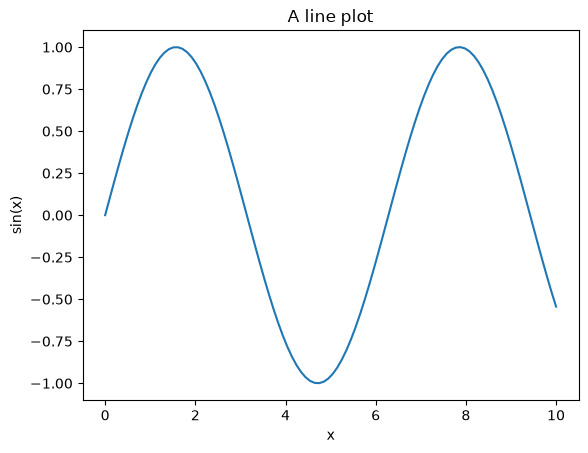

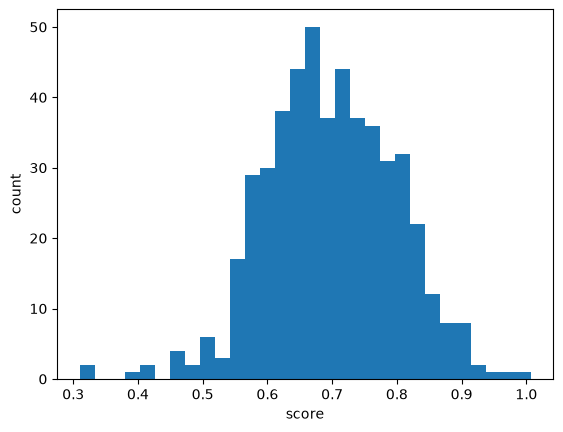

In [146]:
import matplotlib.pyplot as plt
import numpy as np

x = np.linspace(0, 10, 100)
plt.plot(x, np.sin(x))                 # a line plot of a curve
plt.xlabel("x"); plt.ylabel("sin(x)"); plt.title("A line plot")
plt.show()                             # opens or renders the figure

scores = np.random.default_rng(0).normal(0.7, 0.1, size=500)
plt.hist(scores, bins=30)              # a histogram of 500 scores
plt.xlabel("score"); plt.ylabel("count")
plt.show()

select Matplotlib's Agg backend, which renders straight to files, and save the figure with savefig instead of showing it.

In [147]:
import matplotlib
matplotlib.use("Agg")                  # render to files only; no display needed
import matplotlib.pyplot as plt
import seaborn as sns

tips = sns.load_dataset("tips")        # 244 real restaurant bills
print(tips.shape)                      # (244, 7)
sns.histplot(data=tips, x="total_bill", bins=20)
plt.savefig("tips_hist.png")

(244, 7)


The next block draws the four remaining plots of Table 1-6 on the same tips table, one call each, and saves every figure to its own file; plt.figure() opens a fresh canvas before each call, because Seaborn otherwise draws onto whatever axes are already open.

In [148]:
plt.figure()                                                 # a fresh canvas for each plot
sns.scatterplot(data=tips, x="total_bill", y="tip")          # two variables: is there a relationship?
plt.savefig("tips_scatter.png")

plt.figure()
sns.barplot(data=tips, x="day", y="total_bill")              # one value per category: the mean bill
plt.savefig("tips_bar.png")

plt.figure()
sns.boxplot(data=tips, x="day", y="total_bill")              # spread and outliers per category
plt.savefig("tips_box.png")

plt.figure()
corr = tips.corr(numeric_only=True)                          # 3 by 3: total_bill, tip, size
sns.heatmap(corr, annot=True)                                # a grid of values by color
plt.savefig("tips_heatmap.png")
print(corr.round(2))

            total_bill   tip  size
total_bill        1.00  0.68  0.60
tip               0.68  1.00  0.49
size              0.60  0.49  1.00


The block redraws the sine curve and the histogram of the first block as the two panels of one figure.

In [149]:
fig, axes = plt.subplots(1, 2, figsize=(8, 3))     # one figure holding a row of two axes
axes[0].plot(x, np.sin(x))                          # left panel: the sine curve of the first block
axes[0].set_xlabel("x"); axes[0].set_ylabel("sin(x)"); axes[0].set_title("A line plot")
axes[1].hist(scores, bins=30)                       # right panel: the 500 scores
axes[1].set_xlabel("score"); axes[1].set_ylabel("count"); axes[1].set_title("A histogram")
fig.tight_layout()                                  # nudge the panels so labels and titles do not collide
fig.savefig("two_panels.png", dpi=100)              # 100 dots per inch: 8 by 3 inches is 800 by 300 pixels
plt.close(fig)                                      # release it; pyplot otherwise keeps every figure open
print(type(fig).__name__, axes.shape, type(axes[0]).__name__)
print(plt.imread("two_panels.png").shape)           # (rows, columns, channels) of the saved image

Figure (2,) Axes
(300, 800, 4)


## 1.5.10 Jupyter notebooks: power and pitfalls

Typed alone in a cell, %timeit runs a statement many times and prints a one-line summary; the -o option also hands back an object holding the measurements behind it.

In [150]:
result = %timeit -o [i*i for i in range(1000)]
print(result.loops, result.repeat)                           # loops per run, number of runs
print([round(t * 1e6, 1) for t in result.timings])           # microseconds per loop, one value per run
print(round(result.average * 1e6, 1), round(result.stdev * 1e6, 1), round(result.best * 1e6, 1))

24.8 μs ± 261 ns per loop (mean ± std. dev. of 7 runs, 10,000 loops each)
10000 7
[25.4, 24.7, 24.7, 24.7, 24.7, 25.0, 24.7]
24.8 0.3 24.7


Its partner %time runs a statement once and reports the processor time and the elapsed wall clock time.

In [151]:
%time squares = [i*i for i in range(1_000_000)]
print(len(squares))                        # the assignment ran in the notebook's namespace, so it stays

CPU times: user 22.7 ms, sys: 4.25 ms, total: 27 ms
Wall time: 26.8 ms
1000000


The next four cells write a module with one function beside the notebook, import it, edit it the way you would in an editor, and call it again without a restart.

In [152]:
%load_ext autoreload

With the extension loaded, mode 2 checks for edited modules just before every cell; this cell writes the module, imports it, and calls it.

In [153]:
%autoreload 2
from pathlib import Path

Path("tipstats.py").write_text("def tip_rate(bill, tip):\n    return tip / bill\n")   # a one-function module
from tipstats import tip_rate              # the import style of 1.6.4: from module import name
print(round(tip_rate(tips["total_bill"], tips["tip"]).median(), 4))

0.1548


Edit the module, as you would in your editor.

In [154]:
# the edit you would make in your editor: return percentages instead of fractions
Path("tipstats.py").write_text("def tip_rate(bill, tip):\n    return 100 * tip / bill\n")

53

Call the same name again: autoreload looked for changes just before this cell started.

In [155]:
%autoreload 0
print(round(tip_rate(tips["total_bill"], tips["tip"]).median(), 4))   # the same name, the new code
Path("tipstats.py").unlink()                                          # remove the demo module

15.477


## 1.5.11 scikit-learn: classical machine learning

We use it throughout Chapters 4 through 9, but its flavor fits in a few lines, shown here on a real dataset that ships with the library: the Wisconsin diagnostic breast cancer data (569 tumors, 30 features; 0 = malignant, 1 = benign).

In [156]:
from sklearn.linear_model import LogisticRegression
from sklearn.datasets import load_breast_cancer

X, y = load_breast_cancer(return_X_y=True)   # 569 tumors, 30 features; 0 = malignant, 1 = benign
model = LogisticRegression(max_iter=5000).fit(X, y)   # the universal fit interface
print(model.predict(X[:3]))                  # [0 0 0]   predictions for three tumors
print(round(model.score(X, y), 2))           # 0.96      accuracy on the training data

[0 0 0]
0.96


## 1.5.12 The deep learning frameworks: PyTorch, TensorFlow, Keras, and JAX

As 2.2.1 will derive, the slope of x squared at x equals 3 is 6; PyTorch computes that for you.

In [157]:
import torch

x = torch.tensor(3.0, requires_grad=True)    # a tensor that tracks gradients
y = x ** 2
y.backward()                                  # automatic differentiation
print(x.grad)                                 # tensor(6.)   the derivative 2x at x=3

tensor(6.)


instead of tracking gradients through tensors, its jax.grad takes a Python function and returns a new function that computes the derivative.

In [158]:
import jax

grad_fn = jax.grad(lambda x: x ** 2)     # transform a function into its derivative
print(grad_fn(3.0))                      # 6.0

INFO: Unable to initialize backend 'tpu': INTERNAL: Failed to open libtpu.so: dlopen(libtpu.so, 0x0001): tried: 'libtpu.so' (no such file), '/System/Volumes/Preboot/Cryptexes/OSlibtpu.so' (no such file), '/opt/anaconda3/envs/aibook/bin/../lib/libtpu.so' (no such file), '/usr/lib/libtpu.so' (no such file, not in dyld cache), 'libtpu.so' (no such file)


INFO: Unable to initialize backend 'proxy': The 'proxy' backend requires the address of an IFRT Proxy server. Set it via the JAX_BACKEND_TARGET environment variable or the jax_backend_target config option, e.g. JAX_BACKEND_TARGET=grpc://localhost:29000.


6.0


For contrast, the same kind of model is defined, compiled, and run in Keras with almost no ceremony.

In [159]:
import numpy as np
from tensorflow import keras

keras.utils.set_random_seed(0)                # fix the random initial weights
model = keras.Sequential([                    # stack layers, the high-level Keras way
    keras.layers.Dense(64, activation="relu"),
    keras.layers.Dense(1),
])
model.compile(optimizer="adam", loss="mse")   # attach the optimizer and the loss
pred = model.predict(np.array([[1.0, 2.0, 3.0]]), verbose=0)
print(pred.shape, round(float(pred[0, 0]), 4))    # (1, 1) -0.8502

(1, 1) -0.8502


## 1.5.13 The wider ecosystem, and choosing a library

The example pins the exact model so the result is reproducible; the model downloads once, about 268 megabytes, and then loads from the local cache.

In [160]:
from transformers import pipeline

clf = pipeline("sentiment-analysis",
               model="distilbert/distilbert-base-uncased-finetuned-sst-2-english")
print(clf("This chapter made Python finally click for me."))
# [{'label': 'POSITIVE', 'score': 0.9956270456314087}]
print(clf("The loss exploded and the run crashed at epoch 40."))
# [{'label': 'NEGATIVE', 'score': 0.9995039701461792}]

W1101 18:23:56.142000 42046 site-packages/torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


INFO: HTTP Request: GET https://huggingface.co/api/models/distilbert/distilbert-base-uncased-finetuned-sst-2-english "HTTP/1.1 200 OK"


Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

INFO: HTTP Request: GET https://huggingface.co/api/models/distilbert/distilbert-base-uncased-finetuned-sst-2-english/tree/main/additional_chat_templates?recursive=false&expand=false "HTTP/1.1 404 Not Found"


INFO: HTTP Request: GET https://huggingface.co/api/models/distilbert/distilbert-base-uncased-finetuned-sst-2-english/tree/main?recursive=true&expand=false "HTTP/1.1 200 OK"


[{'label': 'POSITIVE', 'score': 0.9956270456314087}]
[{'label': 'NEGATIVE', 'score': 0.9995039701461792}]


## 1.6.1 Virtual environments and package management

`bash` block from 1.6.1 Virtual environments and package management (shown for reference, not executed):

    python -m venv .venv            # create an isolated environment in the .venv folder
    source .venv/bin/activate       # activate it  (on Windows: .venv\Scripts\activate)
    pip install numpy pandas        # these install only inside this environment
    pip freeze > requirements.txt   # record the exact versions for reproducibility

`toml` block from 1.6.1 Virtual environments and package management (shown for reference, not executed):

    [build-system]
    requires = ["setuptools>=69"]
    build-backend = "setuptools.build_meta"

    [project]
    name = "mlproject"
    version = "0.1.0"
    requires-python = ">=3.12"
    dependencies = ["numpy", "pandas"]

    [tool.setuptools]
    packages = ["src"]

`bash` block from 1.6.1 Virtual environments and package management (shown for reference, not executed):

    pip install -e .                                   # editable install of this project
    pip freeze --exclude-editable > requirements.txt   # pin the third-party versions

Installation also gives your project the same metadata every library carries, which Python reads at runtime:

In [161]:
# Every installed package carries the name and version that pip recorded
# at install time, and Python can read that metadata at runtime.
from importlib.metadata import version

print(version("numpy"))      # 2.5.4
print(version("pandas"))     # 2.3.3

2.5.4
2.3.3


## 1.6.2 Git essentials for machine learning projects

`bash` block from 1.6.2 Git essentials for machine learning projects (shown for reference, not executed):

    git init -b main                # start tracking this project, naming the first branch main
    echo "data/" > .gitignore       # tell Git to ignore the data folder
    echo ".venv/" >> .gitignore     # and the virtual environment, and so on
    git add .
    git commit -m "Initial commit"  # the first snapshot
    git checkout -b bigger-model    # branch off to try something risky
    # ... edit code, then ...
    git commit -am "Try a wider network"
    git checkout main               # main is exactly as you left it, the experiment is isolated

`bash` block from 1.6.2 Git essentials for machine learning projects (shown for reference, not executed):

    jupyter nbconvert --to script explore.ipynb   # writes explore.py: the code cells as one plain script
    pip install nbstripout
    nbstripout explore.ipynb                      # strip the outputs and execution counts, in place
    nbstripout --install                          # or let a Git filter strip every notebook as it is added

## 1.6.3 Project structure and clean, reusable code

`bash` block from 1.6.3 Project structure and clean, reusable code (shown for reference, not executed):

    pip install ruff black mypy
    ruff check src/          # lint: report unused imports, undefined names, style issues
    black src/               # format: rewrite the code to a single consistent style
    mypy src/                # type-check: verify the type hints are consistent

Ruff also ships a formatter, run as `ruff format src/`, which its documentation describes as a replacement for black that formats more than 99.9 percent of lines identically on large projects already formatted by black, so a project can run ruff alone for both jobs; the version with three tools shown here keeps the two roles visible.

The block documents the normalize function that 1.6.5 tests, reads the summary line back, prints the help page, and searches NumPy's array type for the arg functions of 1.5.4.

In [162]:
import numpy as np

def normalize(values):
    """Scale a list of numbers to the range 0 to 1.

    The smallest value maps to 0.0 and the largest to 1.0, and every
    other value keeps its relative place in between. Raises
    ZeroDivisionError when all the values are equal, because the
    range max - min is then zero.
    """
    lo, hi = min(values), max(values)
    return [(v - lo) / (hi - lo) for v in values]

print(normalize.__doc__.splitlines()[0])         # the summary line, the part tools show first
help(normalize)                                  # the signature, then the whole docstring
names = dir(np.ndarray)                          # every attribute name of NumPy's array type
print(len(names), [n for n in names if n.startswith("arg")])

Scale a list of numbers to the range 0 to 1.
Help on function normalize in module __main__:

normalize(values)
    Scale a list of numbers to the range 0 to 1.

    The smallest value maps to 0.0 and the largest to 1.0, and every
    other value keeps its relative place in between. Raises
    ZeroDivisionError when all the values are equal, because the
    range max - min is then zero.

168 ['argmax', 'argmin', 'argpartition', 'argsort']


## 1.6.4 From notebook monolith to modular code

When you find yourself about to copy a cell, that is the signal to extract it into a function in src.

In [163]:
# src/preprocessing.py  --  the reusable logic lives here, once
import pandas as pd

def clean(df: pd.DataFrame) -> pd.DataFrame:
    """Drop rows with missing values and tidy the column names."""
    df = df.dropna()
    df.columns = [c.lower().strip() for c in df.columns]
    return df

Illustrative project structure: this imports a hypothetical src package that does not exist on its own, so it is shown for reference rather than executed.

In [ ]:
# in the notebook  --  thin, just calling the tested, shared function
import seaborn as sns
from src.preprocessing import clean

raw_df = sns.load_dataset("penguins")   # the raw table of 1.5.2, gaps and all
df = clean(raw_df)     # not copy-pasted; one definition, imported everywhere

A relative import works only inside its package: run the file directly and Python raises ImportError: attempted relative import with no known parent package, because a directly launched script has no package identity. The next block builds its own temporary src package in a temporary folder, so it runs on its own and is executed in the notebook.

In [164]:
import sys
import shutil
import tempfile
from pathlib import Path

# Build the miniature project of 1.6.3 inside a temporary folder:
# project/src/__init__.py and project/src/preprocessing.py.
root = Path(tempfile.mkdtemp()) / "project"
(root / "src").mkdir(parents=True)
(root / "src" / "__init__.py").write_text("")
(root / "src" / "preprocessing.py").write_text(
    "def clean(text):\n    return text.lower().strip()\n"
)

# sys.path is the whole story: the ordered list of folders Python searches.
print(type(sys.path), len(sys.path))     # <class 'list'> 5    (count varies by machine)

# The temporary project is not on that list, so the notebook's import fails.
try:
    from src.preprocessing import clean
except ModuleNotFoundError as e:
    print(e)                             # No module named 'src'

# Put the project root at the front of the list; the same import now works.
sys.path.insert(0, str(root))
from src.preprocessing import clean
print(clean("  Age "))                   # age

import src.preprocessing                 # which file actually answered the import?
print(Path(src.preprocessing.__file__).name)   # preprocessing.py

sys.path.remove(str(root))               # undo the path change
shutil.rmtree(root.parent)               # and delete the temporary project

<class 'list'> 5
No module named 'src'
age
preprocessing.py


`bash` block from 1.6.4 From notebook monolith to modular code (shown for reference, not executed):

    python -m src.model      # run from the project root; -m puts that root on sys.path
    pip install -e .         # or install the project itself into the environment, editable

A circular import between data.py and features.py, fixed by deferring one import; the code at a module's top level runs once per process.

In [165]:
import sys
import shutil
import tempfile
from pathlib import Path

# Two modules that import each other, written to a temporary folder.
folder = Path(tempfile.mkdtemp())
(folder / "data.py").write_text(
    "from features import add_per_person       # data needs a feature helper...\n"
    "import seaborn as sns\n"
    "print('data.py: this line runs at import')  # a side effect, kept on purpose\n"
    "def load():\n"
    "    return add_per_person(sns.load_dataset('tips'))\n"
)
(folder / "features.py").write_text(
    "from data import load                     # ...and features imports data back\n"
    "def add_per_person(df):\n"
    "    df['per_person'] = df['total_bill'] / df['size']\n"
    "    return df\n"
    "def preview():\n"
    "    return load().head(3)\n"
)
sys.path.insert(0, str(folder))
try:
    import data
except ImportError as e:
    print(str(e).rsplit(" (", 1)[0])           # the message, minus the temporary file path
print("data" in sys.modules, "features" in sys.modules)   # False False

# The fix: features.py fetches load only when preview runs, after data.py has finished.
(folder / "features.py").write_text(
    "def add_per_person(df):\n"
    "    df['per_person'] = df['total_bill'] / df['size']\n"
    "    return df\n"
    "def preview():\n"
    "    from data import load                 # deferred: runs at call time, not import time\n"
    "    return load().head(3)\n"
)
import data                                    # runs data.py, which imports features
import data                                    # cached in sys.modules: nothing runs again
import features
print(round(data.load()["per_person"].mean(), 2))          # 7.89
print(features.preview()["per_person"].round(2).tolist())  # [8.49, 3.45, 7.0]

sys.path.remove(str(folder))                   # undo the path change,
for name in ("data", "features"):
    del sys.modules[name]                      # forget both modules,
del data, features                             # drop the two names,
shutil.rmtree(folder)                          # and delete the temporary project

cannot import name 'load' from partially initialized module 'data' (most likely due to a circular import)
False False
data.py: this line runs at import
7.89
[8.49, 3.45, 7.0]


The script needs a front door: argparse turns sys.argv into typed, validated, documented arguments. This train.py fits the logistic regression of 1.5.11 to the penguins table, splits with the seeded permutation of 1.5.4, writes the test accuracy to a JSON file, and logs its arguments; passing a list to parse_args makes it runnable inside a notebook.

In [166]:
import argparse, json, logging
from pathlib import Path
import numpy as np
import seaborn as sns
from sklearn.linear_model import LogisticRegression

logging.basicConfig(level=logging.INFO, format="%(levelname)s: %(message)s", force=True)

def build_parser():
    parser = argparse.ArgumentParser(prog="train.py", description="Fit a penguin species classifier.")
    parser.add_argument("--max-iter", type=int, default=1000, help="solver iterations (default: %(default)s)")
    parser.add_argument("--test-size", type=float, default=0.2, help="fraction held out for testing (default: %(default)s)")
    parser.add_argument("--seed", type=int, default=0, help="seed for the train and test split (default: %(default)s)")
    parser.add_argument("--out", default="metrics.json", help="file that receives the accuracy")
    return parser

def main(argv=None):                                   # None means: read the real command line, sys.argv[1:]
    args = build_parser().parse_args(argv)             # a namespace: args.max_iter, args.seed, ...
    logging.info("arguments: %s", vars(args))          # the exact settings go into the log
    penguins = sns.load_dataset("penguins").dropna()   # 333 birds with complete measurements
    X = np.array(penguins[["bill_length_mm", "bill_depth_mm", "flipper_length_mm"]])
    y = penguins["species"].to_numpy()
    idx = np.random.default_rng(args.seed).permutation(len(X))   # the seeded split of 1.5.4
    n_test = int(len(X) * args.test_size)
    test, train = idx[:n_test], idx[n_test:]
    model = LogisticRegression(max_iter=args.max_iter).fit(X[train], y[train])
    accuracy = float((model.predict(X[test]) == y[test]).mean())
    Path(args.out).write_text(json.dumps({"accuracy": round(accuracy, 4), "seed": args.seed}))
    print(f"test accuracy {accuracy:.4f} written to {args.out}")

main(["--seed", "1"])                                  # as if the shell had typed: python train.py --seed 1
main([])                                               # every default
print(Path("metrics.json").read_text())                # {"accuracy": 1.0, "seed": 0}
Path("metrics.json").unlink()                          # clean up

INFO: arguments: {'max_iter': 1000, 'test_size': 0.2, 'seed': 1, 'out': 'metrics.json'}


INFO: arguments: {'max_iter': 1000, 'test_size': 0.2, 'seed': 0, 'out': 'metrics.json'}


test accuracy 0.9697 written to metrics.json
test accuracy 1.0000 written to metrics.json
{"accuracy": 1.0, "seed": 0}


Two things come free with the parser: a help page, and an error for anything it does not recognize.

In [167]:
import contextlib, io

build_parser().print_help()                            # the usage text argparse writes for free

captured = io.StringIO()
try:
    with contextlib.redirect_stderr(captured):         # argparse sends its complaint to stderr
        build_parser().parse_args(["--seeed", "1"])    # a misspelled flag
except SystemExit as e:
    print("exit code", e.code)                         # exit code 2
print(captured.getvalue().splitlines()[-1])            # train.py: error: unrecognized arguments: --seeed 1

usage: train.py [-h] [--max-iter MAX_ITER] [--test-size TEST_SIZE]
                [--seed SEED] [--out OUT]

Fit a penguin species classifier.

options:
  -h, --help            show this help message and exit
  --max-iter MAX_ITER   solver iterations (default: 1000)
  --test-size TEST_SIZE
                        fraction held out for testing (default: 0.2)
  --seed SEED           seed for the train and test split (default: 0)
  --out OUT             file that receives the accuracy
exit code 2
train.py: error: unrecognized arguments: --seeed 1


`toml` block from 1.6.4 From notebook monolith to modular code (shown for reference, not executed):

    [project.scripts]
    train-penguins = "src.train:main"   # the command name, then the module and function it calls

## 1.6.5 Testing machine learning code

The deterministic parts of a pipeline, the preprocessing and feature functions, are straightforward to test directly, while the stochastic training itself is checked with sanity tests instead, such as confirming that the model can overfit a

In [168]:
# src/features.py
def normalize(values):
    """Scale a list of numbers to the range 0 to 1."""
    lo, hi = min(values), max(values)
    return [(v - lo) / (hi - lo) for v in values]

Illustrative project structure: this imports a hypothetical src package that does not exist on its own, so it is shown for reference rather than executed.

In [ ]:
# tests/test_features.py
from src.features import normalize

def test_normalize_scales_to_unit_range():
    assert normalize([10, 20, 30]) == [0.0, 0.5, 1.0]   # min->0, max->1, middle->0.5

def test_normalize_handles_negatives():
    assert normalize([-1, 0, 1]) == [0.0, 0.5, 1.0]

Example 1-16 puts all three to work in one file. The suite stands on its own: the two functions under test sit in this file instead of src/preprocess.py, so the cell runs in the notebook; it only defines the fixture and the tests and prints nothing. The tests run under the pytest command shown after it.

In [169]:
# tests/test_preprocess.py
import sys
from unittest.mock import MagicMock

import numpy as np
import pytest

# The code under test. In a real project these two functions live in
# src/preprocess.py and the tests import them; they sit here so this
# file runs on its own.

def standardize(x):
    """Give every column mean 0 and standard deviation 1."""
    return (x - x.mean(axis=0)) / x.std(axis=0)

def load_model(name):
    """Stands in for a 500 MB download from a model hub."""
    raise RuntimeError("tests must never hit the network")

def embed(texts):
    model = load_model("big-encoder")     # the expensive call we will fake
    return [model.encode(t) for t in texts]

THIS_MODULE = sys.modules[__name__]       # in a real project: import src.preprocess

# A fixture: one small seeded array, rebuilt fresh for each test that asks.

@pytest.fixture
def small_data():
    rng = np.random.default_rng(0)        # seeded: every run sees identical data
    return rng.normal(loc=5.0, scale=2.0, size=(20, 3))

def test_standardize_zero_mean(small_data):
    z = standardize(small_data)
    assert np.allclose(z.mean(axis=0), 0.0)   # every column now has mean 0

def test_standardize_unit_std(small_data):
    z = standardize(small_data)
    assert np.allclose(z.std(axis=0), 1.0)    # and standard deviation 1

# Parametrize: one test body, run once per shape and dtype combination.

@pytest.mark.parametrize("dtype", [np.float32, np.float64])
@pytest.mark.parametrize("shape", [(4, 2), (50, 3), (200, 8)])
def test_standardize_keeps_shape_and_dtype(shape, dtype):
    x = np.arange(shape[0], dtype=dtype).reshape(-1, 1) * np.ones(shape, dtype=dtype)
    z = standardize(x)
    assert z.shape == shape and z.dtype == dtype

# monkeypatch plus mock: swap the download for an instant fake, one test only.

def test_embed_without_network(monkeypatch):
    fake = MagicMock()
    fake.encode.side_effect = lambda text: [float(len(text))]  # "embedding" = length
    monkeypatch.setattr(THIS_MODULE, "load_model", lambda name: fake)
    assert embed(["cat", "bird"]) == [[3.0], [4.0]]  # 3 letters, then 4
    fake.encode.assert_called_with("bird")           # the mock recorded its calls

`bash` block from 1.6.5 Testing machine learning code (shown for reference, not executed):

    python -m pytest tests/test_preprocess.py -q

## 1.6.6 Configuration and secrets from environment variables

The helper below turns a missing secret into an error that names it; the demo writes its file as demo.env, so that running it can never overwrite a real .env.

In [170]:
import os
from pathlib import Path
from dotenv import load_dotenv

def get_secret(name):
    """Return the environment variable name, or fail with an error that names it."""
    value = os.environ.get(name)
    if not value:                                   # unset or empty: stop before any work starts
        raise RuntimeError(f"{name} is not set; export it in the shell or add it to .env")
    return value

try:
    get_secret("DEMO_API_KEY")
except RuntimeError as err:
    print(err)

Path("demo.env").write_text("DEMO_API_KEY=sk-demo-123456\nDEMO_BATCH_SIZE=64\n")   # stands in for .env
print(load_dotenv("demo.env"))                      # True: at least one variable was set
key = get_secret("DEMO_API_KEY")
print(len(key), key[:3] + "...")                    # report a length and a prefix, never the secret
batch = os.environ["DEMO_BATCH_SIZE"]
print(repr(batch), int(batch) * 2)                  # environment values are always strings
for name in ("DEMO_API_KEY", "DEMO_BATCH_SIZE"):
    os.environ.pop(name)                            # unset them again, so a rerun starts clean
Path("demo.env").unlink()

DEMO_API_KEY is not set; export it in the shell or add it to .env
True
14 sk-...
'64' 128


## 1.6.7 Seeding every random number generator

By hand, the smallest generator worth studying is the linear congruential recurrence x_next = (a * x + c) mod m.

In [171]:
def toy_generator(seed, n, a=5, c=3, m=16):
    """Return the first n states of x_next = (a * x + c) % m, starting from the seed."""
    states, x = [], seed
    for _ in range(n):
        x = (a * x + c) % m
        states.append(x)
    return states

print(toy_generator(7, 6), toy_generator(7, 6) == toy_generator(7, 6))
print(len(set(toy_generator(7, 16))), toy_generator(8, 6))

[6, 1, 8, 11, 10, 5] True
16 [11, 10, 5, 12, 15, 14]


The helper seeds the three global states that the practitioner's stack relies on and returns a fresh Generator for your own draws.

In [172]:
import random
import numpy as np
import seaborn as sns
import torch
from sklearn.model_selection import train_test_split

def set_seed(seed):
    """Seed Python's, NumPy's global, and PyTorch's generators; return a fresh NumPy Generator."""
    random.seed(seed)                      # the random module: shuffle, choice, sample
    np.random.seed(seed)                   # NumPy's legacy global state, which libraries fall back on
    try:
        import torch
        torch.manual_seed(seed)            # PyTorch's generators on the CPU and every GPU
    except ImportError:                    # a project without PyTorch can keep the same helper
        pass
    return np.random.default_rng(seed)     # your own draws keep using a Generator, as 1.5.4 advises

penguins = sns.load_dataset("penguins").dropna()        # the 333 birds of 1.5.2

def one_run():
    """Split the birds, roll a die, and draw a tensor, each from its library's global state."""
    _, test = train_test_split(penguins, test_size=0.2)   # no random_state: it draws from np.random
    return list(test.index[:4]), random.randint(1, 6), round(torch.rand(1).item(), 4)

set_seed(0); first = one_run()
set_seed(0); second = one_run()
set_seed(1); third = one_run()
print(first)
print(first == second, third)

([62, 60, 283, 107], 4, 0.4963)
True ([65, 276, 186, 198], 2, 0.7576)


## 1.7.1 Identity, truthiness, None, and the frozenset

This matters because confusing == with is is a classic bug, since two equal lists are not the same object, and because the truthiness rules let conditions read naturally once you trust them.

In [173]:
a = [1, 2, 3]
b = [1, 2, 3]
print(a == b)        # True   equal contents
print(a is b)        # False  different objects in memory
print(a is a)        # True   the same object

x = None
print(x is None)     # True   the correct way to test for None

for value in [0, "", [], None, 42, "hi"]:
    print(repr(value), "->", bool(value))   # 0, "", [], None are falsy; the rest truthy

True
False
True
True
0 -> False
'' -> False
[] -> False
None -> False
42 -> True
'hi' -> True


A NumPy array with more than one element has no single truth value, so if arr: raises ValueError rather than guessing; ask the question you mean with any, all, or size, and use .empty for pandas objects.

In [174]:
import numpy as np
import pandas as pd

try:
    if np.array([1, 2]):                     # which element should decide? NumPy refuses to guess
        pass
except ValueError as e:
    print("ValueError:", e)
# ValueError: The truth value of an array with more than one element is ambiguous. Use a.any() or a.all()

arr = np.array([0, 0, 3])
print(arr.any(), arr.all(), arr.size > 0)    # True False True   ask the question you mean
print(pd.DataFrame().empty, pd.Series([1, 2]).empty)   # True False   pandas objects: use .empty

ValueError: The truth value of an array with more than one element is ambiguous. Use a.any() or a.all()
True False True
True False


CPython shares the integers from -5 to 256 and interned strings, so compare values with == and keep is for None.

In [175]:
import sys

a, b = int("256"), int("256")      # built at run time, the way numbers parsed from a file are
print(a == b, a is b)              # True True     256 lies in CPython's preallocated block
c, d = int("257"), int("257")
print(c == d, c is d)              # True False    257 is a new object every time

split = "train"                    # a short literal, which CPython has interned
built = "".join(["tr", "ain"])     # the same text, assembled at run time
print(split == built, split is built)   # True False
print(sys.intern(built) is split)       # True     intern hands back the one shared copy

True True
True False
True False
True


A frozenset is a hashable set that ignores order, here the key of a cache of complete rows per column subset of the penguins table.

In [176]:
import seaborn as sns

penguins = sns.load_dataset("penguins")          # 344 birds, a few measurements missing
complete = {}                                    # column subset -> number of complete rows
for cols in [("bill_length_mm", "sex"), ("sex", "bill_length_mm"), ("flipper_length_mm",)]:
    key = frozenset(cols)                        # hashable, and blind to the order of the names
    if key not in complete:                      # compute each subset only once
        complete[key] = int(penguins[list(cols)].notna().all(axis=1).sum())
print(len(complete))                             # 2     the first two tuples name one subset
print(complete[frozenset({"sex", "bill_length_mm"})], complete[frozenset({"flipper_length_mm"})])   # 333 342
try:
    complete[{"sex"}] = 0                        # a plain set can change, so it cannot be a key
except TypeError as e:
    print("TypeError:", e)                       # TypeError: unhashable type: 'set'

2
333 342
TypeError: unhashable type: 'set'


## 1.7.2 Unpacking, the ternary, and the walrus

These read more cleanly than the longer forms and appear throughout real code, so recognizing them is part of fluency.

In [177]:
point = (3, 4)
x, y = point                       # unpack into two names
print(x, y)                        # 3 4

first, *rest = [10, 20, 30, 40]
print(first, rest)                 # 10 [20, 30, 40]

a, b = 1, 2
a, b = b, a                        # swap with no temporary variable
print(a, b)                        # 2 1

grade = "pass" if 0.7 >= 0.5 else "fail"     # ternary expression
print(grade)                       # pass

data = [1, 2, 3, 4, 5]
if (n := len(data)) > 3:           # walrus: assign n and test it in one step
    print(f"the list has {n} items")   # the list has 5 items

3 4
10 [20, 30, 40]
2 1
pass
the list has 5 items


## 1.7.3 Comprehensions in full

This matters because the right comprehension expresses an intent in one readable line, and the generator expression in particular lets you feed a huge computed sequence into something like sum without the memory cost of a list.

In [178]:
words = ["cat", "dog", "bird", "cat"]
lengths = {w: len(w) for w in words}         # dict comprehension
print(lengths)                               # {'cat': 3, 'dog': 3, 'bird': 4}

unique_lengths = {len(w) for w in words}     # set comprehension (duplicates collapse)
print(unique_lengths)                        # {3, 4}

total = sum(len(w) for w in words)           # generator expression, lazy, no list built
print(total)                                 # 13

{'cat': 3, 'dog': 3, 'bird': 4}
{3, 4}
13


The generator's saving measured, and a generator read twice: the values that 1.7.3 states in its prose.

In [179]:
import sys

print(sys.getsizeof([n for n in range(1_000_000)]))   # 8448728   the list and its array of references only
print(sys.getsizeof(n for n in range(1_000_000)))     # 192       a generator holds no items
print(sys.getsizeof(n for n in range(10)))            # 192       the same size whatever the range
g = (len(w) for w in words)
print(sum(g), sum(g))                                 # 13 0      the first sum used the generator up

8448728
192
192
13 0


## 1.7.4 More on classes: properties and class methods

These matter because framework classes use all of them, and properties in particular are how a library exposes a computed quantity as if it were a stored field.

In [180]:
class Circle:
    pi = 3.14159                       # class attribute, shared by all circles

    def __init__(self, radius):
        self.radius = radius           # instance attribute, one per object

    @property
    def area(self):                    # accessed as circle.area, with no parentheses
        return Circle.pi * self.radius * self.radius

    @staticmethod
    def describe():                    # no self: just a function grouped with the class
        return "the set of points a fixed distance from a center"

    @classmethod
    def unit(cls):                     # an alternative constructor: the unit circle
        return cls(1.0)

c = Circle(2.0)
print(round(c.area, 4))                # 12.5664   computed, accessed like an attribute
print(Circle.unit().radius)            # 1.0       built through the classmethod
print(Circle.describe())               # the set of points a fixed distance from a center

12.5664
1.0
the set of points a fixed distance from a center


Underneath, properties and ordinary methods work because they are descriptors, objects with a __get__ method that the class-level search invokes, and that single mechanism implements bound methods, @property, @classmethod, and @staticmethod

In [181]:
class LazyConfig:
    def __init__(self, **settings):
        self._settings = settings      # a plain dict of named values

    def __getattr__(self, name):       # called ONLY when normal lookup fails
        if name in self._settings:
            return self._settings[name]
        raise AttributeError(f"no setting named {name!r}")

cfg = LazyConfig(lr=0.01, epochs=50)
print(cfg.lr)                          # 0.01    invented by the hook
print(cfg.epochs)                      # 50
cfg.lr = 0.001                         # now a real instance attribute
print(cfg.lr)                          # 0.001   found normally, hook never runs
try:
    cfg.momentum
except AttributeError as e:
    print("AttributeError:", e)        # AttributeError: no setting named 'momentum'

0.01
50
0.001
AttributeError: no setting named 'momentum'


__setattr__ runs on every assignment: a base class that registers Param attributes, the way nn.Module registers layers and parameters.

In [182]:
class Param:
    """A stand-in for a learnable weight: a list of numbers."""
    def __init__(self, values):
        self.values = list(values)

class Module:
    def __init__(self):
        object.__setattr__(self, "_params", {})       # make the registry without calling our hook

    def __setattr__(self, name, value):               # runs for every self.name = value
        if isinstance(value, Param):
            if "_params" not in self.__dict__:
                raise AttributeError("cannot assign a Param before Module.__init__() call")
            self._params[name] = value                # register it, as nn.Module does
        object.__setattr__(self, name, value)         # then store it like any attribute

    def parameters(self):
        return list(self._params.values())

class TinyNet(Module):
    def __init__(self):
        super().__init__()                            # the registry has to exist first
        self.w = Param([0.5, -0.2])
        self.b = Param([0.1])
        self.label = "tiny"                           # not a Param: stored, not registered

net = TinyNet()
print(list(net._params), sum(len(p.values) for p in net.parameters()))   # ['w', 'b'] 3
print(net.label, net.w.values)                                            # tiny [0.5, -0.2]

class Forgetful(Module):
    def __init__(self):
        self.w = Param([1.0])                         # no super().__init__() first
try:
    Forgetful()
except AttributeError as e:
    print("AttributeError:", e)

['w', 'b'] 3
tiny [0.5, -0.2]
AttributeError: cannot assign a Param before Module.__init__() call


The real nn.Module registers fc1 and fc2 through its own __setattr__, so parameters() finds all 257 numbers.

In [183]:
import torch.nn as nn

class Net(nn.Module):
    def __init__(self):
        super().__init__()
        self.fc1 = nn.Linear(30, 8)        # 30 inputs, one per breast cancer feature of 1.5.11
        self.fc2 = nn.Linear(8, 1)

net = Net()
print([name for name, _ in net.named_children()])     # ['fc1', 'fc2']
print([name for name, _ in net.named_parameters()])   # ['fc1.weight', 'fc1.bias', 'fc2.weight', 'fc2.bias']
print(sum(p.numel() for p in net.parameters()))       # 257

['fc1', 'fc2']
['fc1.weight', 'fc1.bias', 'fc2.weight', 'fc2.bias']
257


Declaring __slots__ = ("x", "y") in the class body tells Python the complete set of attribute names in advance, so instances store their values in fixed slots and skip the dictionary entirely.

In [184]:
import sys

class PointDict:                       # ordinary class: each instance owns a __dict__
    def __init__(self, x, y):
        self.x = x
        self.y = y

class PointSlots:
    __slots__ = ("x", "y")             # fixed attribute set, no per-instance __dict__
    def __init__(self, x, y):
        self.x = x
        self.y = y

p, q = PointDict(1.0, 2.0), PointSlots(1.0, 2.0)
print(sys.getsizeof(p) + sys.getsizeof(p.__dict__))   # 344   object plus its dict
print(sys.getsizeof(q))                               # 48    no dict at all
try:
    q.z = 3.0                          # slots also forbids surprise attributes
except AttributeError as e:
    print("AttributeError:", e)        # AttributeError: 'PointSlots' object has no attribute 'z' and no __dict__ for setting new attributes

344
48
AttributeError: 'PointSlots' object has no attribute 'z' and no __dict__ for setting new attributes


## 1.7.5 More on errors: else, finally, and custom exceptions

This matters because precise, named exceptions make a system's failures legible, and the else and finally clauses express the common pattern of "do this only on success" and "always do this at the end."

In [185]:
class InsufficientDataError(Exception):
    """Raised when there are too few samples to proceed."""

def average(values):
    if len(values) == 0:
        raise InsufficientDataError("need at least one value")
    return sum(values) / len(values)

for batch in [[2, 4, 6], []]:
    try:
        result = average(batch)
    except InsufficientDataError as e:
        print("error:", e)
    else:
        print("average:", result)      # runs only when no exception was raised
    finally:
        print("done with this batch")   # always runs

average: 4.0
done with this batch
error: need at least one value
done with this batch


from err stores the original in the new exception's __cause__.

In [186]:
import traceback

class DataError(Exception):
    """Raised when a record cannot be turned into a training example."""

def parse_label(record):
    try:
        return int(record["label"])          # the low-level step that can fail
    except ValueError as err:
        # translate into the pipeline's own error, keeping the original as the cause
        raise DataError(f"bad record {record['id']}") from err

try:
    parse_label({"id": "r42", "label": "positve??"})
except DataError as e:
    print(type(e).__name__, "->", e)         # DataError -> bad record r42
    print("cause:", type(e.__cause__).__name__, "->", e.__cause__)
    # cause: ValueError -> invalid literal for int() with base 10: 'positve??'
    report = "".join(traceback.format_exception(e))   # the full two-part traceback as text
    print([line for line in report.splitlines() if "cause" in line][0])
    # The above exception was the direct cause of the following exception:

DataError -> bad record r42
cause: ValueError -> invalid literal for int() with base 10: 'positve??'
The above exception was the direct cause of the following exception:


the original lands in __context__ instead of __cause__, and the linking sentence becomes "During handling of the above exception, another exception occurred:".

In [187]:
import traceback

class DataError(Exception):
    """The same custom error, this time raised without from."""

def parse_label_sloppy(record):
    try:
        return int(record["label"])
    except ValueError:
        raise DataError(f"bad record {record['id']}")   # a new exception, no from

try:
    parse_label_sloppy({"id": "r7", "label": "seven"})
except DataError as e:
    print(e.__cause__)                     # None   no declared cause
    print(type(e.__context__).__name__)    # ValueError   Python kept the original anyway
    report = "".join(traceback.format_exception(e))
    print([line for line in report.splitlines() if "occurred" in line][0])
    # During handling of the above exception, another exception occurred:

None
ValueError
During handling of the above exception, another exception occurred:


Seven common exceptions, each provoked and printed with the class it inherits from.

In [188]:
import importlib

attempts = [
    lambda: int("3.5"),                                  # the right type, an unusable value
    lambda: "accuracy " + 0.91,                          # an operation the types do not support
    lambda: {"lr": 0.01}["momentum"],                    # a key the dictionary lacks
    lambda: [0.9, 0.8][2],                               # a position past the end
    lambda: [0.9, 0.8].shape,                            # a list is not an array
    lambda: open("no_such_file.csv"),                    # a path that does not exist
    lambda: importlib.import_module("no_such_package"),  # a package that is not installed
]
for attempt in attempts:
    try:
        attempt()
    except Exception as e:                               # every one of them is an Exception
        parent = type(e).__mro__[1].__name__             # the class it inherits from
        print(f"{type(e).__name__:<20}{parent:<13}{e}")

ValueError          Exception    invalid literal for int() with base 10: '3.5'
TypeError           Exception    can only concatenate str (not "float") to str
KeyError            LookupError  'momentum'
IndexError          LookupError  list index out of range
AttributeError      Exception    'list' object has no attribute 'shape'
FileNotFoundError   OSError      [Errno 2] No such file or directory: 'no_such_file.csv'
ModuleNotFoundError ImportError  No module named 'no_such_package'


A bare except catches KeyboardInterrupt, which derives from BaseException, while except Exception lets Ctrl+C through.

In [189]:
print(issubclass(ValueError, Exception), issubclass(KeyboardInterrupt, Exception))   # True False
print([cls.__name__ for cls in KeyboardInterrupt.__mro__])   # ['KeyboardInterrupt', 'BaseException', 'object']

def run_steps(catch):
    """Five steps of a toy training loop; the user presses Ctrl+C during step 2."""
    finished = []
    for step in range(5):
        try:
            if step == 2:
                raise KeyboardInterrupt                  # what Ctrl+C raises in a running program
            finished.append(step)
        except catch:                                    # a handler meant for a flaky data read
            print(f"step {step}: handled, carrying on")
    return finished

print(run_steps(BaseException))                          # what a bare except: catches
try:
    run_steps(Exception)
except KeyboardInterrupt:
    print("Ctrl+C stopped the run")

True False
['KeyboardInterrupt', 'BaseException', 'object']
step 2: handled, carrying on
[0, 1, 3, 4]
Ctrl+C stopped the run


An assert disappears under python -O, so it must never validate input.

In [190]:
import os
import subprocess
import sys

script = "print('debug', __debug__); assert 1.2 <= 1.0, 'accuracy above 1'; print('assert skipped')"
plain = {**os.environ, "PYTHON_COLORS": "0"}           # ask the child Python for uncolored messages
for flags in ([], ["-O"]):
    run = subprocess.run([sys.executable, *flags, "-c", script],
                         capture_output=True, text=True, env=plain)
    error = run.stderr.strip().splitlines()[-1] if run.stderr.strip() else "no error"
    print(" ".join(["python", *flags]), "|", run.stdout.strip().replace("\n", "; "), "|", error)

python | debug True | AssertionError: accuracy above 1
python -O | debug False; assert skipped | no error


Warnings: record a ConvergenceWarning on the breast cancer data, silence that one category inside catch_warnings, and turn warnings into errors.

In [191]:
import warnings
from sklearn.datasets import load_breast_cancer
from sklearn.exceptions import ConvergenceWarning
from sklearn.linear_model import LogisticRegression

X, y = load_breast_cancer(return_X_y=True)
with warnings.catch_warnings(record=True) as caught:    # collect warnings instead of printing them
    warnings.simplefilter("always")                     # and keep every one, repeats included
    LogisticRegression(max_iter=10).fit(X, y)           # far too few solver iterations
print(len(caught), caught[0].category.__name__)         # 1 ConvergenceWarning
print(str(caught[0].message).splitlines()[0])

with warnings.catch_warnings(record=True) as caught:    # every filter set inside is undone on exit
    warnings.simplefilter("always")
    warnings.filterwarnings("ignore", category=ConvergenceWarning)   # goes to the front, so it wins
    LogisticRegression(max_iter=10).fit(X, y)
    print(len(caught))                                  # 0
    warnings.simplefilter("error")                      # from here on, a warning raises instead
    try:
        warnings.warn("learning rate looks too high", UserWarning)
    except UserWarning as w:
        print("raised:", w)                             # raised: learning rate looks too high

1 ConvergenceWarning
lbfgs failed to converge after 10 iteration(s) (status=1):


0
raised: learning rate looks too high


## 1.7.6 Scope tools: closures, global, nonlocal, and the main guard

These matter because closures explain how functions carry private state, and the main guard is the standard way to make a file usable both as an importable module and as a runnable script.

In [192]:
def make_counter():
    count = 0
    def increment():
        nonlocal count             # rebind the enclosing count, not create a new local
        count += 1
        return count
    return increment               # a closure that carries its own private count

counter = make_counter()
print(counter(), counter(), counter())   # 1 2 3

if __name__ == "__main__":
    print("this line runs only when the file is executed directly")

1 2 3
this line runs only when the file is executed directly


The global keyword is the module-level twin of nonlocal: assigning to a name inside a function makes that name local unless a declaration says otherwise, so without the keyword an increment fails before it can run.

In [193]:
calls = 0                              # a module-level counter
hits = 0

def record_call():
    global calls                       # rebind the module-level name, not a new local
    calls += 1

def broken():
    hits += 1                          # looks like it updates the module-level hits...

print(calls)                           # 0
record_call(); record_call()
print(calls)                           # 2
try:
    broken()
except UnboundLocalError as e:
    print("UnboundLocalError:", e)     # UnboundLocalError: cannot access local variable 'hits' where it is not associated with a value

0
2
UnboundLocalError: cannot access local variable 'hits' where it is not associated with a value


The LEGB rule: Python searches the Local, Enclosing, Global, and Built-in scopes in that order and stops at the first match.

In [194]:
rate = 0.1                                 # G: a module-level name

def make_trainer():
    rate = 0.01                            # E: the enclosing scope of the two functions below
    def step():
        return rate                        # no local rate, so the search stops at E
    def warmup_step():
        rate = 0.001                       # L: a local that hides the enclosing rate
        return rate
    return step(), warmup_step(), len("abc")   # len lives only in B, the built-ins

print(make_trainer())                      # (0.01, 0.001, 3)
print(rate)                                # 0.1   the module-level name was never touched

max = 0.93                                 # G: a notebook stores its best accuracy as max
try:
    max([0.81, 0.93, 0.88])                # the search stops at G and finds the float
except TypeError as e:
    print("TypeError:", e)                 # TypeError: 'float' object is not callable
del max                                    # delete the global; the search reaches B again
print(max([0.81, 0.93, 0.88]))             # 0.93

(0.01, 0.001, 3)
0.1
TypeError: 'float' object is not callable
0.93


## 1.7.7 Reading and writing files

This matters because every real pipeline loads data from files and saves results back, and doing it inside a with block is the habit that prevents leaked file handles.

In [195]:
from pathlib import Path
import json

path = Path("notes.txt")
with open(path, "w") as f:             # write mode replaces the file
    f.write("first line\n")
    f.write("second line\n")

with open(path) as f:                  # read mode is the default
    content = f.read()
print(content.strip())                 # first line / second line

config = {"lr": 0.01, "epochs": 50}
with open("config.json", "w") as f:
    json.dump(config, f)               # write a dict as JSON
with open("config.json") as f:
    loaded = json.load(f)              # read JSON back into a dict
print(loaded["epochs"])                # 50

path.unlink(); Path("config.json").unlink()    # clean up the temporary files

first line
second line


50


pathlib: joining with /, mkdir with parents, glob as a loader of three real seaborn tables saved as CSV, and the parts of a path.

In [196]:
import shutil
import tempfile
from pathlib import Path, PurePosixPath, PureWindowsPath
import pandas as pd
import seaborn as sns

# Pure paths never touch the disk, so both spellings print on any operating system.
print(PurePosixPath("data") / "raw" / "tips.csv")       # data/raw/tips.csv
print(PureWindowsPath("data") / "raw" / "tips.csv")     # data\raw\tips.csv
print("data/raw/" + "/tips.csv", PurePosixPath("data/raw/") / "tips.csv")   # string glue, then a clean join

root = Path(tempfile.mkdtemp())                         # a scratch project folder
raw = root / "data" / "raw"
raw.mkdir(parents=True, exist_ok=True)                  # creates data and data/raw in one call
for name in ("tips", "penguins", "titanic"):            # three real seaborn tables, saved as CSV
    sns.load_dataset(name).to_csv(raw / f"{name}.csv", index=False)

tables = {p.stem: pd.read_csv(p) for p in sorted(raw.glob("*.csv"))}   # the whole loader
print({name: df.shape for name, df in tables.items()})
tips_csv = raw / "tips.csv"
print(tips_csv.name, tips_csv.stem, tips_csv.suffix, tips_csv.parent.name)   # tips.csv tips .csv raw
print(tips_csv.exists(), (raw / "iris.csv").exists())                       # True False
print(tips_csv.read_text(encoding="utf-8").splitlines()[0])                 # the header row
shutil.rmtree(root)                                     # delete the scratch folder

data/raw/tips.csv
data\raw\tips.csv
data/raw//tips.csv data/raw/tips.csv


{'penguins': (344, 7), 'tips': (244, 7), 'titanic': (891, 15)}
tips.csv tips .csv raw
True False
total_bill,tip,sex,smoker,day,time,size


By hand, the four characters of café become five bytes under UTF-8, because é needs two.

In [197]:
text = "café"
data = text.encode("utf-8")            # str -> bytes, using the UTF-8 rule
print(type(data), len(text), len(data))   # <class 'bytes'> 4 5
print(data)                            # b'caf\xc3\xa9'   the e-acute is the byte pair C3 A9
print(data.decode("utf-8"))            # café         bytes -> str restores the text exactly

try:
    data.decode("ascii")               # the wrong rule for these bytes
except UnicodeDecodeError as e:
    print("UnicodeDecodeError:", e.reason)   # ordinal not in range(128)

with open("note.txt", "w", encoding="utf-8") as f:   # name the encoding, always
    f.write(text)
with open("note.txt", encoding="utf-8") as f:
    print(f.read())                    # café
from pathlib import Path; Path("note.txt").unlink()  # clean up

<class 'bytes'> 4 5
b'caf\xc3\xa9'
café
UnicodeDecodeError: ordinal not in range(128)
café


Unicode normalization (NFC and NFD) and case folding before counting: one surname typed four ways becomes one word.

In [198]:
import unicodedata
from collections import Counter

composed = "Garc\u00eda"            # the accented i as one code point, U+00ED
decomposed = "Garci\u0301a"         # a plain i followed by U+0301, the combining acute accent
print(composed, decomposed, composed == decomposed)          # García García False
print(len(composed), len(decomposed))                        # 6 7
print([unicodedata.name(ch) for ch in decomposed[4:6]])      # ['LATIN SMALL LETTER I', 'COMBINING ACUTE ACCENT']
print(unicodedata.normalize("NFC", decomposed) == composed)  # True
print(len(unicodedata.normalize("NFD", composed)))           # 7

print("Straße".lower(), "Straße".casefold())                 # straße strasse
print("Straße".lower() == "STRASSE".lower(), "Straße".casefold() == "STRASSE".casefold())   # False True

def fold(s):
    """A key for caseless matching: decompose, case fold, decompose again (Unicode Standard D145)."""
    return unicodedata.normalize("NFD", unicodedata.normalize("NFD", s).casefold())

names = [composed, decomposed, "GARC\u00cdA", "garc\u00eda"]   # one surname, typed four ways
print(len(Counter(names)))                                     # 4
print(Counter(fold(n) for n in names))                         # Counter({'garcía': 4})

García García False
6 7
['LATIN SMALL LETTER I', 'COMBINING ACUTE ACCENT']
True
7
straße strasse
False True
4
Counter({'garcía': 4})


## 1.7.8 Regular expressions

Table 1-9 lists the building blocks you will use most.

In [199]:
import re

text = "Contact: alice@example.com or call 555-1234."
print(re.findall(r"\d+", text))               # ['555', '1234']   runs of digits
match = re.search(r"\w+@\w+\.\w+", text)
print(match.group())                           # alice@example.com
print(re.sub(r"\d", "#", text))                # every digit replaced by a #

['555', '1234']
alice@example.com
Contact: alice@example.com or call ###-####.


A raw string keeps backslashes as written, so the pattern \b reaches the regex engine as a word boundary instead of a backspace.

In [200]:
import re

print(len("\b"), len(r"\b"))                    # 1 2       a backspace versus a backslash and a b
text = "the cat sat on the concatenated mat"
print(re.findall(r"\bcat\b", text))             # ['cat']   \b, a word boundary, skips "concatenated"
print(re.findall("\bcat\b", text))              # []        Python turned each "\b" into a backspace first

1 2
['cat']
[]


Capture groups, named groups, alternation, and search versus match versus fullmatch, on a made-up training log line.

In [201]:
import re

line = "epoch 12/50 loss=0.4120 acc=0.803"                   # a made-up training log line
m = re.search(r"loss=(\d+\.\d+) acc=(\d+\.\d+)", line)       # two capture groups
print(m.group(0))                                            # loss=0.4120 acc=0.803   the whole match
print(m.group(1), m.group(2), m.groups())                    # 0.4120 0.803 ('0.4120', '0.803')
m = re.search(r"epoch (?P<epoch>\d+)/(?P<total>\d+)", line)  # two named groups
print(m.group("epoch"), m.groupdict())                       # 12 {'epoch': '12', 'total': '50'}

print(re.match(r"loss", line), re.search(r"loss", line).group())   # None loss   match looks only at the start
print(bool(re.fullmatch(r"\d{1,3}", "803")), bool(re.fullmatch(r"\d{1,3}", "8030")))   # True False
print(re.findall(r"epochs?", "1 epoch, 5 epochs"))           # ['epoch', 'epochs']   ? makes the s optional
print(re.findall(r"(loss|acc)=(\d\.\d+)", line))             # [('loss', '0.4120'), ('acc', '0.803')]
print(re.findall(r"(?:loss|acc)=(\d\.\d+)", line))           # ['0.4120', '0.803']

loss=0.4120 acc=0.803
0.4120 0.803 ('0.4120', '0.803')
12 {'epoch': '12', 'total': '50'}
None loss
True False
['epoch', 'epochs']
[('loss', '0.4120'), ('acc', '0.803')]
['0.4120', '0.803']


Flags, re.compile, re.split, greedy versus lazy quantifiers, and re.DOTALL.

In [202]:
import re

log = "epoch 1 loss=0.69\nEPOCH 2 loss=0.41\nepoch 3 loss=0.30"     # three made-up log lines
epoch_line = re.compile(r"^epoch (\d+)", re.IGNORECASE | re.MULTILINE)   # compile once, reuse
print(epoch_line.findall(log))                    # ['1', '2', '3']
print(re.findall(r"^epoch (\d+)", log))           # ['1']   no flags: one start, and case matters

print(re.split(r"[,;]\s*", "lr=0.01, epochs=50;batch=32"))   # ['lr=0.01', 'epochs=50', 'batch=32']

html = "<b>loss</b> and <b>acc</b>"
print(re.findall(r"<b>(.*)</b>", html))           # ['loss</b> and <b>acc']   greedy: as much as possible
print(re.findall(r"<b>(.*?)</b>", html))          # ['loss', 'acc']           lazy: as little as possible
note = "<b>two\nlines</b>"
print(re.search(r"<b>(.*?)</b>", note))           # None   . stops at the newline
print(repr(re.search(r"<b>(.*?)</b>", note, re.DOTALL).group(1)))   # 'two\nlines'

['1', '2', '3']
['1']
['lr=0.01', 'epochs=50', 'batch=32']
['loss</b> and <b>acc']
['loss', 'acc']
None
'two\nlines'


## 1.7.9 A tour of the standard library

Table 1-10 lists the ones a practitioner reaches for most, several of which earlier sections already used.

In [203]:
from datetime import date

print(date(2026, 1, 1).strftime("%A"))          # Thursday   the weekday of that date

Thursday


A named tuple is a tuple whose positions also have names, so best.acc and best[1] reach the same value.

In [204]:
from collections import namedtuple
from typing import NamedTuple
from sklearn.datasets import load_breast_cancer
from sklearn.neighbors import KNeighborsClassifier

class Run(NamedTuple):                    # the class form: a name and a type hint for each position
    k: int
    acc: float

X, y = load_breast_cancer(return_X_y=True)                # the 569 tumors of 1.5.11
runs = []
for k in (1, 3, 5, 7):                    # how many similar tumors get a vote
    knn = KNeighborsClassifier(n_neighbors=k).fit(X[:400], y[:400])   # fit on the first 400
    runs.append(Run(k, round(knn.score(X[400:], y[400:]), 3)))       # accuracy on the last 169

ranked = sorted(runs, key=lambda r: r.acc, reverse=True)
best = ranked[0]
k, acc = best                             # unpacks like any tuple
print(ranked)
print(k, acc, best[1] == best.acc)        # a position and a name reach the same value
print(best._asdict())                     # a plain dictionary, ready for json.dumps
print(best._replace(acc=round(best.acc, 2)), best)   # a new record; best itself never changes
print(best == tuple(best))                # True: it is still a tuple

Shape = namedtuple("Shape", ["rows", "cols"])         # the factory form from collections
print(Shape._make(X.shape), Shape._fields)            # _make builds a record from any iterable

import torch
out = torch.max(torch.tensor([[1, 5], [4, 2]]), dim=0)  # the largest value in each column
print(out.values, out.indices, isinstance(out, tuple))

[Run(k=5, acc=0.935), Run(k=7, acc=0.929), Run(k=3, acc=0.923), Run(k=1, acc=0.917)]
5 0.935 True
{'k': 5, 'acc': 0.935}
Run(k=5, acc=0.94) Run(k=5, acc=0.935)
True
Shape(rows=569, cols=30) ('rows', 'cols')


tensor([4, 5]) tensor([1, 0]) True


## 1.7.10 Unpacking at the call site, and merging collections

Spreading a dictionary of hyperparameters into a model constructor, or merging a dictionary of defaults with a dictionary of user overrides, are everyday moves that this syntax makes a single line.

In [205]:
def add(a, b, c):
    return a + b + c

print(add(*[1, 2, 3]))            # 6    * spreads the list into a, b, c
print(add(**{"a": 10, "b": 20, "c": 30}))   # 60   ** spreads the dict by keyword

print([*[1, 2], *[3, 4]])         # [1, 2, 3, 4]      merge lists

6
60
[1, 2, 3, 4]


## 1.7.11 The functional toolkit: functools and itertools

Freezing an argument to specialize a function, folding a list down to a single value, caching expensive results, and enumerating every combination or pairing of items are all one line with these modules, and recognizing them makes a great d

In [206]:
from functools import partial, reduce

def power(base, exp):
    return base ** exp

square = partial(power, exp=2)          # freeze exp=2 to make a new function
print(square(5))                        # 25
print(reduce(lambda acc, x: acc * x, [1, 2, 3, 4, 5]))   # 120   fold by multiplying
print(reduce(lambda acc, x: acc + x, [1, 2, 3, 4], 100)) # 110   with a starting value

25
120
110


The itertools side enumerates structured collections.

In [207]:
from itertools import combinations, permutations, product, chain, accumulate

print(list(combinations([1, 2, 3], 2)))   # [(1, 2), (1, 3), (2, 3)]   order ignored
print(list(permutations([1, 2, 3], 2)))   # 6 ordered pairs            order matters
print(list(product([0, 1], repeat=2)))    # [(0,0),(0,1),(1,0),(1,1)]  every combination
print(list(chain([1, 2], [3, 4])))        # [1, 2, 3, 4]               glue end to end
print(list(accumulate([1, 2, 3, 4])))     # [1, 3, 6, 10]              running sum

[(1, 2), (1, 3), (2, 3)]
[(1, 2), (1, 3), (2, 1), (2, 3), (3, 1), (3, 2)]
[(0, 0), (0, 1), (1, 0), (1, 1)]
[1, 2, 3, 4]
[1, 3, 6, 10]


## 1.7.12 Structural pattern matching with match

Writing that dispatch as a match is both clearer and safer than a tangle of if statements that each pick apart the value by hand.

In [208]:
def describe(command):
    match command:
        case "start":
            return "starting"
        case ("move", x, y):            # match a 3-item sequence and bind x and y
            return f"move to {x},{y}"
        case {"action": act}:           # match a dict that has an 'action' key
            return f"action={act}"
        case _:                         # the wildcard: matches anything
            return "unknown"

print(describe("start"))                # starting
print(describe(("move", 3, 4)))         # move to 3,4
print(describe({"action": "jump"}))     # action=jump
print(describe(42))                     # unknown
print(describe(["move", 3, 4]))         # move to 3,4   a list fits the sequence pattern too

starting
move to 3,4
action=jump
unknown
move to 3,4


Class patterns, OR patterns, guards, and as-captures on a dataclass.

In [209]:
from dataclasses import dataclass

@dataclass
class Point:
    x: float
    y: float

def where(item):
    match item:
        case Point(x=0, y=0):                    # class pattern: a Point whose x and y are both 0
            return "origin"
        case Point(x=0) | Point(y=0):            # OR pattern: either alternative will do
            return "on an axis"
        case Point(x=x, y=y) if x == y:          # guard: the pattern binds x and y, then the if must hold
            return f"on the diagonal at {x}"
        case ("stop" | "quit") as word:          # as binds the whole matched value to a name
            return f"stop requested by {word!r}"
        case _:
            return "somewhere else"

for item in [Point(0, 0), Point(0, 5), Point(2, 2), Point(2, 3), "quit", {"x": 0, "y": 0}]:
    print(where(item))

origin
on an axis
on the diagonal at 2
somewhere else
stop requested by 'quit'
somewhere else


## 1.7.13 Enums and richer type hints

An enum replaces error-prone string literals like "train" and "test", scattered through the code and easy to misspell, with names the editor can complete and the checker can verify, and precise type hints let mypy from 1.6.3 flag a function

In [210]:
from enum import Enum

class Split(Enum):
    TRAIN = "train"
    VAL = "val"
    TEST = "test"

print(Split.TRAIN.value)       # train          the underlying value
print(Split("val"))            # Split.VAL       look a member up by its value
print(Split.TRAIN is Split.TRAIN)   # True       members are unique singletons

train
Split.VAL
True


The richer hints document a function's contract.

In [211]:
from typing import Optional, Callable

def find(xs: list[int], target: int) -> Optional[int]:
    for i, x in enumerate(xs):
        if x == target:
            return i
    return None                # Optional[int] warns callers this can be None

def apply_twice(f: Callable[[int], int], x: int) -> int:
    return f(f(x))

print(find([10, 20, 30], 20))         # 1
print(find([10, 20, 30], 99))         # None
print(apply_twice(lambda v: v + 3, 10))   # 16

1
None
16


Which values count as Iterable, Sequence, or Mapping under isinstance.

In [212]:
from collections.abc import Iterable, Mapping, Sequence
import numpy as np

kinds = (list, Iterable, Sequence, Mapping)
samples = {"list": [0.9, 0.8], "tuple": (0.9, 0.8), "range": range(3), "str": "acc",
           "ndarray": np.array([0.9, 0.8]), "dict": {"acc": 0.9}, "float": 0.9}
print(" " * 8 + "".join(f"{k.__name__:<10}" for k in kinds).rstrip())
for name, x in samples.items():
    print((f"{name:<8}" + "".join(f"{str(isinstance(x, k)):<10}" for k in kinds)).rstrip())

        list      Iterable  Sequence  Mapping
list    True      True      True      False
tuple   False     True      True      False
range   False     True      True      False
str     False     True      True      False
ndarray False     True      False     False
dict    False     True      False     True
float   False     False     False     False


A TypeVar ties the output type to the input type: first and mean_score on the breast cancer data and the fold scores of cross_val_score.

In [213]:
from collections.abc import Mapping, Sequence
from typing import TypeVar
from sklearn.datasets import load_breast_cancer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_score

T = TypeVar("T")                                   # stands for whatever type the caller brings

def first(items: Sequence[T]) -> T:                # a Sequence of T goes in, one T comes out
    return items[0]

def mean_score(scores: Mapping[str, float]) -> float:   # any mapping from names to floats
    return sum(scores.values()) / len(scores)

cancer = load_breast_cancer()
print(first(list(cancer.feature_names)), first(cancer.data.shape))   # mean radius 569
folds = cross_val_score(LogisticRegression(max_iter=5000), cancer.data, cancer.target, cv=5)
by_fold = {f"fold{k}": float(s) for k, s in enumerate(folds, start=1)}
print(round(mean_score(by_fold), 4))                                 # 0.9508

mean radius 569


0.9508


What the type variable buys shows only under a type checker, which this notebook does not run. Save the TypeVar version of first with the line first([569, 30]).upper() and run mypy on the file: mypy 2.4.1, the current release as of November 2026, reports "int" has no attribute "upper". With the signature def first(items: Sequence) -> object, mypy rejects first(["train", "val"]).upper() with "object" has no attribute "upper".

## 1.7.14 Saving objects: pickle and joblib

You fit once, save the fitted object, and load it in the service that makes predictions, which is the save-and-load pattern behind every deployed model and the bridge to deployment in Chapter 28.

In [214]:
import pickle

config = {"lr": 0.01, "layers": [64, 32], "name": "mlp"}
blob = pickle.dumps(config)        # serialize the object to bytes
restored = pickle.loads(blob)      # deserialize the bytes back to an object
print(restored == config)          # True
print(restored["layers"])          # [64, 32]

True
[64, 32]


For a real model you use joblib.dump and joblib.load: save the breast cancer classifier of 1.5.11 to a temporary file, load it back, and check that the loaded model is the fitted one.

In [215]:
import tempfile
import joblib
import numpy as np
from pathlib import Path
from sklearn.datasets import load_breast_cancer
from sklearn.linear_model import LogisticRegression

X, y = load_breast_cancer(return_X_y=True)
model = LogisticRegression(max_iter=5000).fit(X, y)      # the fit of 1.5.11
path = Path(tempfile.mkdtemp()) / "model.joblib"
joblib.dump(model, path)                                  # one call writes the whole fitted object
loaded = joblib.load(path)                                # and one call rebuilds it
print(np.array_equal(loaded.coef_, model.coef_))          # True   the learned weights came back exactly
print(loaded.predict(X[:3]))                              # [0 0 0]   the same predictions as 1.5.11
path.unlink()                                             # clean up

True
[0 0 0]


## 1.8 Hands-on lab: a mini data-analysis project end to end

Example 1-17 loads the table, keeps the eight columns this lab needs, and asks for the shape and the column report.

In [216]:
import pandas as pd
import seaborn as sns

df = sns.load_dataset("titanic")[
    ["survived", "pclass", "sex", "age", "sibsp", "parch", "fare", "embark_town"]
]
print(df.shape)     # (891, 8)
df.info()           # info() prints its report itself and returns None

(891, 8)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 8 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   survived     891 non-null    int64  
 1   pclass       891 non-null    int64  
 2   sex          891 non-null    object 
 3   age          714 non-null    float64
 4   sibsp        891 non-null    int64  
 5   parch        891 non-null    int64  
 6   fare         891 non-null    float64
 7   embark_town  889 non-null    object 
dtypes: float64(2), int64(4), object(2)
memory usage: 55.8+ KB


Since the question is about the fare, we summarize it next.

In [217]:
print(df["fare"].describe().round(2))
# count    891.00
# mean      32.20
# std       49.69
# min        0.00
# 25%        7.91
# 50%       14.45
# 75%       31.00
# max      512.33
# Name: fare, dtype: float64

count    891.00
mean      32.20
std       49.69
min        0.00
25%        7.91
50%       14.45
75%       31.00
max      512.33
Name: fare, dtype: float64


The fares are British pounds of 1912. Kaggle's data dictionary calls the column only "Passenger fare"; the unit comes from the Vanderbilt titanic3 table, which documents its fare in British pounds (hbiostat.org/data/repo/ctitanic3), and every lab row has a titanic3 twin with the same class, sex, sibsp, parch, and fare.

In [218]:
t3 = pd.read_csv("https://hbiostat.org/data/repo/titanic3.csv")      # the Vanderbilt titanic3 table, 1,309 passengers
key = ["pclass", "sex", "sibsp", "parch", "fare"]
found = df[key].merge(t3[key].drop_duplicates(), how="left", indicator=True)
print(t3.shape, len(found), (found["_merge"] == "left_only").sum())   # (1309, 14) 891 0

(1309, 14) 891 0


The minimum of 0.00 deserves a second look, because a zero price is either a recorded fact or a missing value in disguise, and this block asks which.

In [219]:
zero_fare = df[df["fare"] == 0]
print(len(zero_fare))                                             # 15
print(zero_fare["sex"].unique(), zero_fare["embark_town"].unique())   # ['male'] ['Southampton']
print(zero_fare["pclass"].value_counts().sort_index().tolist())   # [5, 6, 4]   in first, second, third class

15
['male'] ['Southampton']
[5, 6, 4]


they are 0.2 percent of the data, and inventing a port of departure would be a heavier assumption than losing two rows.

In [220]:
print(df["age"].median())                          # 28.0
df["age"] = df["age"].fillna(df["age"].median())   # impute missing ages
df = df.dropna(subset=["embark_town"])             # drop the 2 rows with no port
print(df.shape, df.isna().sum().sum())             # (889, 8) 0

28.0
(889, 8) 0


Now we explore, asking the data our question through the grouping of 1.5.7.

In [221]:
print(df.groupby("pclass")["fare"].mean().round(2))
# pclass
# 1    84.19
# 2    20.66
# 3    13.68
# Name: fare, dtype: float64
print(df.groupby("embark_town")["fare"].mean().round(2))
# embark_town
# Cherbourg      59.95
# Queenstown     13.28
# Southampton    27.08
# Name: fare, dtype: float64

pclass
1    84.19
2    20.66
3    13.68
Name: fare, dtype: float64
embark_town
Cherbourg      59.95
Queenstown     13.28
Southampton    27.08
Name: fare, dtype: float64


The Cherbourg average is not because the French port charged more; a larger share of the passengers boarding there held first class tickets, which a cross tabulation of port against class makes visible.

In [222]:
print(pd.crosstab(df["embark_town"], df["pclass"], normalize="index").round(2))
# pclass          1     2     3
# embark_town
# Cherbourg    0.51  0.10  0.39
# Queenstown   0.03  0.04  0.94
# Southampton  0.20  0.25  0.55

pclass          1     2     3
embark_town                  
Cherbourg    0.51  0.10  0.39
Queenstown   0.03  0.04  0.94
Southampton  0.20  0.25  0.55


A family-size column, the passenger plus their sibsp and parch companions, lets us compute the price per person, and it feeds a correlation check with the corr method that 1.5.9 used for its heatmap.

In [223]:
df["family_size"] = df["sibsp"] + df["parch"] + 1        # count the passenger too
df["fare_per_person"] = (df["fare"] / df["family_size"]).round(2)
print(df[["pclass", "age", "family_size", "fare"]].corr()["fare"].round(3))
# pclass        -0.548
# age            0.094
# family_size    0.219
# fare           1.000
# Name: fare, dtype: float64

pclass        -0.548
age            0.094
family_size    0.219
fare           1.000
Name: fare, dtype: float64


Now surface the passengers the question asked about.

In [224]:
print(df.nlargest(5, "fare")[["pclass", "sex", "family_size", "fare", "fare_per_person"]])
#      pclass     sex  family_size      fare  fare_per_person
# 258       1  female            1  512.3292           512.33
# 679       1    male            2  512.3292           256.16
# 737       1    male            1  512.3292           512.33
# 27        1    male            6  263.0000            43.83
# 88        1  female            6  263.0000            43.83

     pclass     sex  family_size      fare  fare_per_person
258       1  female            1  512.3292           512.33
679       1    male            2  512.3292           256.16
737       1    male            1  512.3292           512.33
27        1    male            6  263.0000            43.83
88        1  female            6  263.0000            43.83


Finally we visualize the fare distribution, which a single number cannot convey, producing Figure 1-5.

In [225]:
import matplotlib
matplotlib.use("Agg")                  # render to a file, as in 1.5.9
import matplotlib.pyplot as plt

plt.hist(df["fare"], bins=40)
plt.xlabel("fare (1912 pounds)"); plt.ylabel("number of passengers")
plt.title("Distribution of ticket fares in the lab data")
plt.savefig("fare_hist.png")

## 1.9 Interview questions and coding exercises
Each coding exercise comes with a starter block that runs as given; the full solutions are in Appendix H and in 01_chapter1_coding_solutions.py.

Coding exercise 1, Two-sum: the starter block.

In [226]:
def two_sum(nums, target):
    """Return the indices [i, j] of two numbers in nums that add up to target, or None."""
    ...

print(two_sum([2, 7, 11, 15], 9))

None


Coding exercise 2, Check a palindrome: the starter block.

In [227]:
def is_palindrome(s):
    """Return True if s reads the same forwards and backwards."""
    ...

print(is_palindrome("racecar"), is_palindrome("hello"))

None None


Coding exercise 3, First nonrepeating character: the starter block.

In [228]:
def first_unique(s):
    """Return the first character of s that appears exactly once, or None if there is none."""
    ...

print(first_unique("aabbcde"))

None


Coding exercise 4, Find duplicates: the starter block.

In [229]:
def has_duplicate(items):
    """Return True if any value occurs more than once in items, in a single pass."""
    ...

print(has_duplicate([1, 2, 3, 2]))

None


Coding exercise 5, FizzBuzz: the starter block.

In [230]:
def fizzbuzz(n):
    """Print 1 to n, with Fizz for multiples of 3, Buzz for multiples of 5, and FizzBuzz for both."""
    ...

fizzbuzz(5)

Coding exercise 6, Best tipping day: the starter block.

In [231]:
import seaborn as sns

tips = sns.load_dataset("tips")                     # 244 real restaurant bills

def tip_pct_by_day(tips):
    """Keep the dinner bills, add a tip percentage column, and return its mean per day, highest first."""
    ...

print(tips.shape, list(tips.columns))

(244, 7) ['total_bill', 'tip', 'sex', 'smoker', 'day', 'time', 'size']


Coding exercise 7, Fares in a grid: the starter block.

In [232]:
import matplotlib
matplotlib.use("Agg")                               # render to files only, as in 1.5.9
import matplotlib.pyplot as plt
import seaborn as sns

titanic = sns.load_dataset("titanic")               # the passenger table of the 1.8 lab

def fare_grid(titanic):
    """Return the pivot table of mean fare, with pclass as the rows and sex as the columns."""
    ...

def save_grouped_bars(table, path):
    """Draw the table as a grouped bar chart and save it to path as a PNG."""
    ...

print(titanic[["pclass", "sex", "fare"]].head(3))

   pclass     sex     fare
0       3    male   7.2500
1       1  female  71.2833
2       3  female   7.9250


Coding exercise 8, Engineer and compare: the starter block.

In [233]:
import seaborn as sns

titanic = sns.load_dataset("titanic")

def add_child_and_alone(t):
    """Fill missing ages with the median, then add boolean columns child (age under 16) and alone (family size of 1)."""
    ...

print(titanic.shape, titanic["age"].isna().sum())

(891, 15) 177


Coding exercise 9, A first fit: the starter block.

In [234]:
import seaborn as sns
from sklearn.linear_model import LinearRegression

tips = sns.load_dataset("tips")

def fit_tip_on_bill(tips):
    """Fit LinearRegression predicting tip from total_bill and return the fitted model."""
    ...

print(tips[["total_bill", "tip"]].head(3))

   total_bill   tip
0       16.99  1.01
1       10.34  1.66
2       21.01  3.50


Coding exercise 10, Retry and restore: the starter block.

In [235]:
import functools
import numpy as np

def retry(times=3):
    """A decorator factory: retry the decorated function up to times attempts, then raise."""
    ...

class Precision:
    """Set NumPy's print precision to n inside a with block and restore the old value on exit."""
    def __init__(self, n):
        ...
    def __enter__(self):
        ...
    def __exit__(self, exc_type, exc, tb):
        ...

values = np.array([1 / 3, 2 / 3])
print(values)                                       # the default precision, before any block

[0.33333333 0.66666667]


Coding exercise 11, Linked list surgery: the starter block.

In [236]:
class Node:                                         # the node of 1.4.2
    def __init__(self, value, nxt=None):
        self.value = value
        self.next = nxt

def reverse_iterative(head):
    """Reverse the list with a loop and return the new head."""
    ...

def reverse_recursive(head):
    """Reverse the list by recursion and return the new head."""
    ...

def has_cycle(head):
    """Return True if following next pointers ever loops back, using two pointers at different speeds."""
    ...

head = Node(1, Node(2, Node(3)))                    # 1 -> 2 -> 3
print(reverse_iterative(head), has_cycle(head))

None None


Coding exercise 12, Sorting, slow and fast: the starter block.

In [237]:
import random
import sys
import timeit

def insertion_sort(xs):
    """Return a new list holding the values of xs in ascending order, built by insertion."""
    ...

def quicksort(xs):
    """The first element pivot quicksort of 1.4.8."""
    ...

def quicksort_random(xs):
    """Quicksort with its pivot chosen by random.randrange."""
    ...

data = list(range(5000))                            # already sorted
shuffled = data[:]
random.seed(0)
random.shuffle(shuffled)                            # the same numbers in a random order
print(len(data), shuffled[:5])

5000 [2795, 4151, 597, 2932, 3289]


Coding exercise 13, Maze and components: the starter block.

In [238]:
from collections import deque

maze = [
    "S.#.....",
    ".##.###.",
    "....#...",
    ".##...#G",
]
graph = {"A": ["B"], "B": ["A", "C"], "C": ["B"], "D": ["E"], "E": ["D"], "F": []}

def shortest_path(maze):
    """Return the number of steps on a shortest route from S to G, or None if G cannot be reached."""
    ...

def count_components(graph):
    """Return the number of connected components of an undirected graph given as adjacency lists."""
    ...

print(len(maze), len(maze[0]), shortest_path(maze), count_components(graph))

4 8 None None


Coding exercise 14, Pool and loop: the starter block.

In [239]:
import asyncio
import math
import time
from concurrent.futures import ThreadPoolExecutor, ProcessPoolExecutor

def download(i):                                    # one simulated network read: a 0.1 second wait
    time.sleep(0.1)
    return f"file{i}"

def count_primes(lo, hi):
    """Count the primes p with lo <= p < hi in pure Python, the CPU bound job."""
    ...

async def download_async(i):
    """The asynchronous twin of download, which waits with asyncio.sleep."""
    ...

if __name__ == "__main__":                          # pool workers import this file again: guard the launch
    print(download(0), count_primes(0, 100))

file0 None


Coding exercise 15, Profile the lab: the starter block.

In [240]:
import cProfile
import io
import pstats
import pandas as pd
import seaborn as sns

titanic = sns.load_dataset("titanic")[["pclass", "fare"]]      # the raw 891 rows of the lab
big = pd.concat([titanic] * 100, ignore_index=True)             # the same table stacked 100 times

def mean_fare_pandas(df):
    """Return the mean fare per class, computed with a groupby."""
    ...

def mean_fare_loop(df):
    """Return the mean fare per class, computed with a pure Python dictionary loop."""
    ...

print(titanic.shape, big.shape)

(891, 2) (89100, 2)


Coding exercise 16, Join the class names: the starter block.

In [241]:
import pandas as pd
import seaborn as sns

titanic = sns.load_dataset("titanic")[["pclass", "fare"]]

def mean_fare_by_class_name(titanic, lookup, how="inner"):
    """Merge the class names onto titanic with the given join and return the mean fare per name."""
    ...

print(titanic.shape, sorted(titanic["pclass"].unique().tolist()))

(891, 2) [1, 2, 3]


Coding exercise 17, Two pipelines, one disagreement: the starter block.

In [242]:
from transformers import pipeline

SENTIMENT_MODEL = "distilbert/distilbert-base-uncased-finetuned-sst-2-english"   # pinned in 1.5.13
LABELS = ["bug", "feature request", "question"]
notes = [
    "The validation loss stopped improving after epoch 12.",
    "Please let the trainer resume from a saved checkpoint.",
    # write eight more short sentences about a training run here
]

def label_sentiment(notes):
    """Run the pinned sentiment pipeline on notes and return one (label, score) pair per note."""
    ...

def label_topics(notes, labels):
    """Run a zero-shot-classification pipeline with a small pinned model; return each note's top label and score."""
    ...

print(len(notes), LABELS)

2 ['bug', 'feature request', 'question']
